# Create design matrix
- Map response as a regressor
- Then split it up based on valence and volatility
- See how they are correlated amongst each other

In [7]:
import utils

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
import math
import os
from nilearn.glm.first_level import make_first_level_design_matrix, check_design_matrix
from nilearn.plotting import plot_design_matrix, plot_design_matrix_correlation

#from analyses_behavioural.modelling.martin_modelling.plots import subjectively_correct

plt.rcParams.update(plt.rcParamsDefault)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.width', 150)

In [8]:
# Make output folder
output_dir = f'/Volumes/kenvdzee/Documents/phd_1_analysis/plots/TUS/fMRI/design_matrices'
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

In [9]:
# To load the trigger files
def find_trigger_file(pattern: str, folder: str = '.') -> pd.DataFrame:
    folder = Path(folder)
    matches = list(folder.glob(pattern))

    if len(matches) == 0:
        raise FileNotFoundError(f"No files matching '{pattern}' in {folder}")
    if len(matches) > 1:
        raise ValueError(f"Multiple files match '{pattern}': {matches}")

    return pd.read_csv(matches[0], delimiter=';')

In [10]:
# Preparation
plot_range = [0, 6]

# Loads the datapath, subject_id's and session numbers
raw_output_path = '/Volumes/project/3025011.02/raw/'
unique_subject_ids = [39, 48, 49, 52, 53, 54, 55, 57, 58, 60, 61, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 76, 77, 78, 79, 81, 82, 83, 85, 86, 87, 88, 92, 94, 95]
unique_sessions = [2, 3, 4]

# Now create a boxcar for every single trial
boxcar_duration = 1.7
# Define the maximum displacement for volumes that are excluded [mm]
framewise_displacement_limit = 2.5 # Same as voxel size
# Filter out objectively incorrect trials
filter_out_incorrect_trials = True

# Load and combine the datasets
combined_dataframe = utils.import_functions.main(raw_output_path, unique_subject_ids, unique_sessions, fmri_analysis=True)

sub-085 did not complete session-04
sub-086 did not complete session-03
sub-086 did not complete session-04
sub-087 did not complete session-02
sub-087 did not complete session-03
sub-087 did not complete session-04
sub-088 did not complete session-02
sub-088 did not complete session-03
sub-088 did not complete session-04
sub-092 did not complete session-02
sub-092 did not complete session-03
sub-092 did not complete session-04
sub-094 did not complete session-03
sub-094 did not complete session-04
sub-095 did not complete session-02
sub-095 did not complete session-03
sub-095 did not complete session-04
These participants will be excluded: {'sub-059_session-03'}



/Volumes/kenvdzee/Documents/phd_1_analysis/utils/import_functions.py:774: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  removed_trials['removed_trial'] = 'removed_trial'


In [11]:
print(combined_dataframe)

       trial  emotional_cue_time  response objectively_correct subjectively_correct  response_time   RT_s  feedback_time  stimuli_type  \
0          0        1.787063e+09     avoid                Even                False   1.787063e+09  0.660   1.787063e+09             1   
1          1        1.787063e+09     avoid                Even                False   1.787063e+09  0.546   1.787063e+09             1   
2          2        1.787063e+09     avoid                Even                False   1.787063e+09  0.600   1.787063e+09             2   
3          3        1.787063e+09  approach                Even                 True   1.787063e+09  0.550   1.787063e+09             2   
4          4        1.787063e+09  approach                Even                False   1.787063e+09  0.498   1.787063e+09             2   
5          5        1.787063e+09     avoid                Even                 True   1.787063e+09  0.267   1.787063e+09             1   
6          6        1.787063e+09  

Creating event file for subject 39 and session 2
30
60
90
120
150
182
214
240
270
300
330
360
390
422
450
451
                                  trial_type        onset   duration
0                                        NaN     5.040725   0.829213
1                                        NaN     5.040725   0.829213
2                              removed_trial     5.040725   0.829213
3                                        NaN     8.405389   0.713184
4                                        NaN     8.405389   0.713184
5                              removed_trial     8.405389   0.713184
6                                        NaN    13.338497   0.767464
7                                        NaN    13.338497   0.767464
8                              removed_trial    13.338497   0.767464
9                                        NaN    17.777318   0.715625
10                                       NaN    17.777318   0.715625
11                             removed_trial    17.777318   0.

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


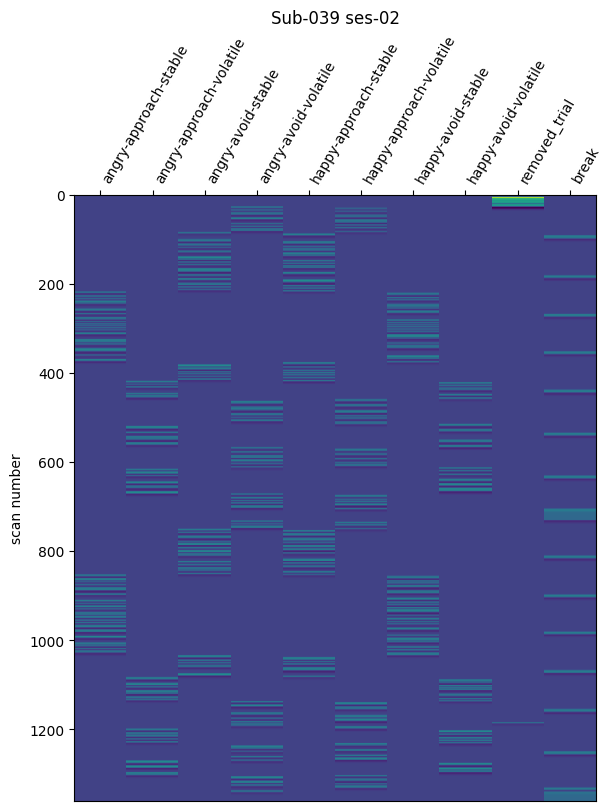

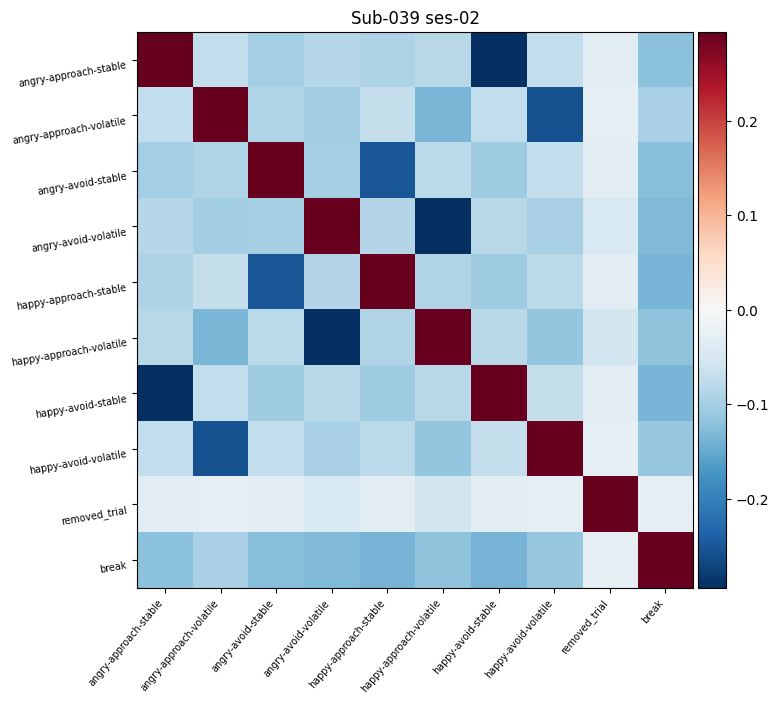

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 39 and session 3
34
62
90
120
150
180
210
246
270
306
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.094326   0.906356
1                                        NaN     5.094326   0.906356
2                              removed_trial     5.094326   0.906356
3                                        NaN     8.463781   0.769924
4                                        NaN     8.463781   0.769924
5                              removed_trial     8.463781   0.769

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


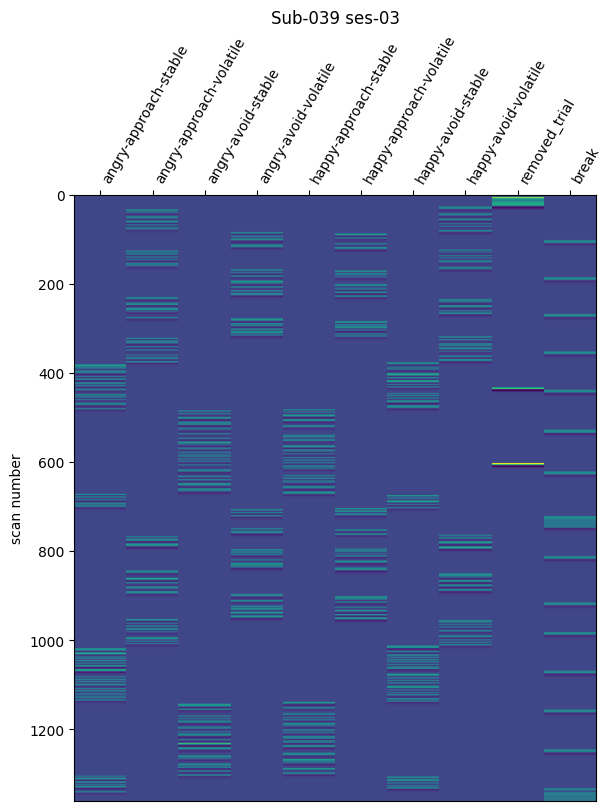

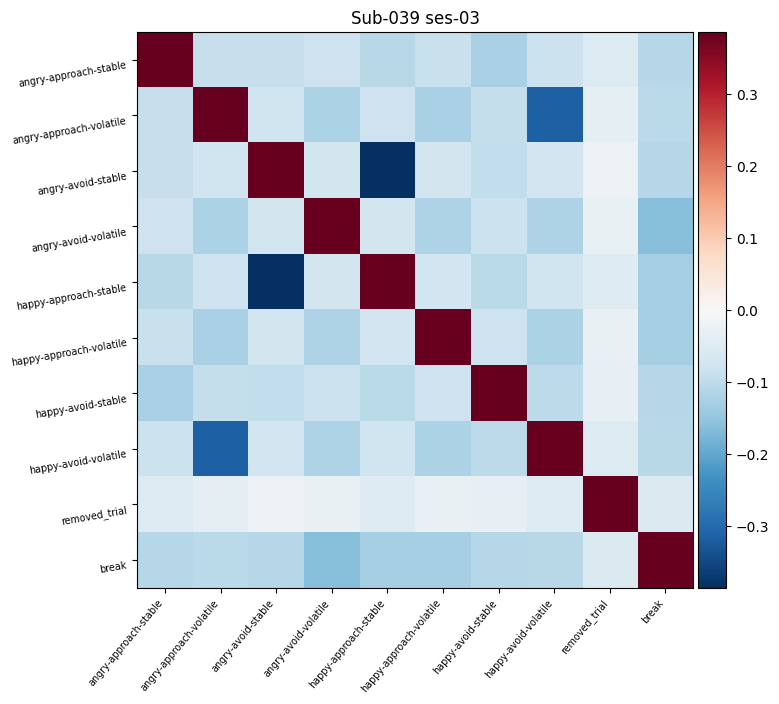

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 39 and session 4
30
60
90
120
150
180
210
240
272
300
330
360
392
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.063846   0.792522
1                                        NaN     5.063846   0.792522
2                              removed_trial     5.063846   0.792522
3                                        NaN     8.436195   0.734522
4                                        NaN     8.436195   0.734522
5                              removed_trial     8.436195   0.734

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


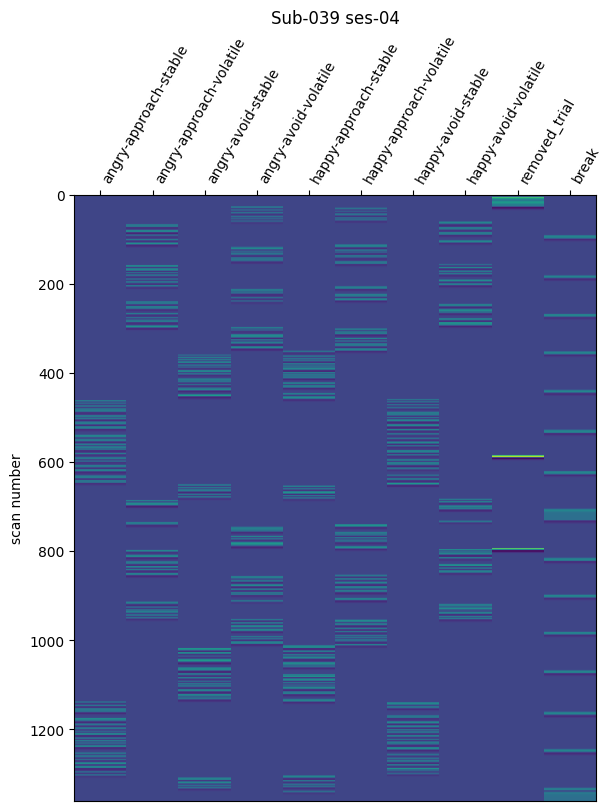

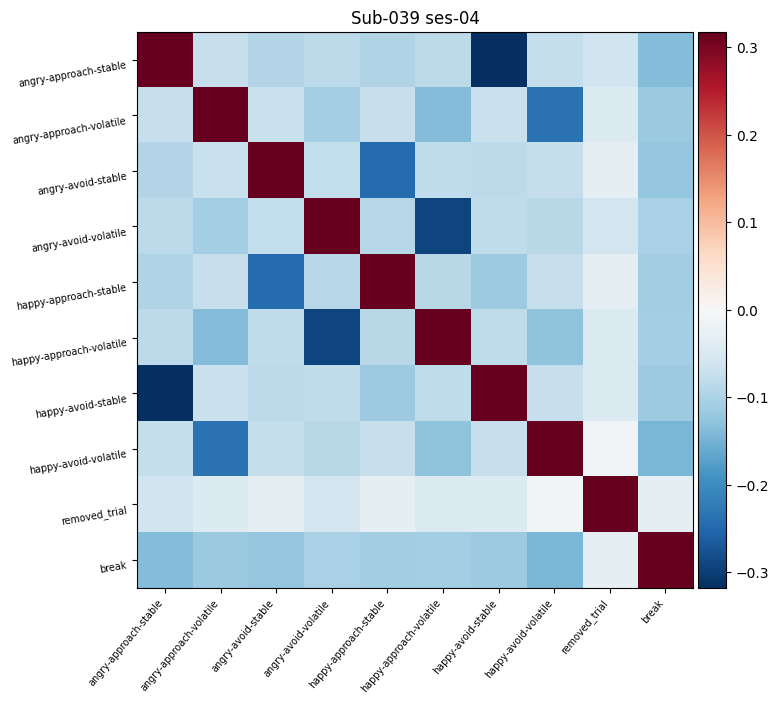

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

fMRIprep has not yet been run for subject 48 and session 2
fMRIprep has not yet been run for subject 48 and session 3
fMRIprep has not yet been run for subject 48 and session 4
Creating event file for subject 49 and session 2
30
66
90
122
150
180
210
242
270
302
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.075992   1.368764
1                                        NaN     5.075992   1.368764
2                              removed_trial     5.075992   1.368764
3                         

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


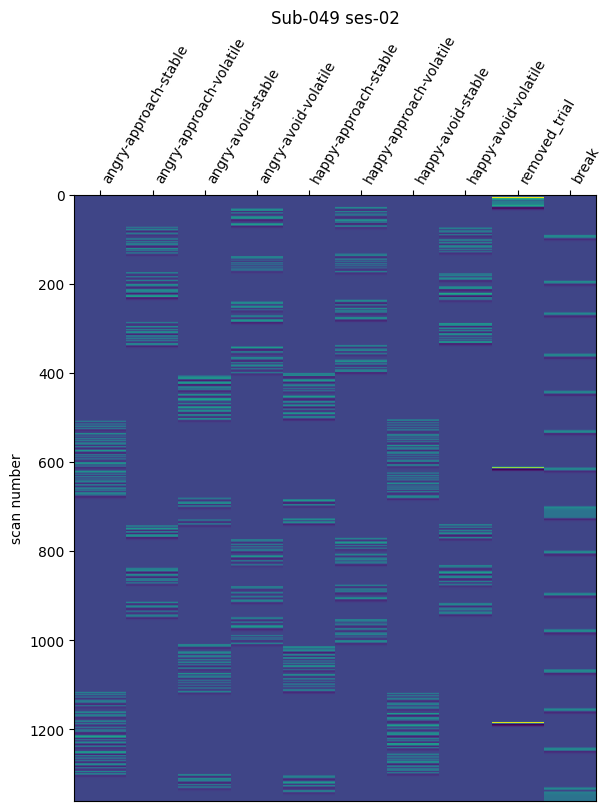

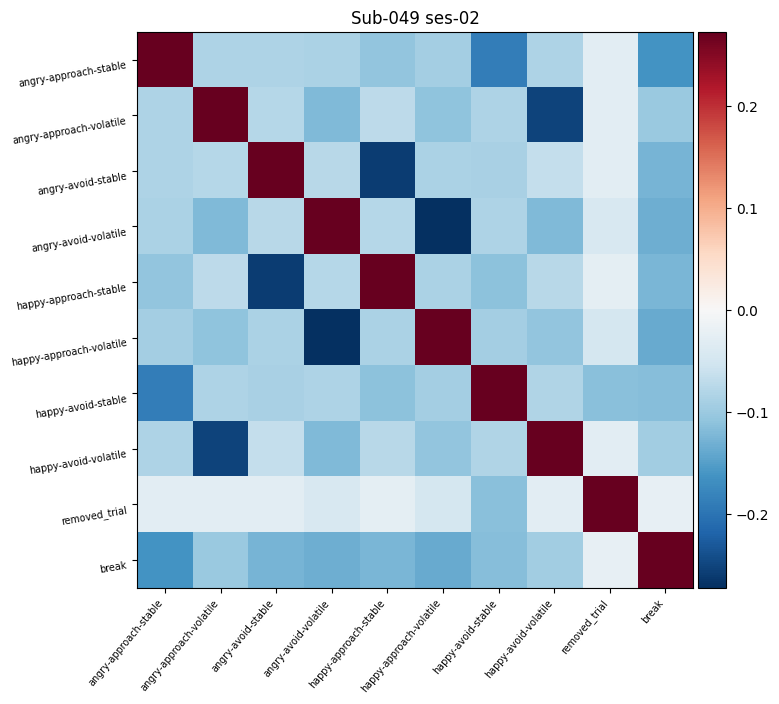

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 49 and session 3
30
60
90
126
154
186
210
240
270
300
330
362
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.058019   0.714875
1                                        NaN     5.058019   0.714875
2                              removed_trial     5.058019   0.714875
3                                        NaN     9.748888   0.723532
4                                        NaN     9.748888   0.723532
5                              removed_trial     9.748888   0.723

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


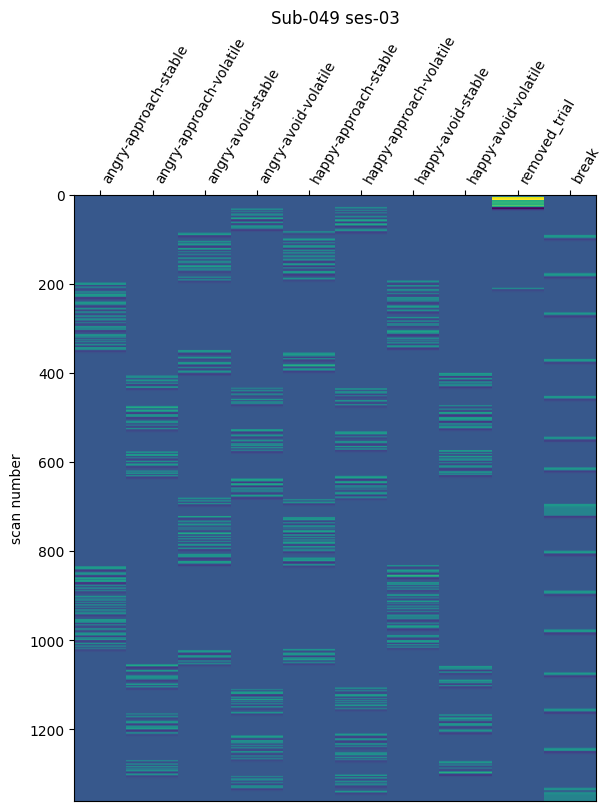

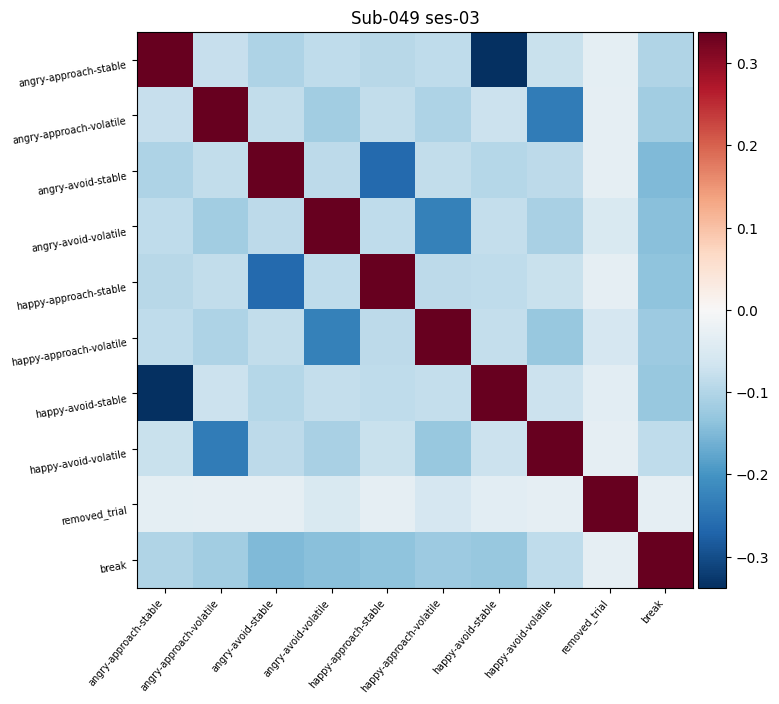

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 49 and session 4
30
60
90
120
150
180
212
242
270
300
330
366
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.061336   0.807492
1                                        NaN     5.061336   0.807492
2                              removed_trial     5.061336   0.807492
3                                        NaN     9.752490   0.844092
4                                        NaN     9.752490   0.844092
5                              removed_trial     9.752490   0.844

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


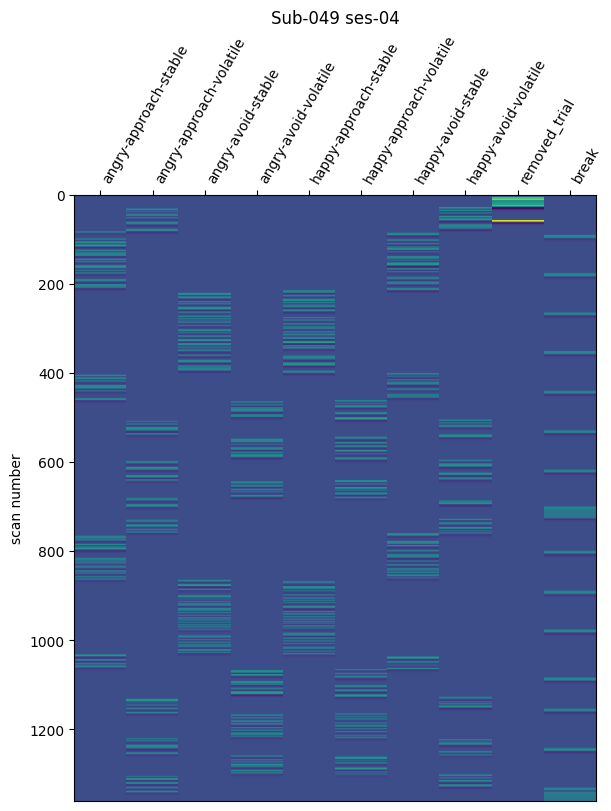

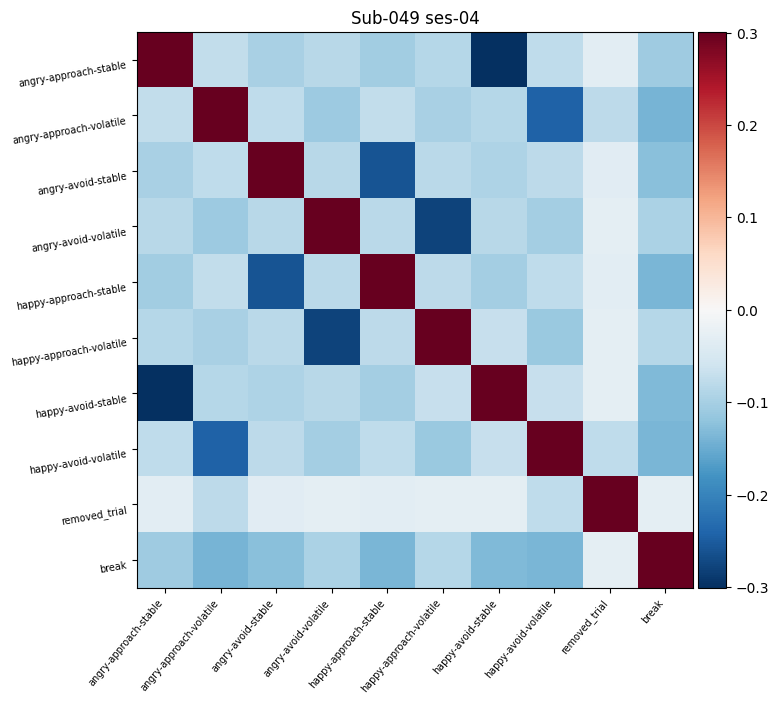

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 52 and session 2
32
60
90
120
150
180
210
246
270
300
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.147119   1.369851
1                                        NaN     5.147119   1.369851
2                              removed_trial     5.147119   1.369851
3                                        NaN     9.591200   0.844241
4                                        NaN     9.591200   0.844241
5                              removed_trial     9.591200   0.844

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


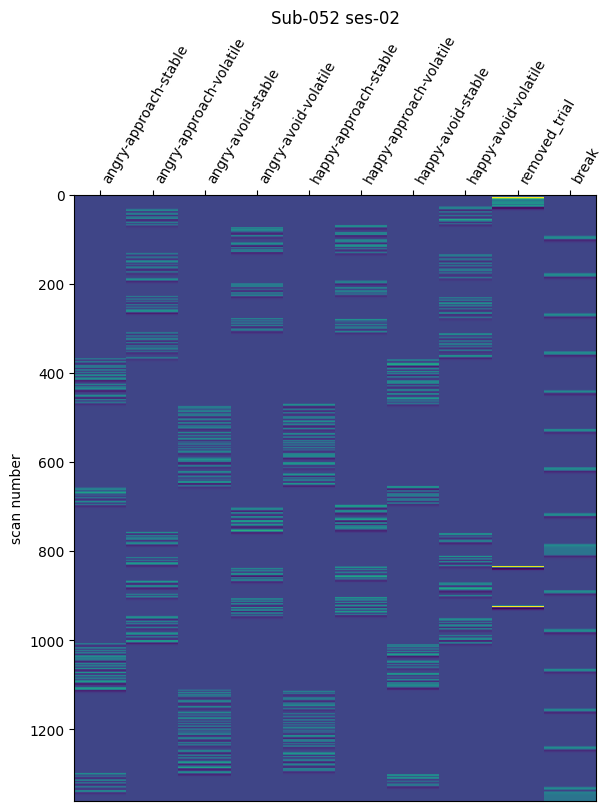

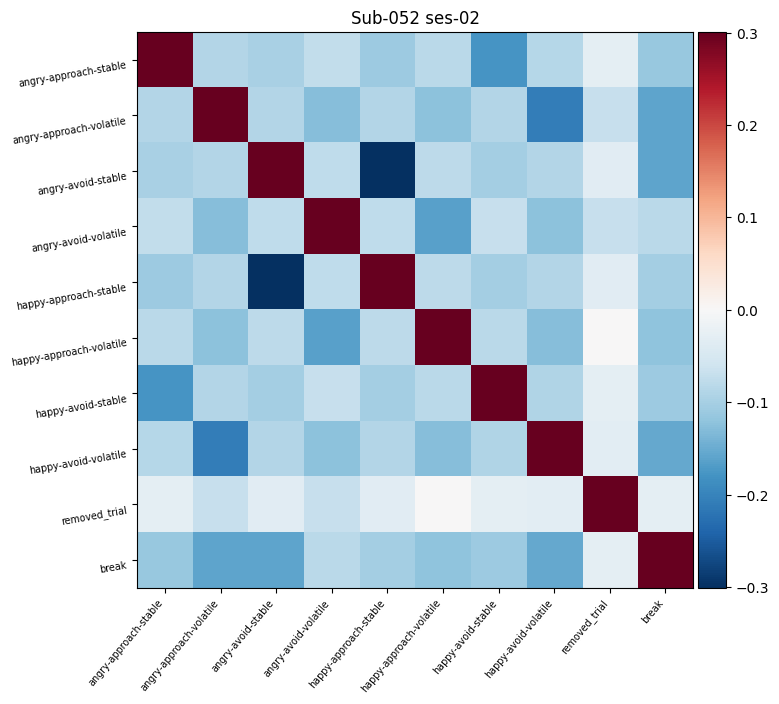

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.07347538574577515% of volumes have been removed.

Creating event file for subject 52 and session 3
30
60
90
120
152
180
210
240
270
300
330
366
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.045866   1.374031
1                                        NaN     5.045866   1.374031
2                              removed_trial     5.045866   1.374031
3                                        NaN     9.480143   0.782549
4                                        NaN     9.480143   0.782549
5                              removed_trial     

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


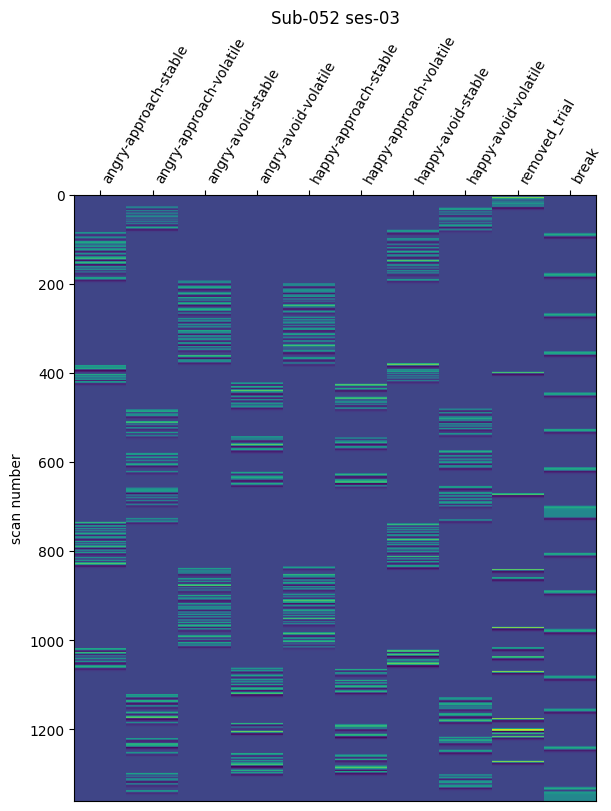

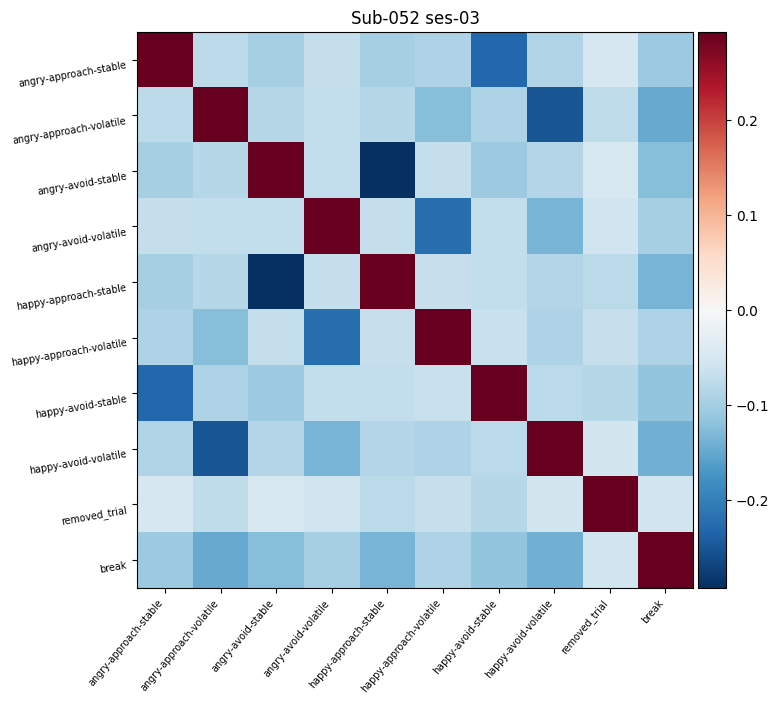

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.1469507714915503% of volumes have been removed.

Creating event file for subject 52 and session 4
30
60
90
120
150
180
210
246
270
300
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.059612   0.883737
1                                        NaN     5.059612   0.883737
2                              removed_trial     5.059612   0.883737
3                                        NaN     9.491522   0.609971
4                                        NaN     9.491522   0.609971
5                              removed_trial     9

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


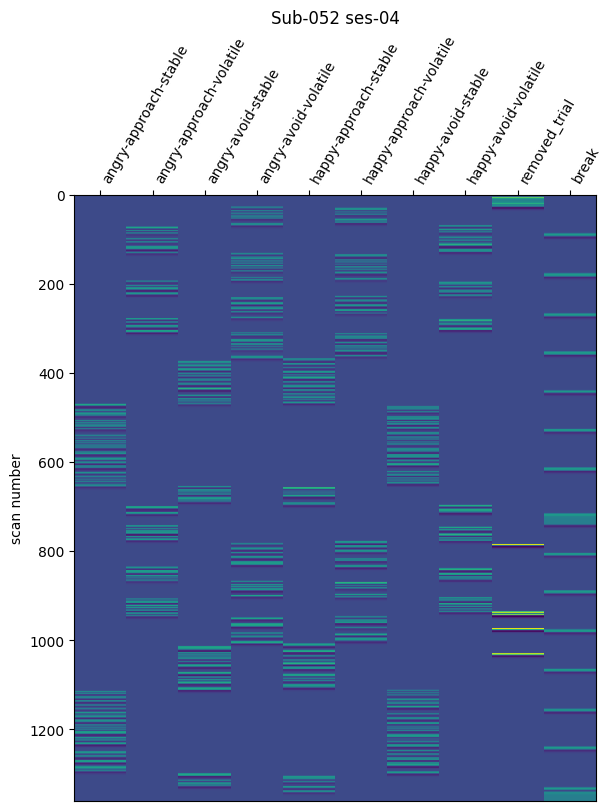

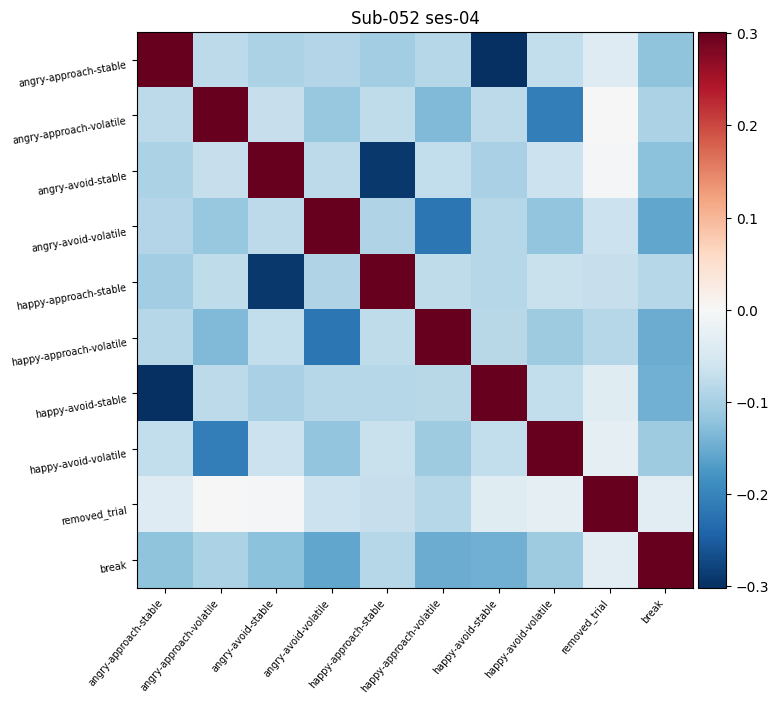

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 53 and session 2
32
60
90
120
150
180
210
246
270
300
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.137678   1.067293
1                                        NaN     5.137678   1.067293
2                              removed_trial     5.137678   1.067293
3                                        NaN     9.562333   1.276718
4                                        NaN     9.562333   1.276718
5                              removed_trial     9.562333   1.276

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


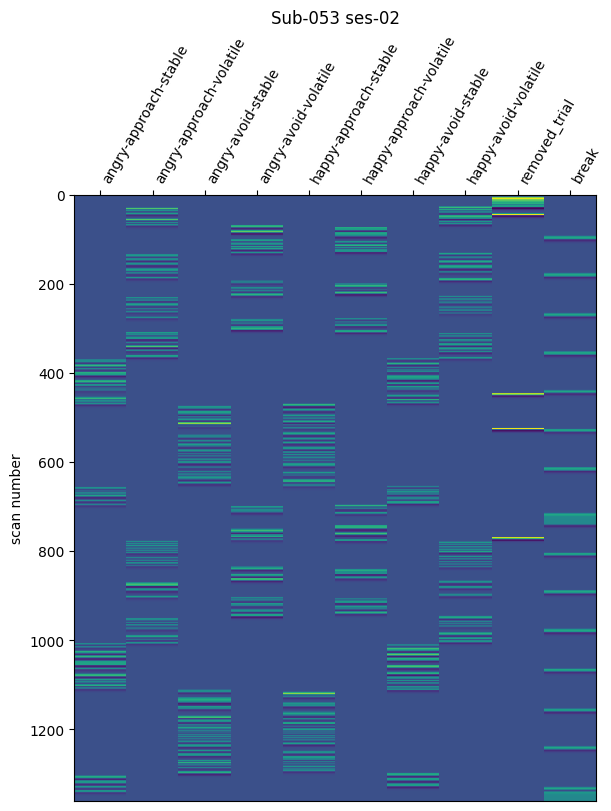

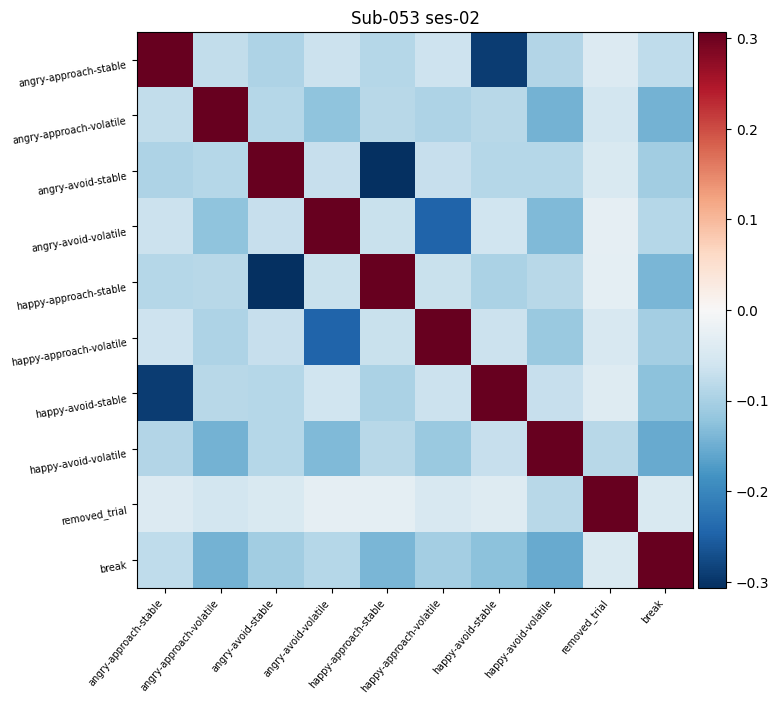

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.07347538574577515% of volumes have been removed.

Creating event file for subject 53 and session 3
30
60
90
120
150
180
210
240
270
300
330
366
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.081982   1.003438
1                                        NaN     5.081982   1.003438
2                              removed_trial     5.081982   1.003438
3                                        NaN     9.515166   0.738340
4                                        NaN     9.515166   0.738340
5                              removed_trial     

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


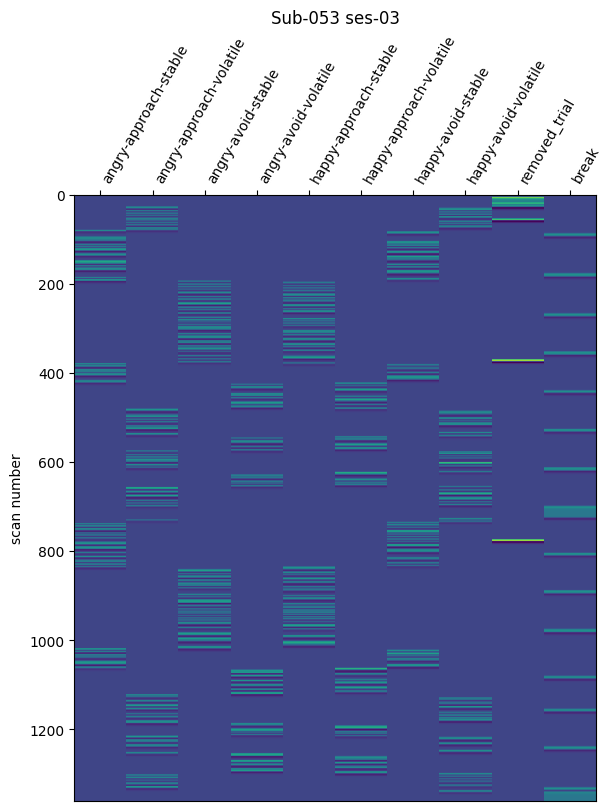

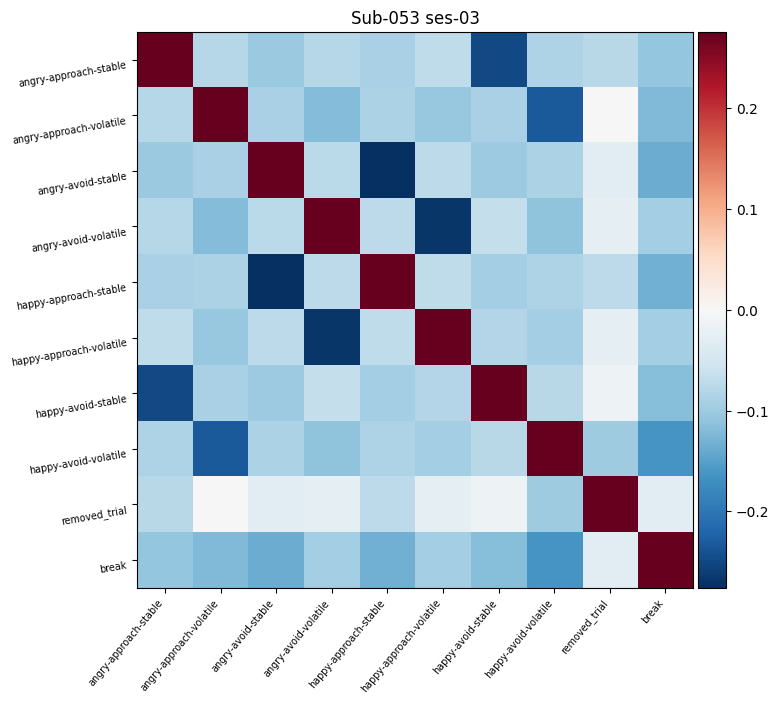

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.2204261572373255% of volumes have been removed.

Creating event file for subject 53 and session 4
30
60
90
120
150
180
210
246
270
300
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.092943   1.153451
1                                        NaN     5.092943   1.153451
2                              removed_trial     5.092943   1.153451
3                                        NaN     9.525413   0.693582
4                                        NaN     9.525413   0.693582
5                              removed_trial     9

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


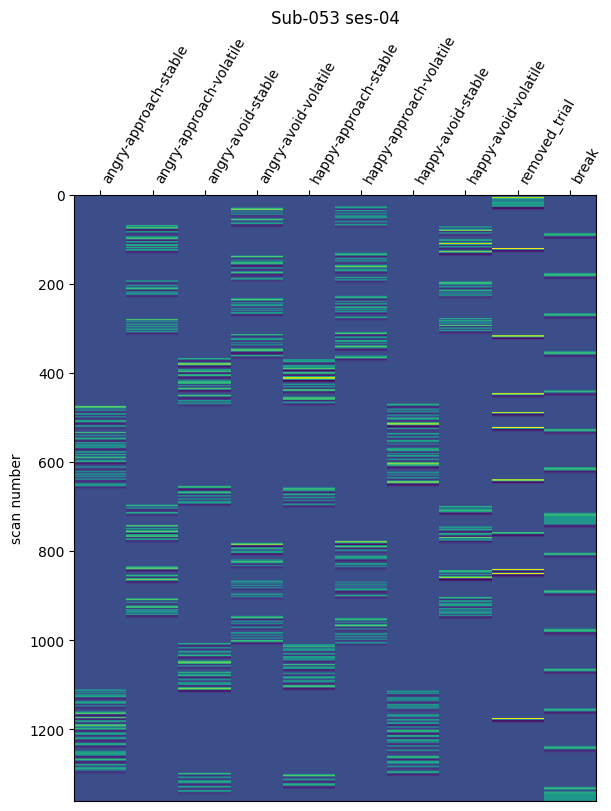

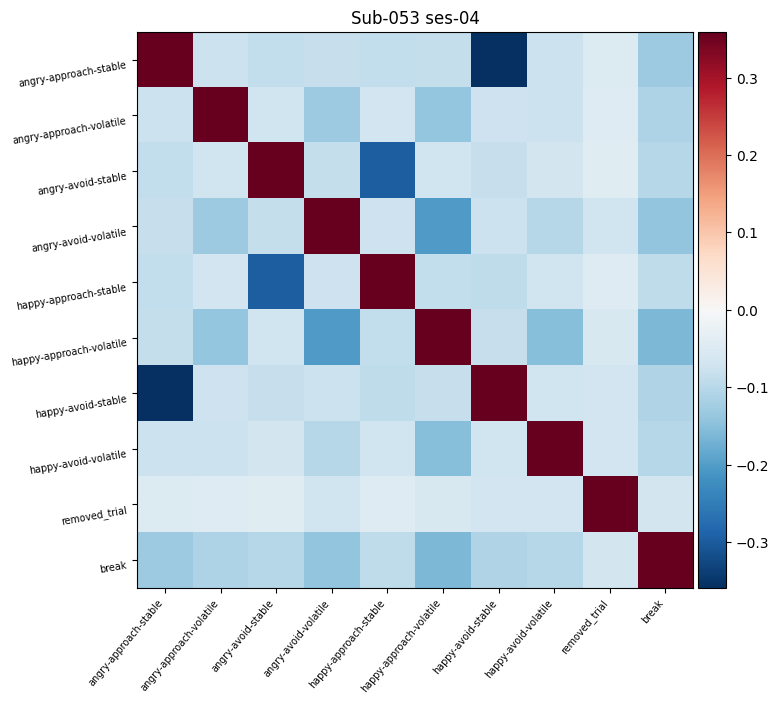

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 54 and session 2
30
60
90
120
150
180
210
246
270
300
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.174525   1.274669
1                                        NaN     5.174525   1.274669
2                              removed_trial     5.174525   1.274669
3                                        NaN     9.605132   0.743697
4                                        NaN     9.605132   0.743697
5                              removed_trial     9.605132   0.743

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


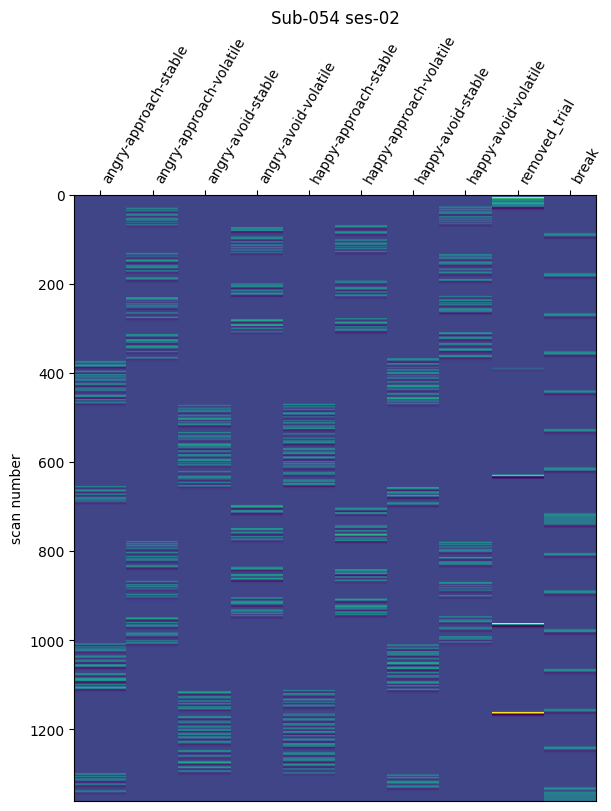

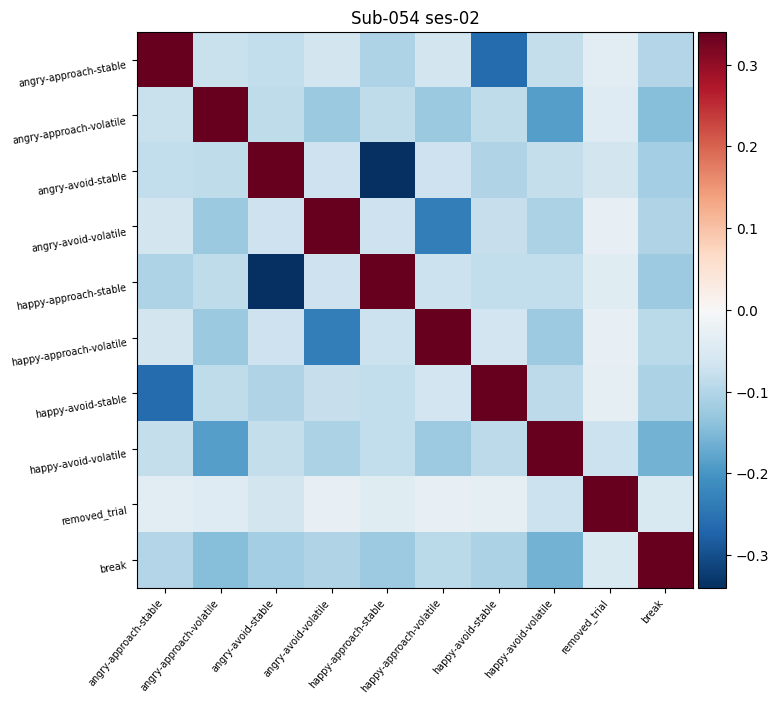

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 54 and session 3
30
60
90
120
150
180
210
240
270
300
330
366
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.046603   0.750861
1                                        NaN     5.046603   0.750861
2                              removed_trial     5.046603   0.750861
3                                        NaN     9.475564   0.612867
4                                        NaN     9.475564   0.612867
5                              removed_trial     9.475564   0.612

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


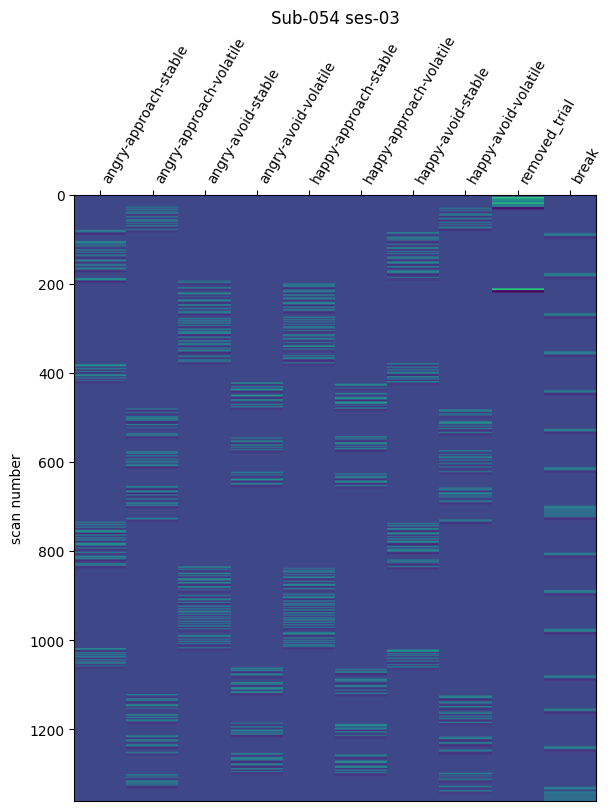

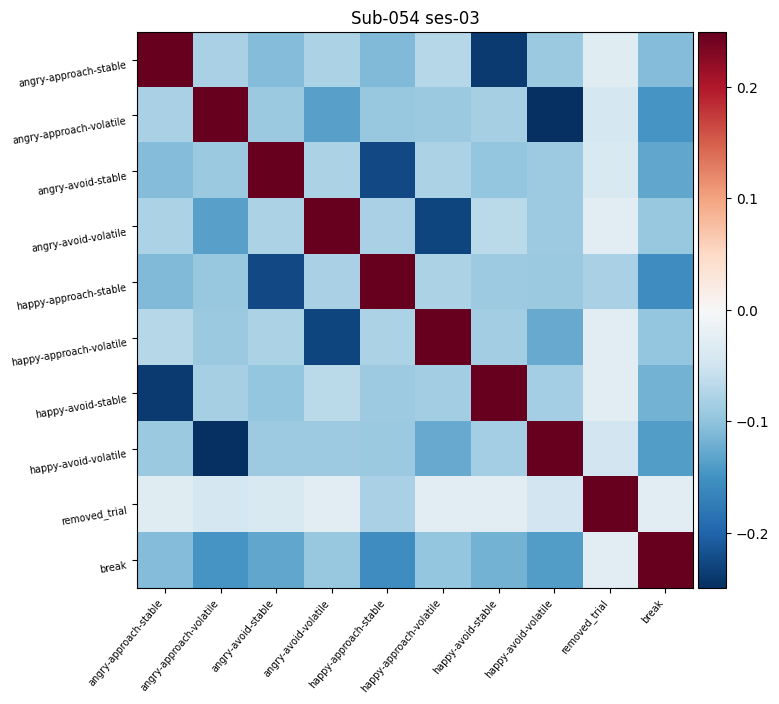

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 54 and session 4
30
60
90
120
150
180
210
246
270
300
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.138703   0.560441
1                                        NaN     5.138703   0.560441
2                              removed_trial     5.138703   0.560441
3                                        NaN     9.591975   0.634785
4                                        NaN     9.591975   0.634785
5                              removed_trial     9.591975   0.634

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


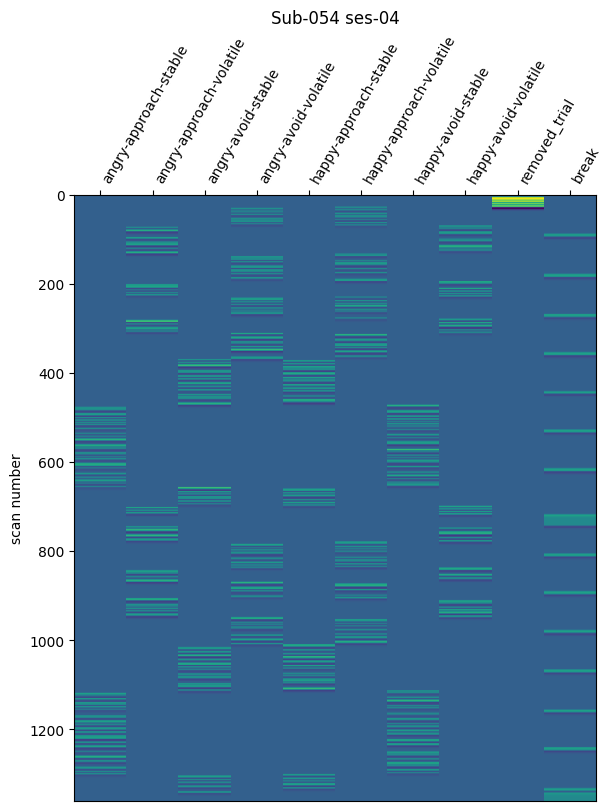

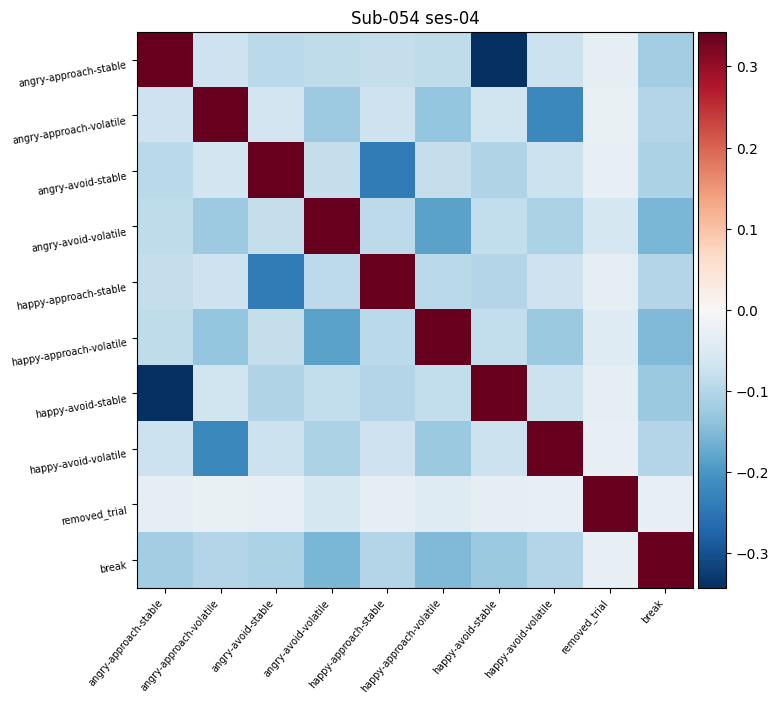

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 55 and session 2
32
60
90
120
150
180
210
246
270
300
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.045609   0.911121
1                                        NaN     5.045609   0.911121
2                              removed_trial     5.045609   0.911121
3                                        NaN     9.481693   0.540970
4                                        NaN     9.481693   0.540970
5                              removed_trial     9.481693   0.540

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


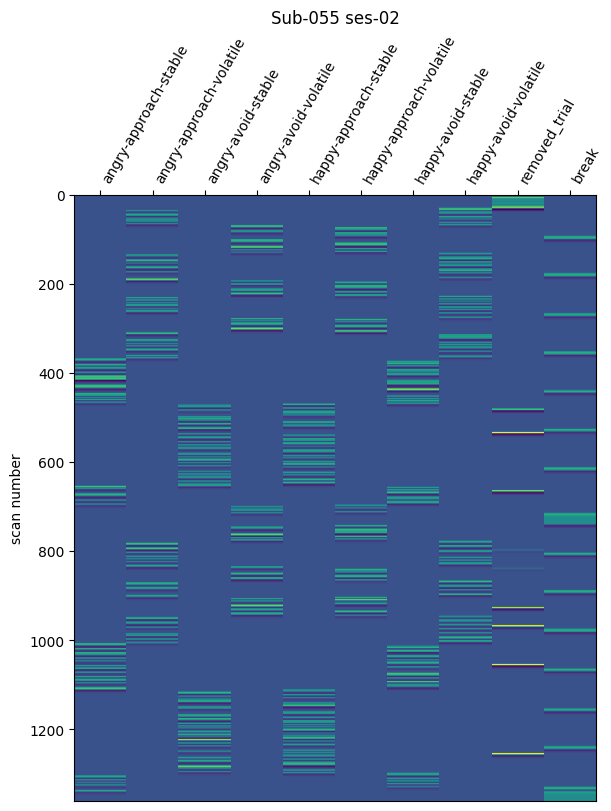

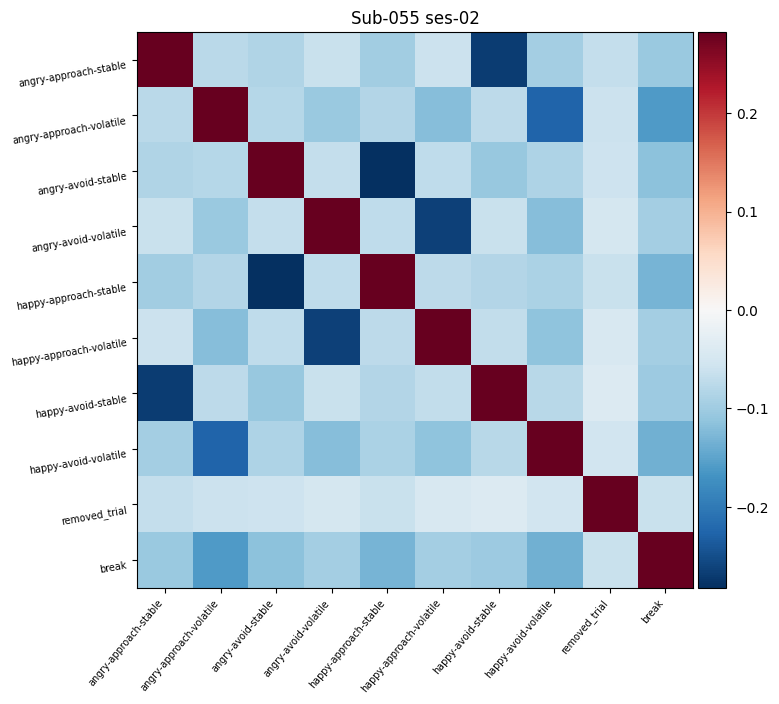

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 55 and session 3
30
60
90
120
150
180
210
240
270
300
330
366
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.108126   0.720110
1                                        NaN     5.108126   0.720110
2                              removed_trial     5.108126   0.720110
3                                        NaN     9.542581   0.802588
4                                        NaN     9.542581   0.802588
5                              removed_trial     9.542581   0.802

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


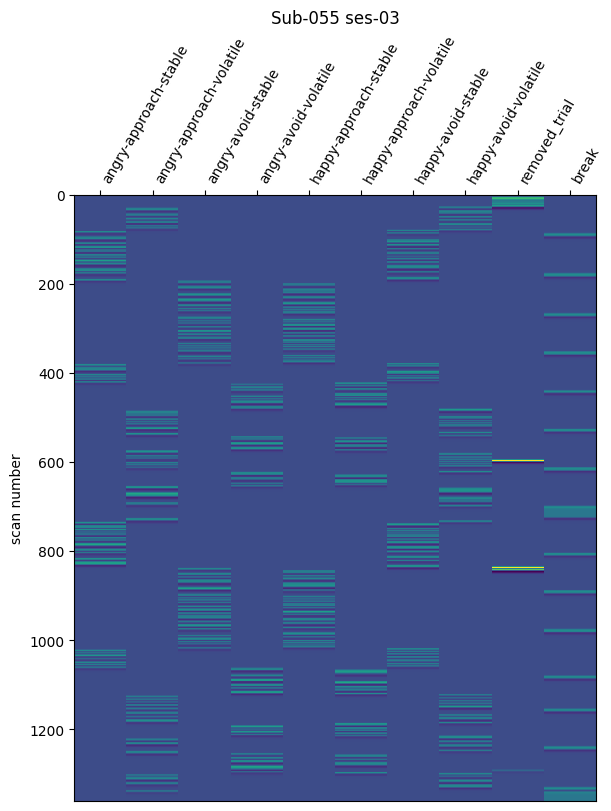

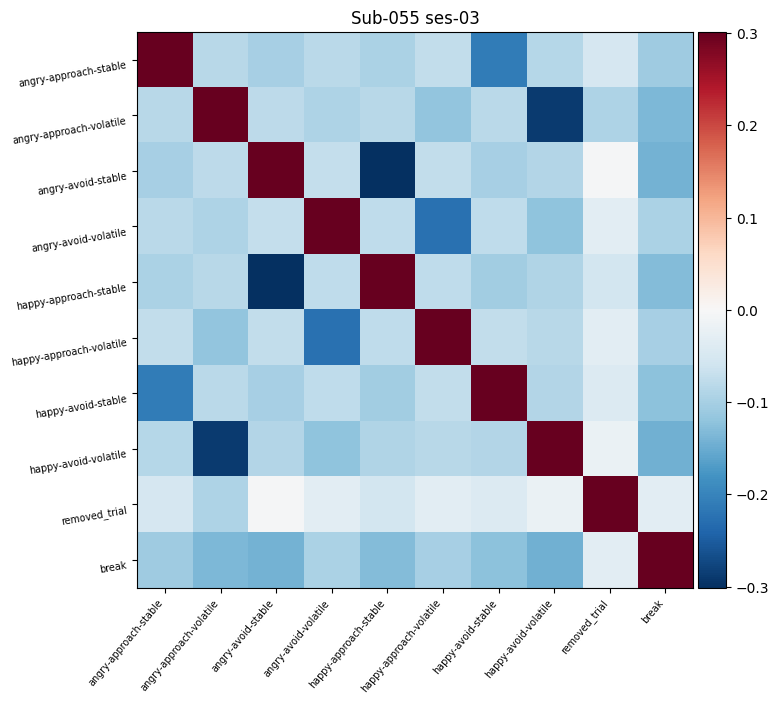

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 55 and session 4
30
60
90
120
150
180
210
246
270
300
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.047973   0.667440
1                                        NaN     5.047973   0.667440
2                              removed_trial     5.047973   0.667440
3                                        NaN     9.483789   0.673646
4                                        NaN     9.483789   0.673646
5                              removed_trial     9.483789   0.673

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


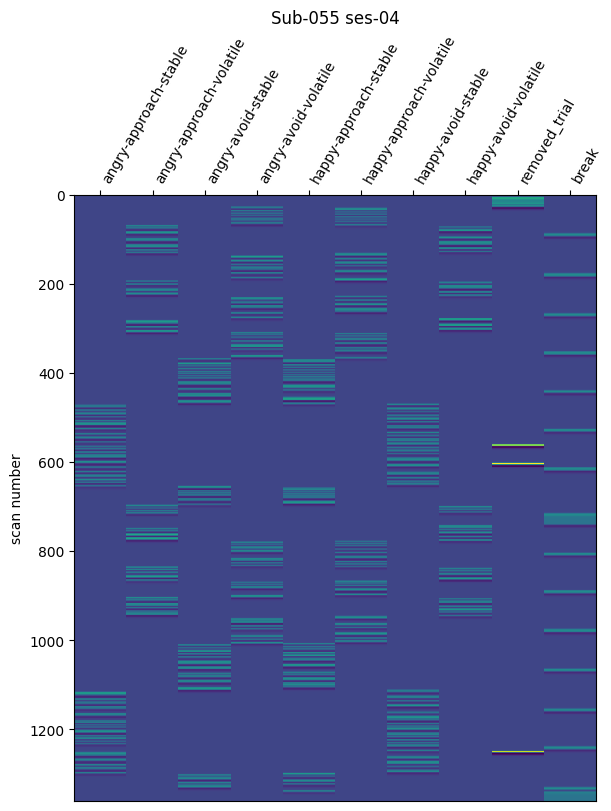

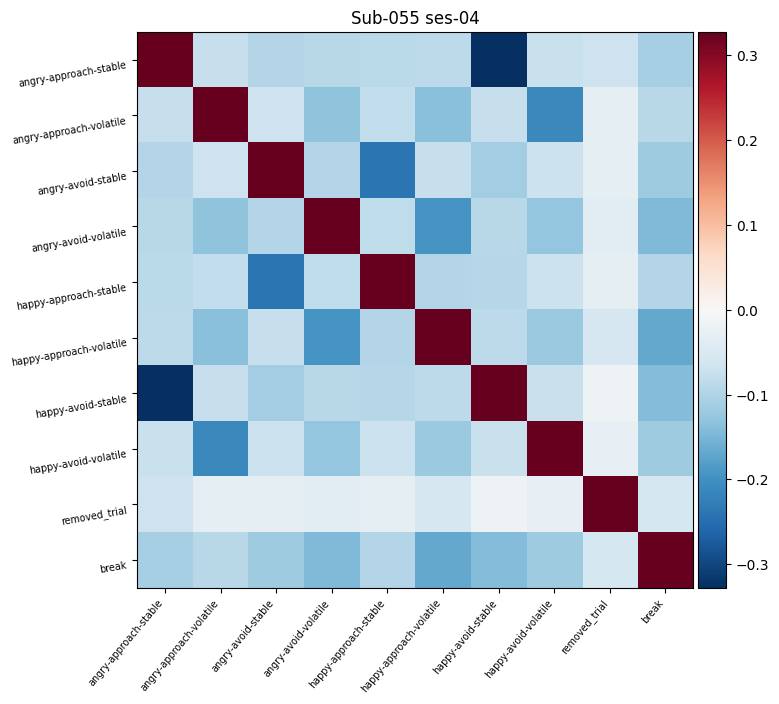

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 57 and session 2
30
60
90
120
150
180
210
246
270
300
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.043884   1.208809
1                                        NaN     5.043884   1.208809
2                              removed_trial     5.043884   1.208809
3                                        NaN     9.469791   0.716683
4                                        NaN     9.469791   0.716683
5                              removed_trial     9.469791   0.716

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


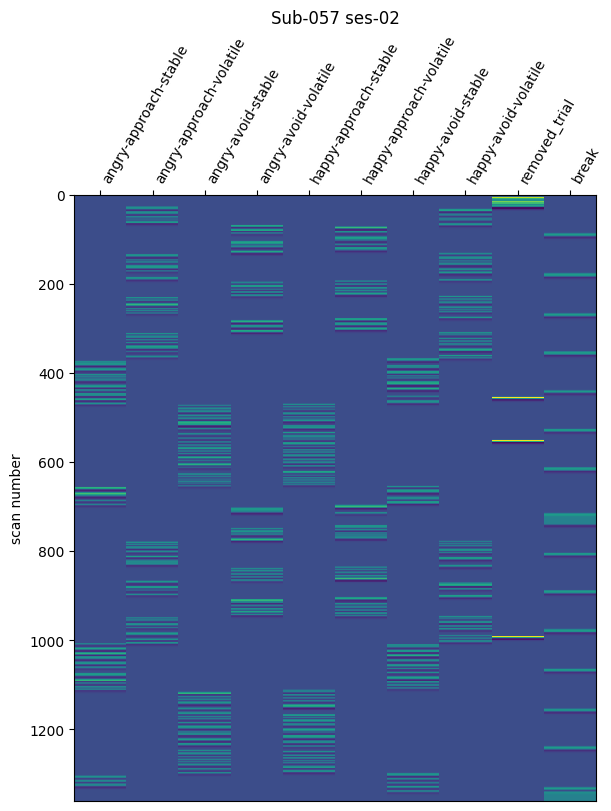

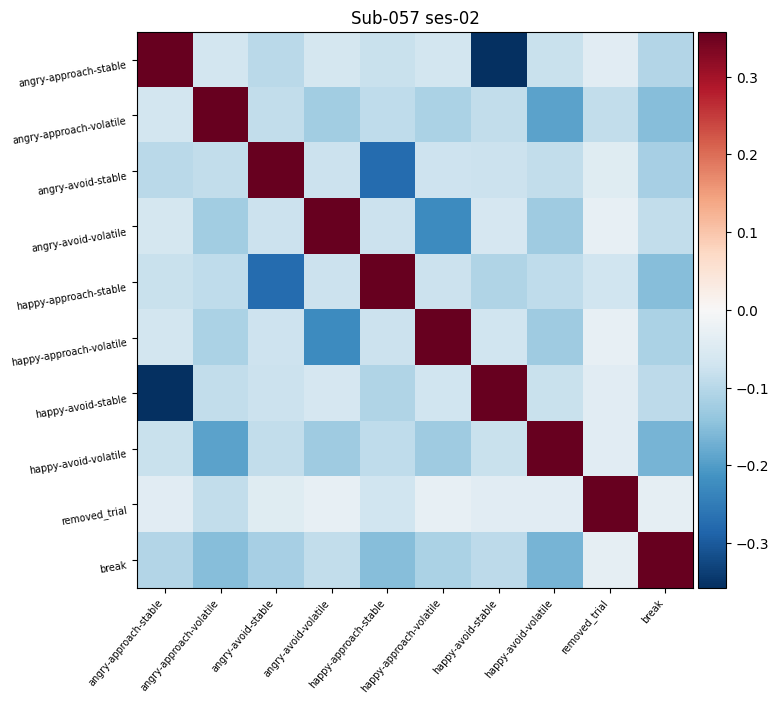

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 57 and session 3
30
60
90
120
152
180
210
240
270
300
330
366
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.045978   1.010743
1                                        NaN     5.045978   1.010743
2                              removed_trial     5.045978   1.010743
3                                        NaN     9.477724   0.585837
4                                        NaN     9.477724   0.585837
5                              removed_trial     9.477724   0.585

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


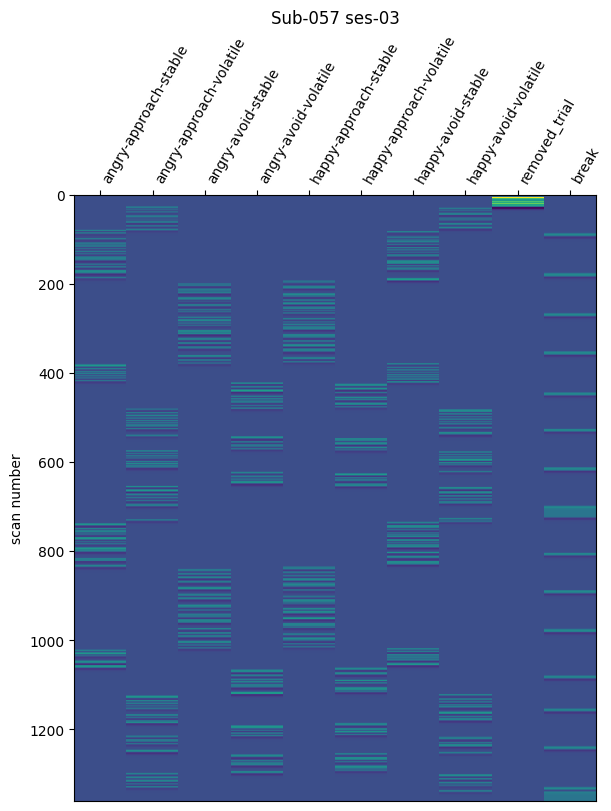

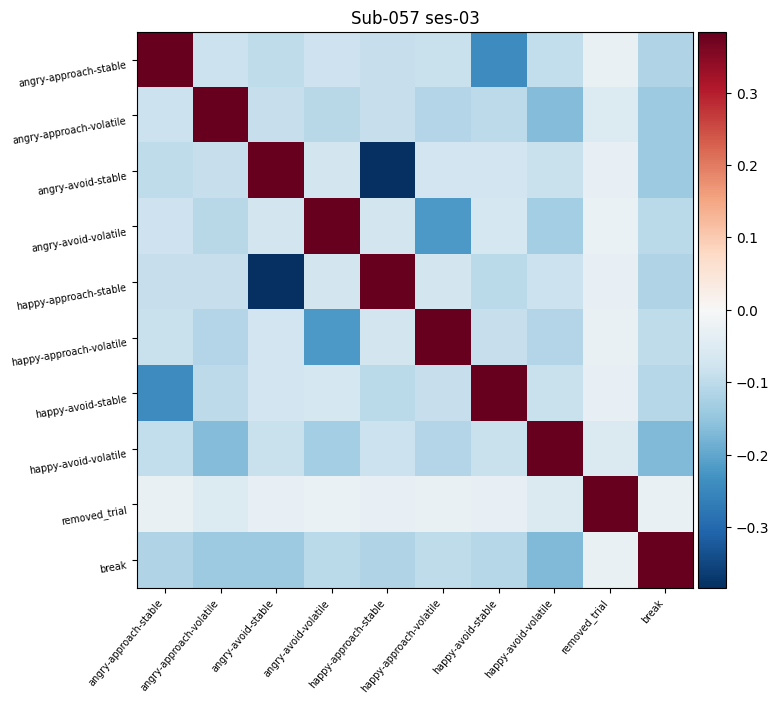

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 57 and session 4
30
60
90
120
150
180
210
246
270
300
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.077368   0.923308
1                                        NaN     5.077368   0.923308
2                              removed_trial     5.077368   0.923308
3                                        NaN     9.505739   0.868719
4                                        NaN     9.505739   0.868719
5                              removed_trial     9.505739   0.868

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


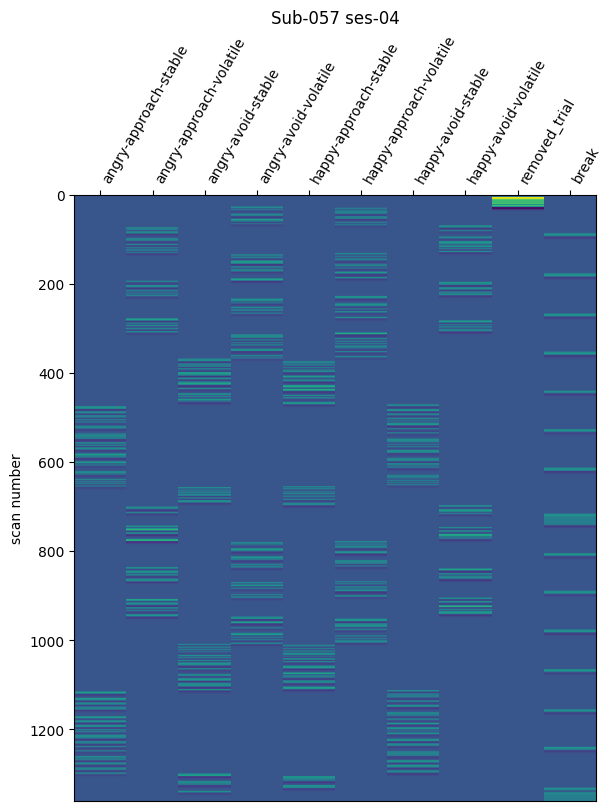

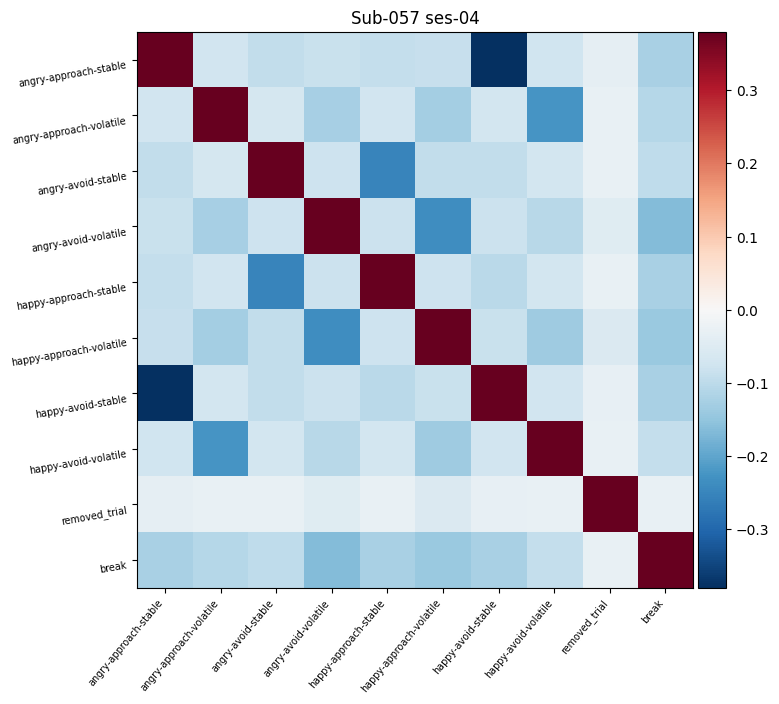

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 58 and session 2
30
60
90
120
156
186
210
240
270
300
330
366
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.069465   0.982361
1                                        NaN     5.069465   0.982361
2                              removed_trial     5.069465   0.982361
3                                        NaN     9.673523   0.690917
4                                        NaN     9.673523   0.690917
5                              removed_trial     9.673523   0.690

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


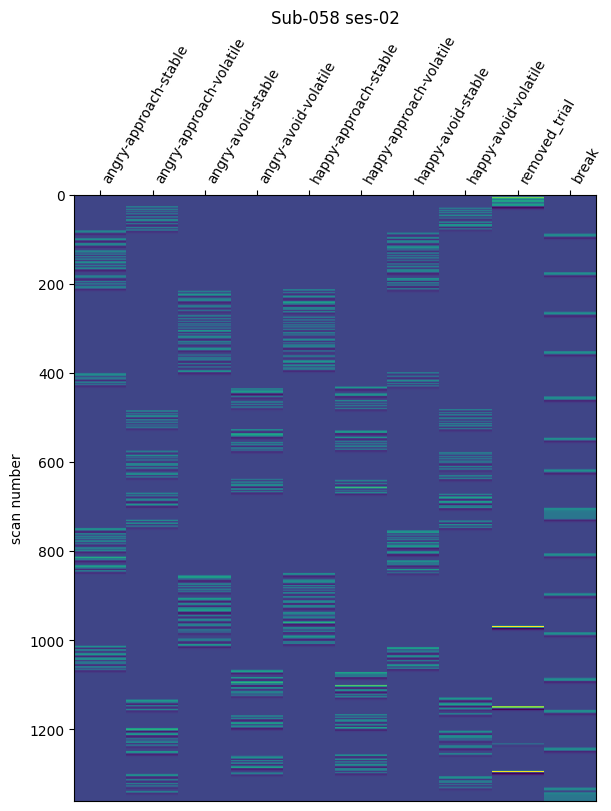

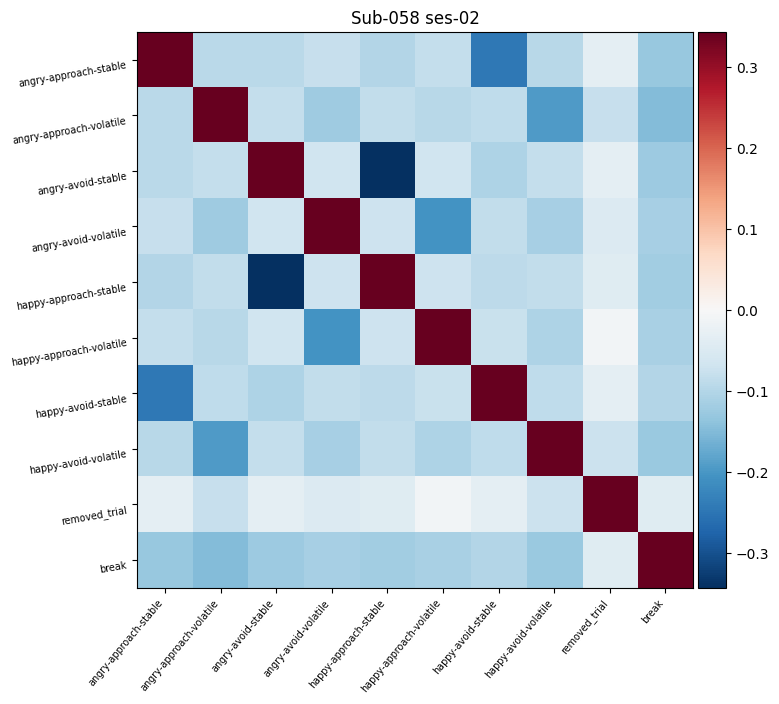

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.07347538574577515% of volumes have been removed.

Creating event file for subject 58 and session 3
30
60
90
120
150
182
212
240
270
300
330
362
390
426
450
451
                                  trial_type        onset   duration
0                                        NaN     5.080978   0.700119
1                                        NaN     5.080978   0.700119
2                              removed_trial     5.080978   0.700119
3                                        NaN     9.678015   0.645623
4                                        NaN     9.678015   0.645623
5                              removed_trial     

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


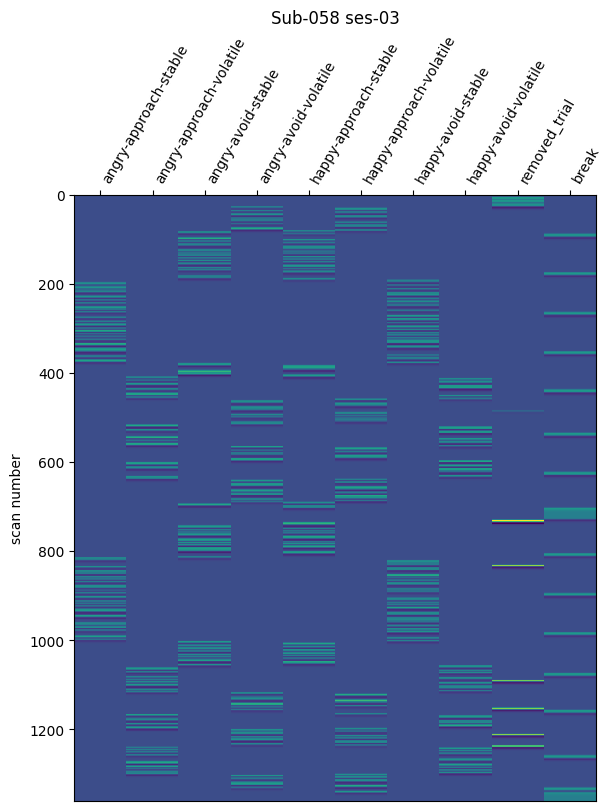

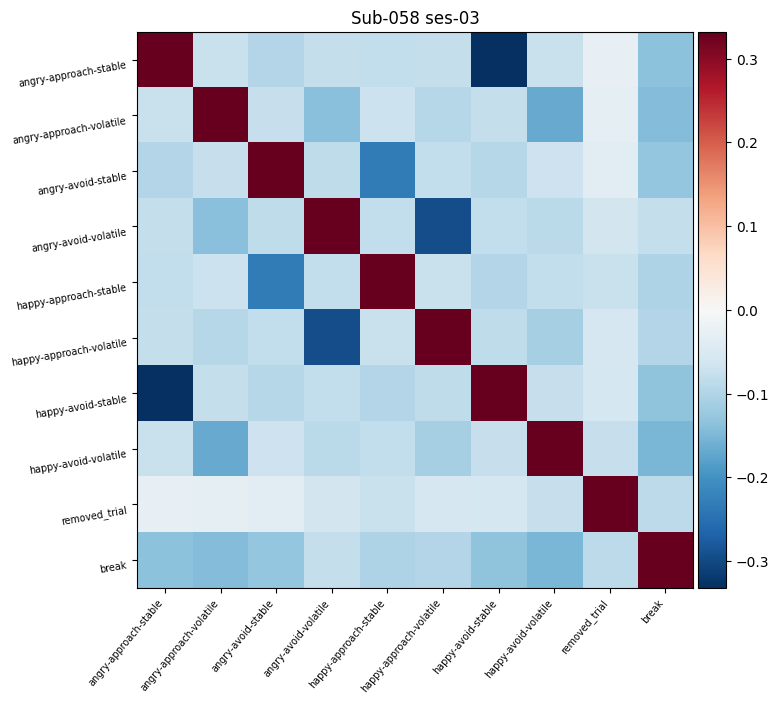

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.440852314474651% of volumes have been removed.

Creating event file for subject 58 and session 4
30
60
90
120
150
180
210
242
274
306
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.070799   0.871034
1                                        NaN     5.070799   0.871034
2                              removed_trial     5.070799   0.871034
3                                        NaN     9.679856   0.727295
4                                        NaN     9.679856   0.727295
5                              removed_trial     9.

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


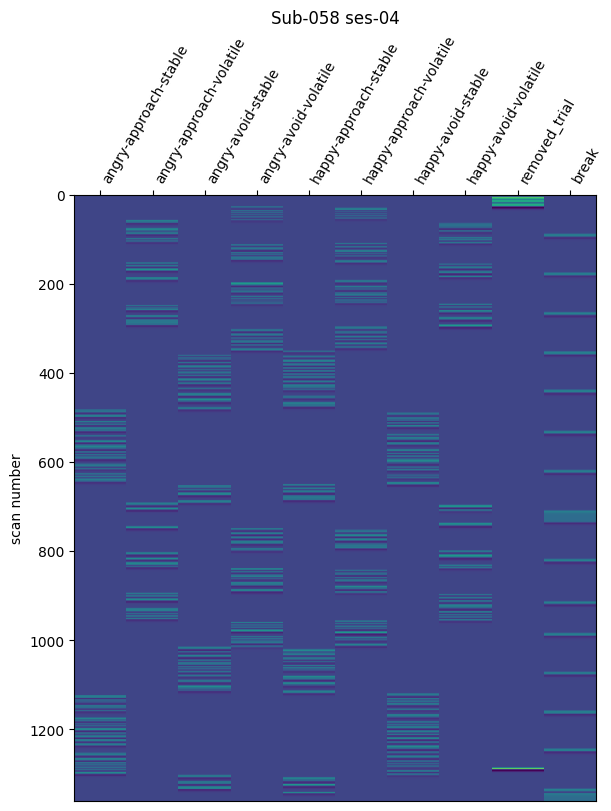

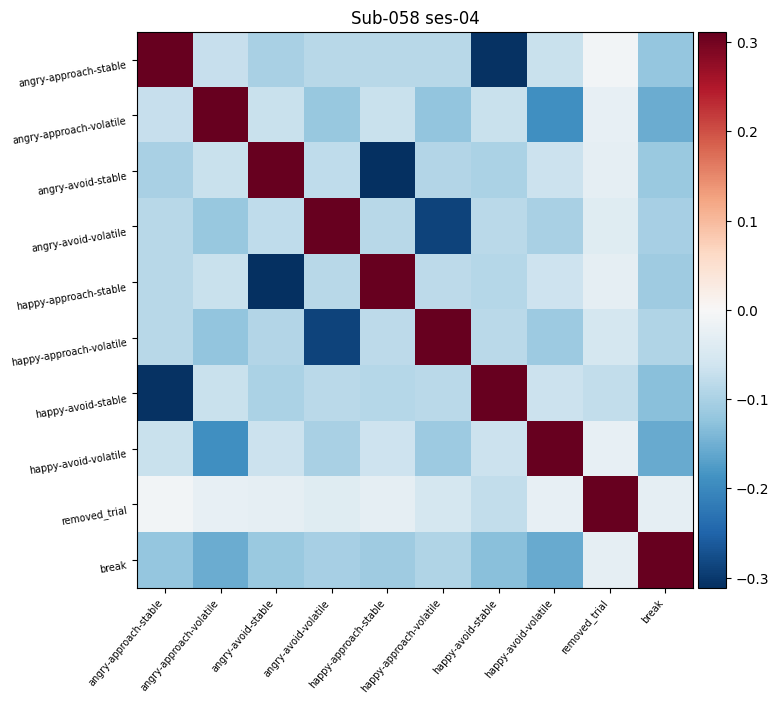

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 60 and session 2
30
60
90
120
150
180
210
240
270
300
330
362
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.307620   0.994692
1                                        NaN     5.307620   0.994692
2                              removed_trial     5.307620   0.994692
3                                        NaN     9.213415   0.723108
4                                        NaN     9.213415   0.723108
5                              removed_trial     9.213415   0.723

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


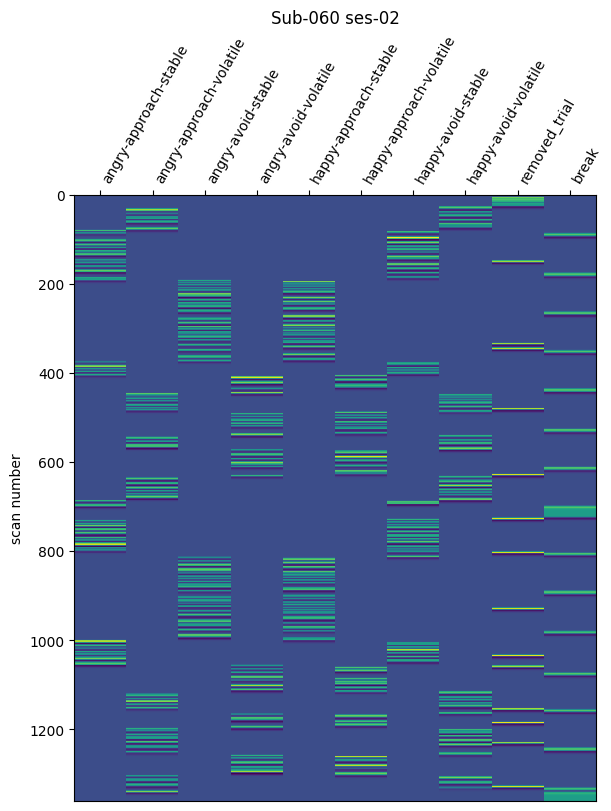

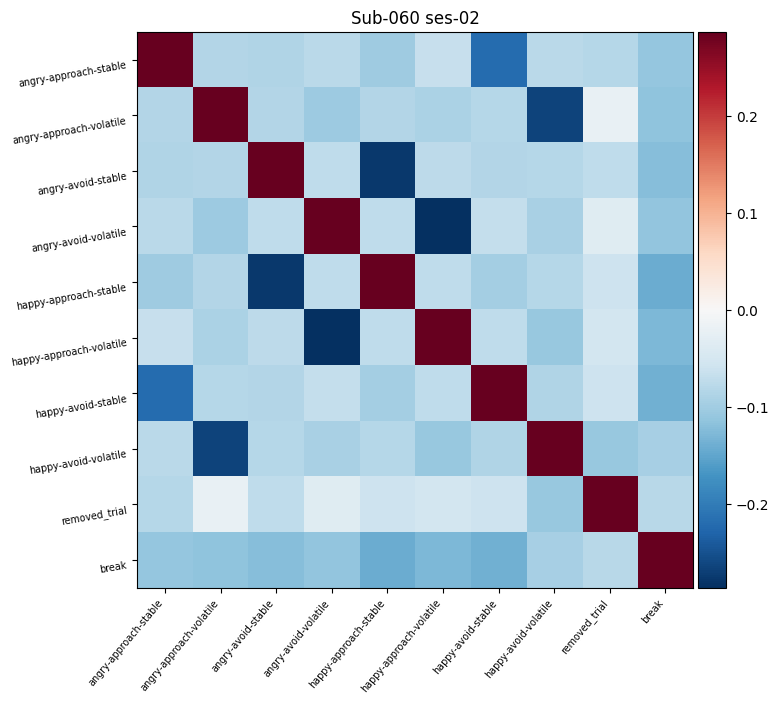

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 60 and session 3
34
66
94
120
150
180
210
240
270
302
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     6.672918   0.941322
1                                        NaN     6.672918   0.941322
2                              removed_trial     6.672918   0.941322
3                                        NaN    10.586415   0.653046
4                                        NaN    10.586415   0.653046
5                              removed_trial    10.586415   0.653

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


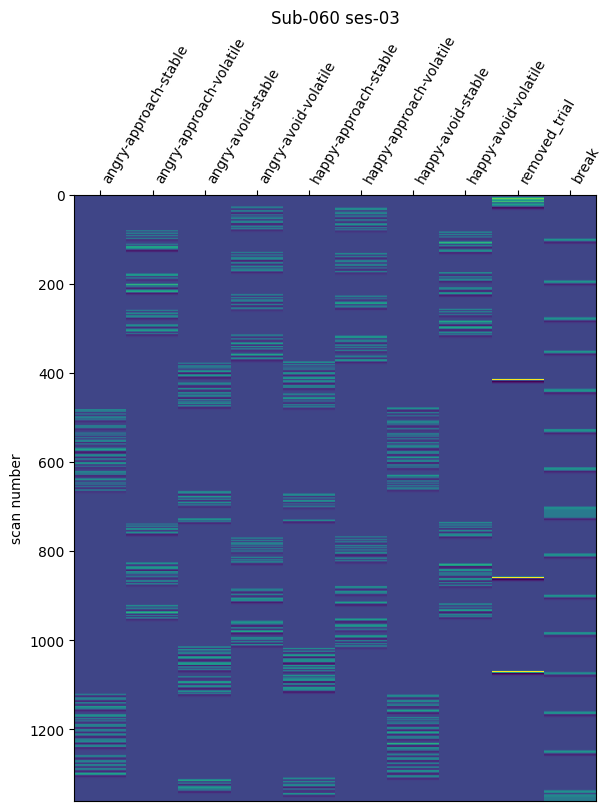

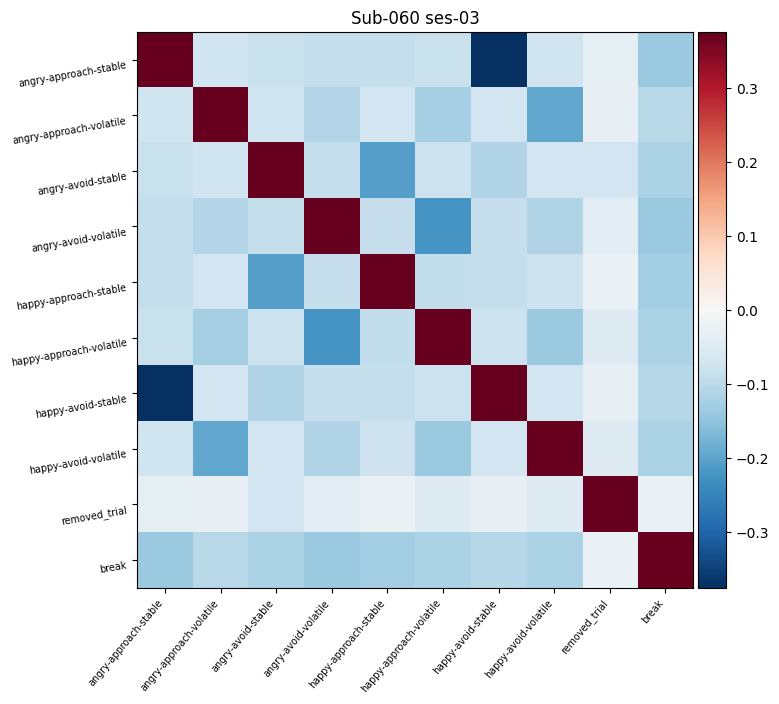

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 60 and session 4
30
60
90
120
150
182
212
240
270
300
330
366
394
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.065190   1.047272
1                                        NaN     5.065190   1.047272
2                              removed_trial     5.065190   1.047272
3                                        NaN     8.972276   0.689548
4                                        NaN     8.972276   0.689548
5                              removed_trial     8.972276   0.689

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


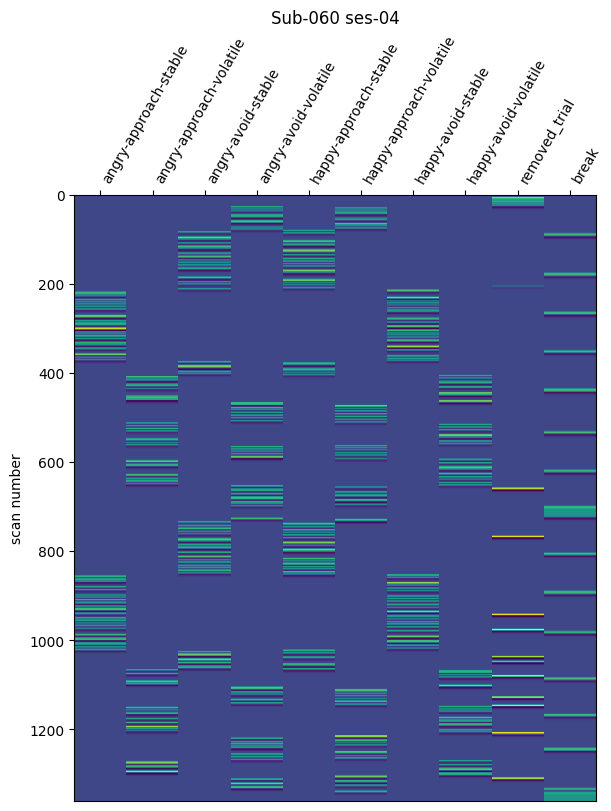

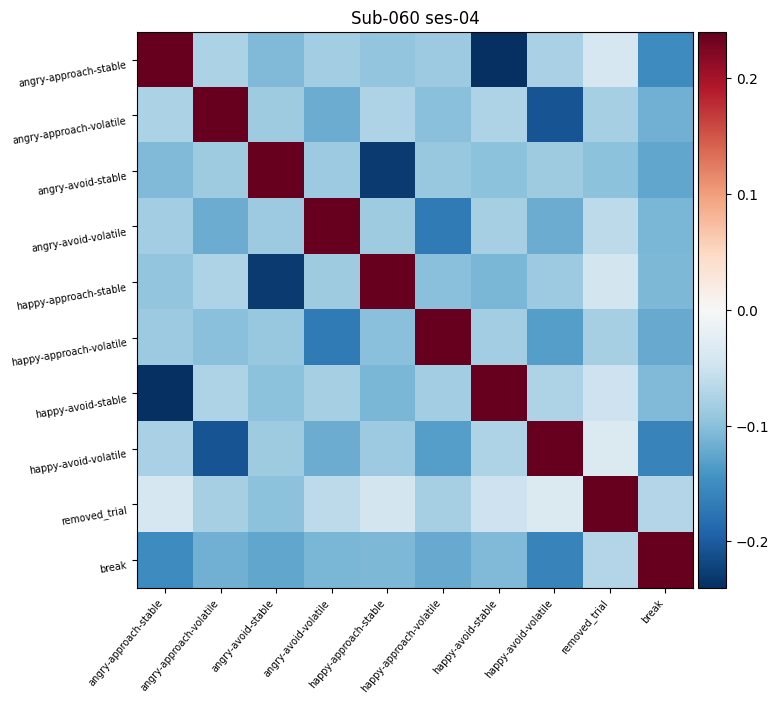

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 61 and session 2
30
60
90
120
150
180
210
246
270
300
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.073116   1.286616
1                                        NaN     5.073116   1.286616
2                              removed_trial     5.073116   1.286616
3                                        NaN     9.507843   0.913876
4                                        NaN     9.507843   0.913876
5                              removed_trial     9.507843   0.913

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


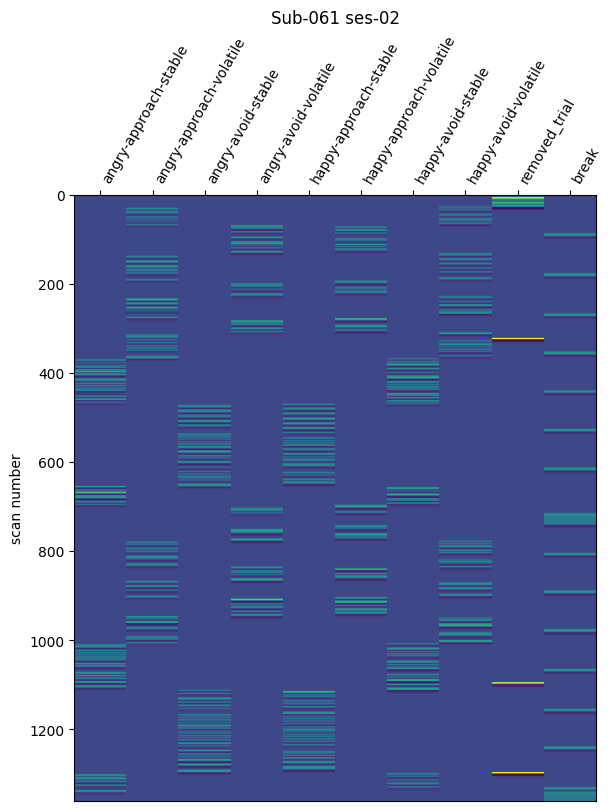

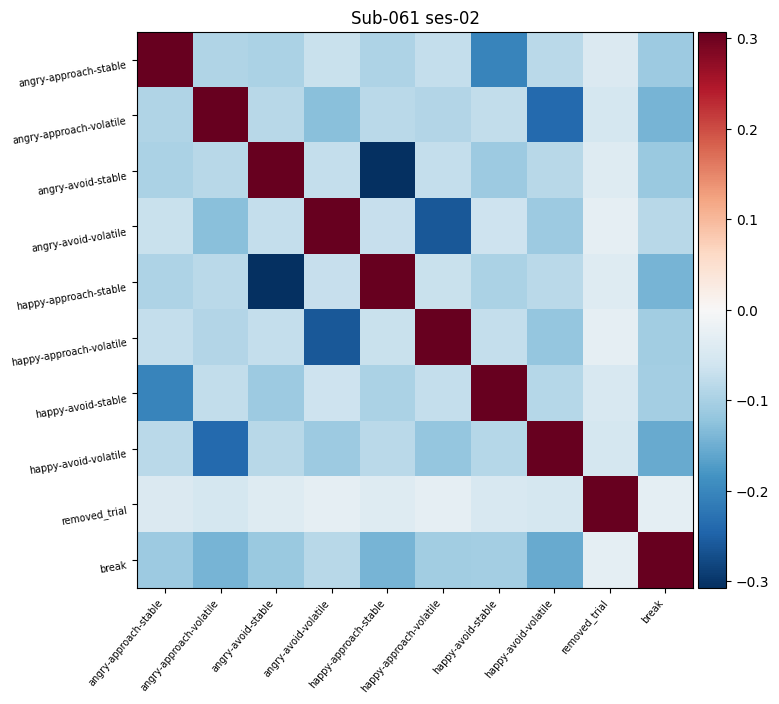

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 61 and session 3
30
60
90
126
150
180
214
240
270
300
330
360
390
426
450
451
                                  trial_type        onset   duration
0                                        NaN     5.065906   1.151096
1                                        NaN     5.065906   1.151096
2                              removed_trial     5.065906   1.151096
3                                        NaN     8.687992   0.823703
4                                        NaN     8.687992   0.823703
5                              removed_trial     8.687992   0.823

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


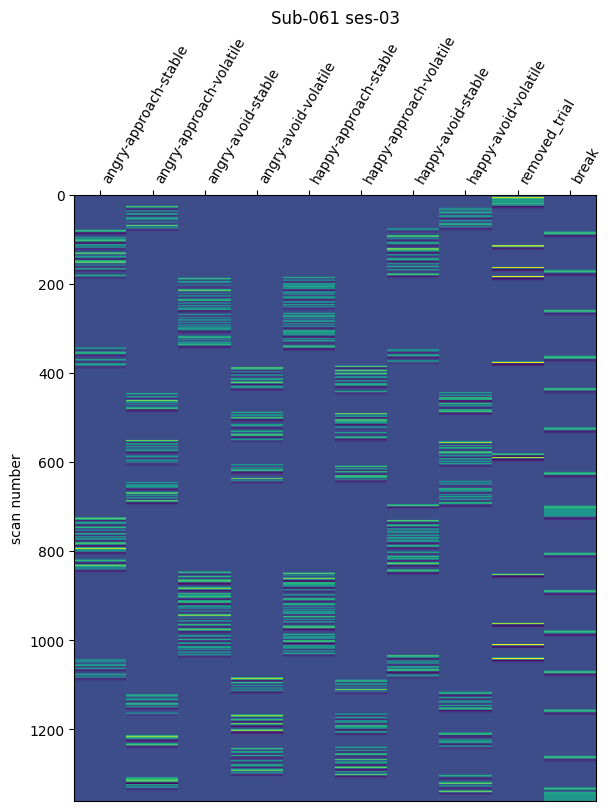

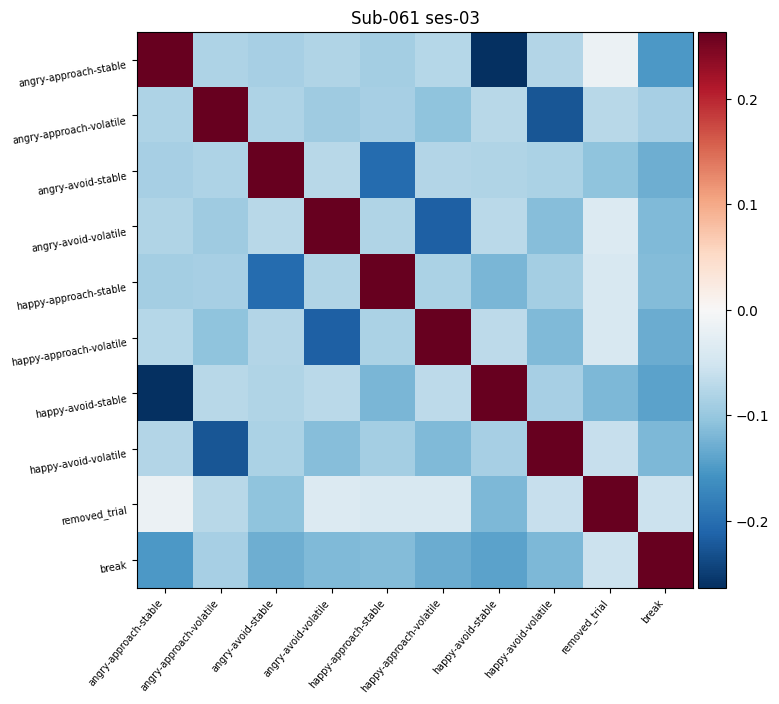

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 61 and session 4
30
60
90
120
150
182
210
240
270
300
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.071767   1.154454
1                                        NaN     5.071767   1.154454
2                              removed_trial     5.071767   1.154454
3                                        NaN     8.694099   0.599833
4                                        NaN     8.694099   0.599833
5                              removed_trial     8.694099   0.599

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


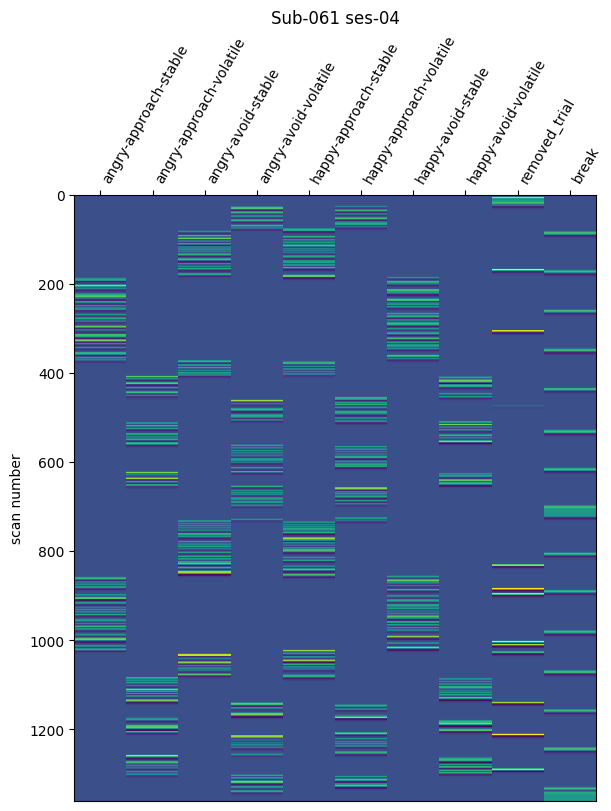

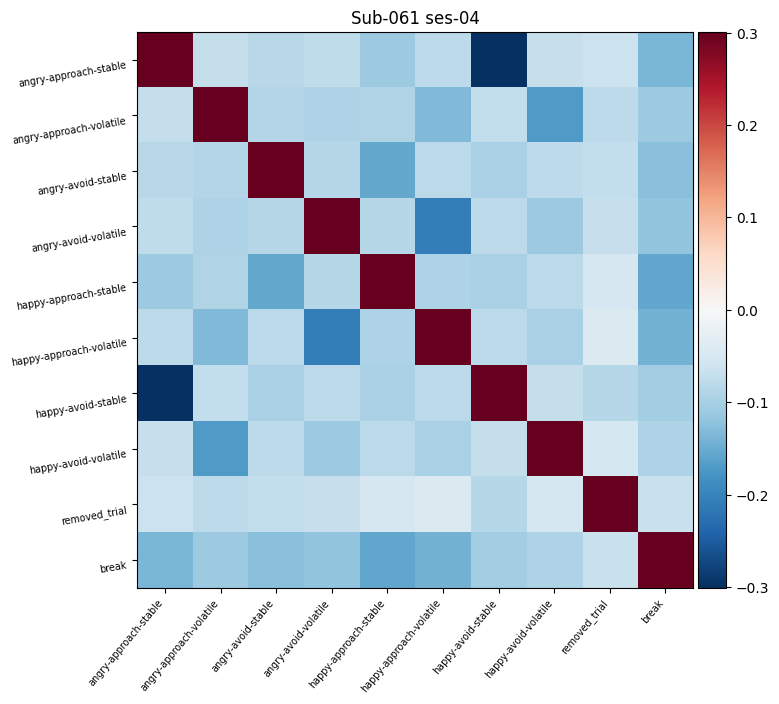

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 63 and session 2
34
62
90
120
150
180
210
240
270
306
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.072762   0.994871
1                                        NaN     5.072762   0.994871
2                              removed_trial     5.072762   0.994871
3                                        NaN     8.203613   0.806106
4                                        NaN     8.203613   0.806106
5                              removed_trial     8.203613   0.806

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


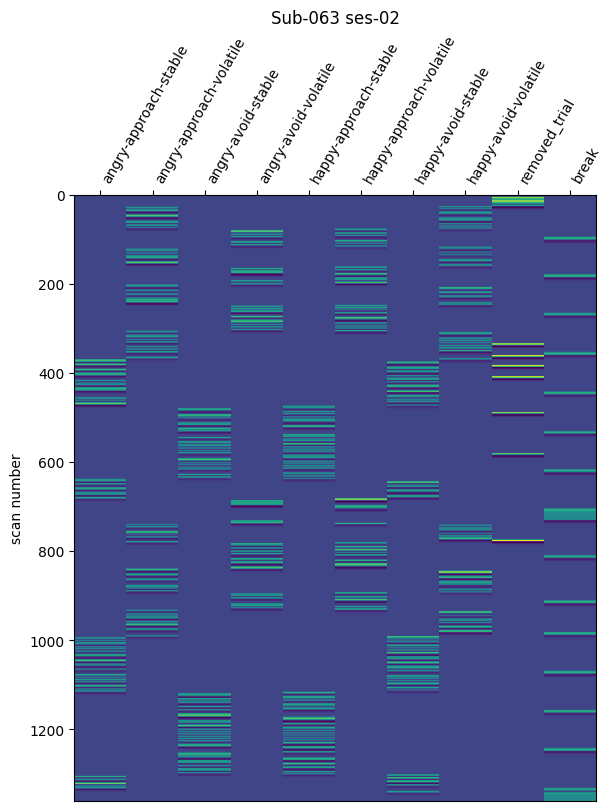

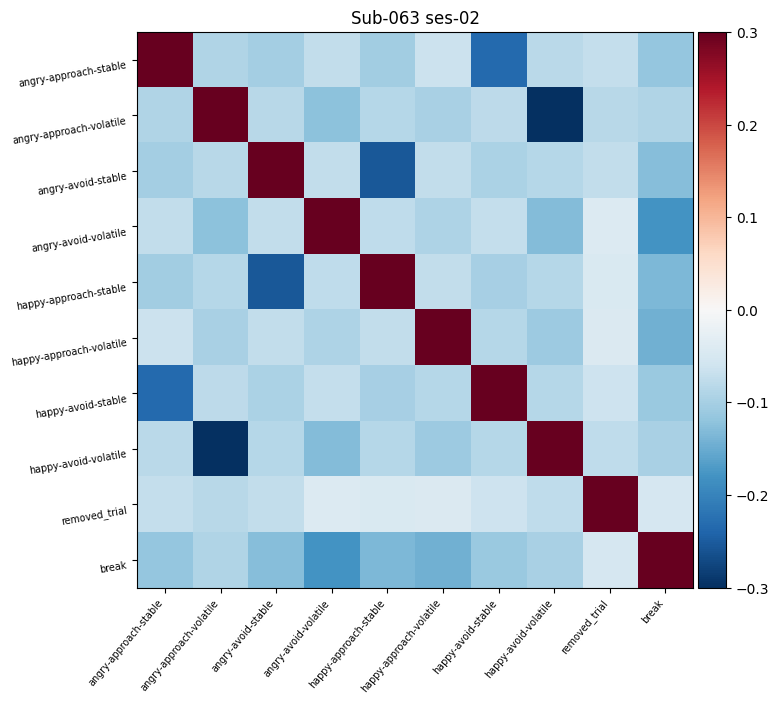

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 63 and session 3
32
66
90
120
150
180
210
242
270
300
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.105689   0.951116
1                                        NaN     5.105689   0.951116
2                              removed_trial     5.105689   0.951116
3                                        NaN     8.227928   0.670103
4                                        NaN     8.227928   0.670103
5                              removed_trial     8.227928   0.670

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


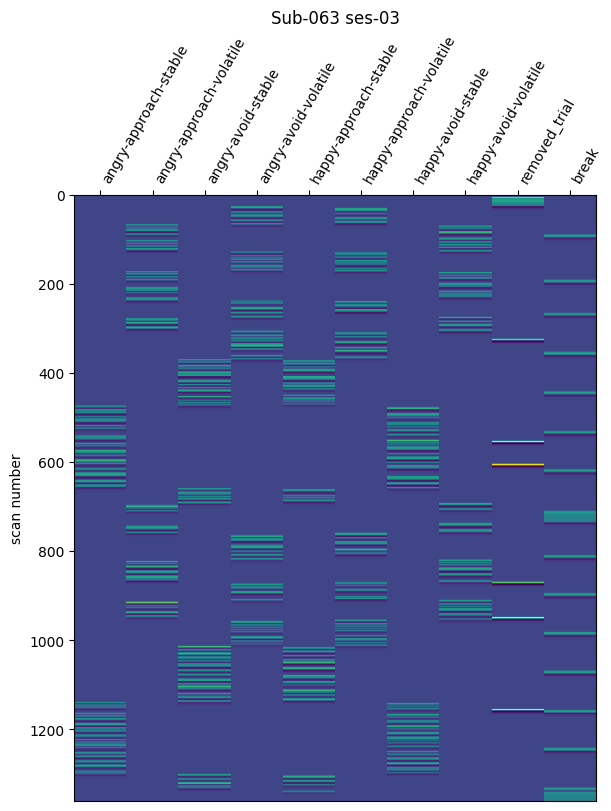

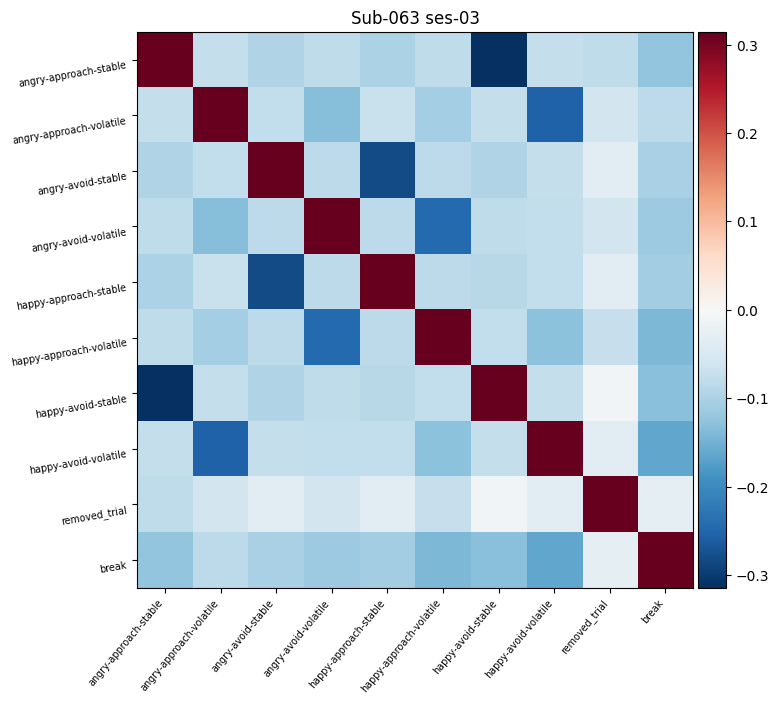

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 63 and session 4
30
60
90
120
156
186
210
240
270
302
330
360
394
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.047352   1.162335
1                                        NaN     5.047352   1.162335
2                              removed_trial     5.047352   1.162335
3                                        NaN     8.179487   0.828837
4                                        NaN     8.179487   0.828837
5                              removed_trial     8.179487   0.828

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


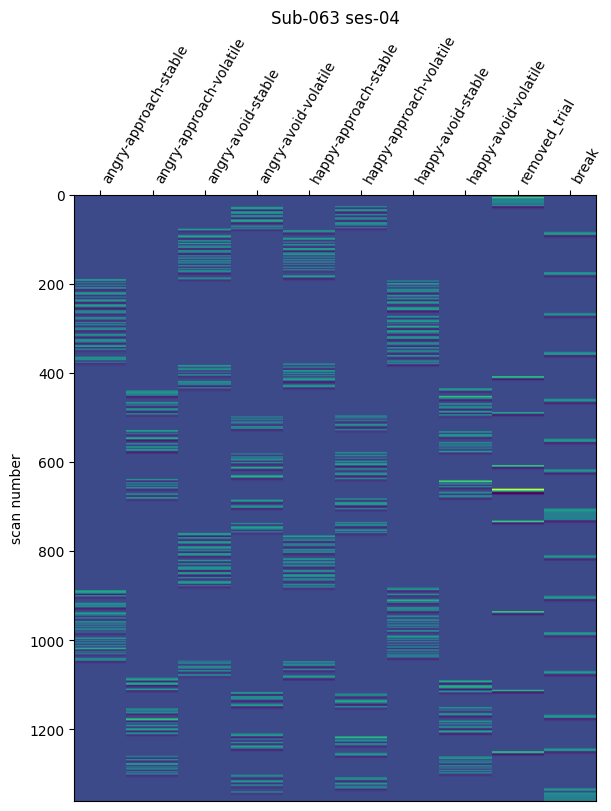

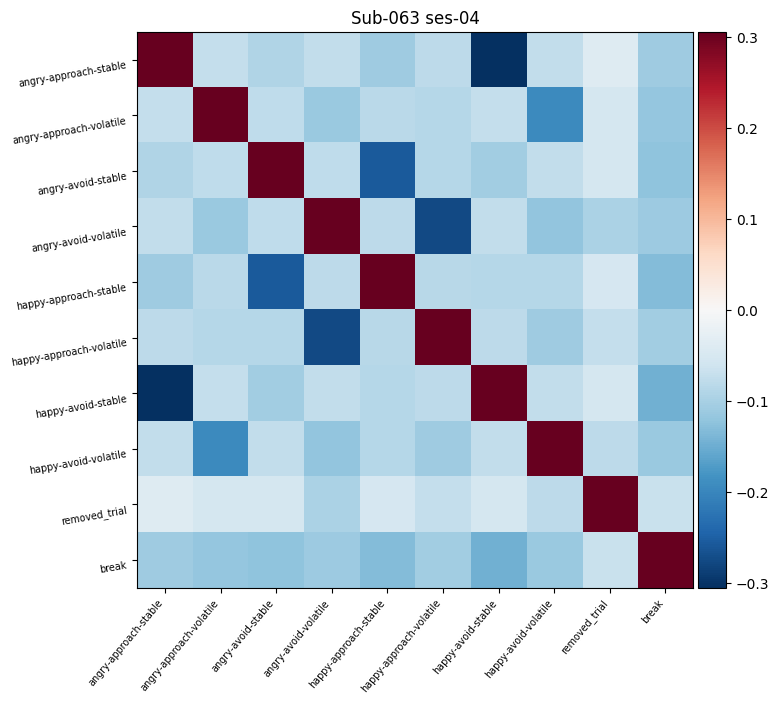

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 64 and session 2
30
62
96
120
150
180
210
246
270
300
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.064714   0.794265
1                                        NaN     5.064714   0.794265
2                              removed_trial     5.064714   0.794265
3                                        NaN     8.484492   0.825977
4                                        NaN     8.484492   0.825977
5                              removed_trial     8.484492   0.825

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


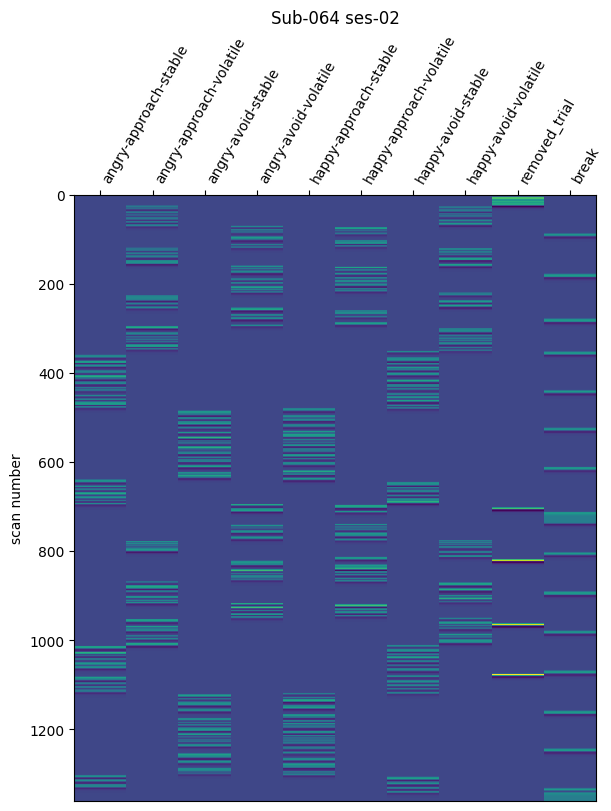

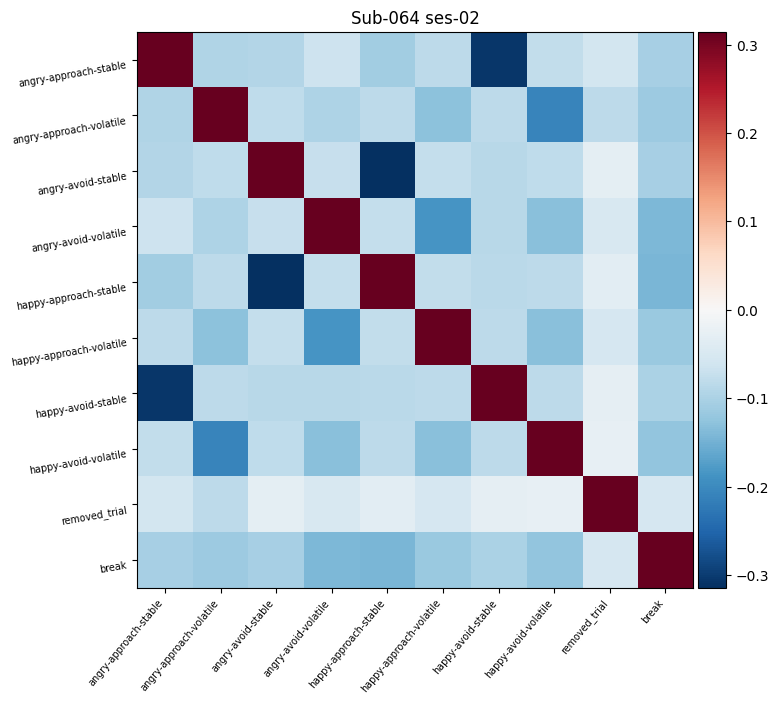

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 64 and session 3
34
62
90
120
150
180
210
242
270
306
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.065632   0.713433
1                                        NaN     5.065632   0.713433
2                              removed_trial     5.065632   0.713433
3                                        NaN     8.485260   0.621051
4                                        NaN     8.485260   0.621051
5                              removed_trial     8.485260   0.621

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


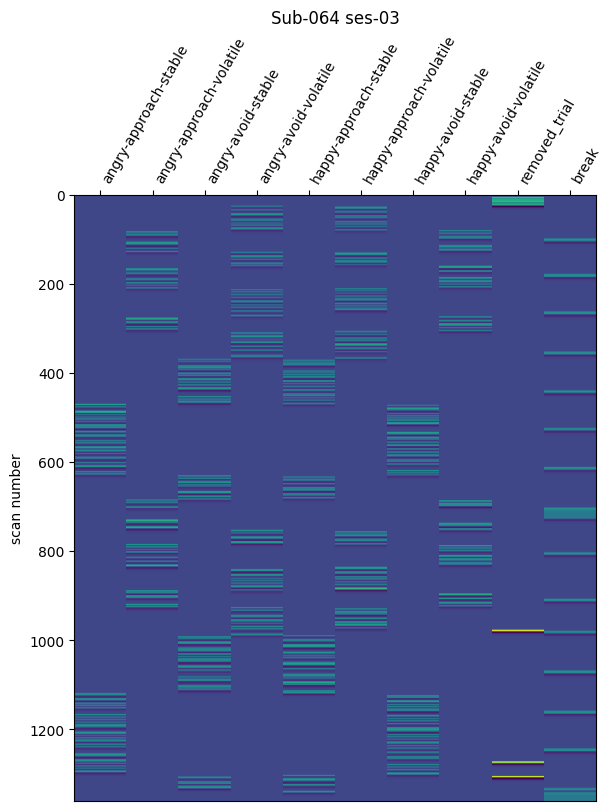

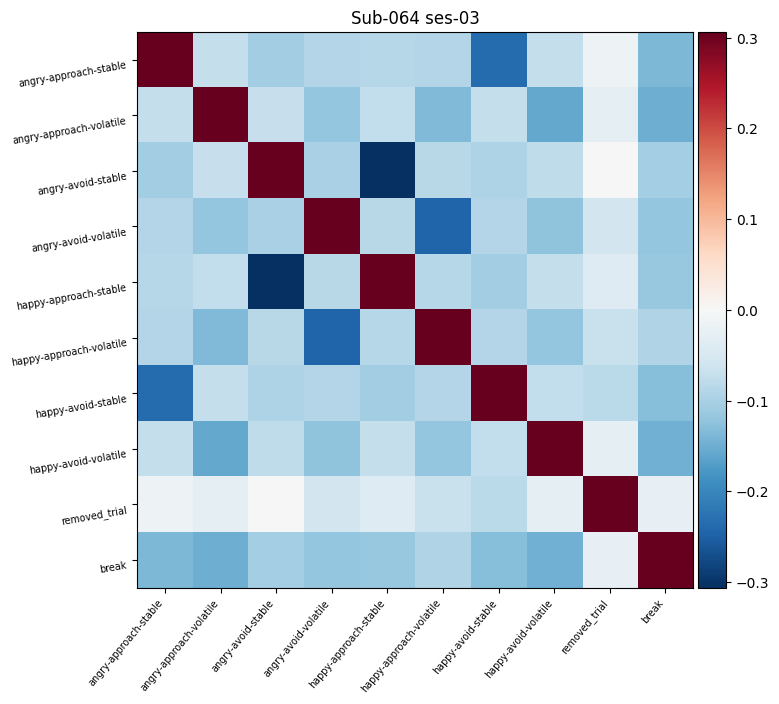

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 64 and session 4
30
60
90
120
156
186
210
242
270
300
330
366
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.046876   0.985282
1                                        NaN     5.046876   0.985282
2                              removed_trial     5.046876   0.985282
3                                        NaN     8.463912   0.870680
4                                        NaN     8.463912   0.870680
5                              removed_trial     8.463912   0.870

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


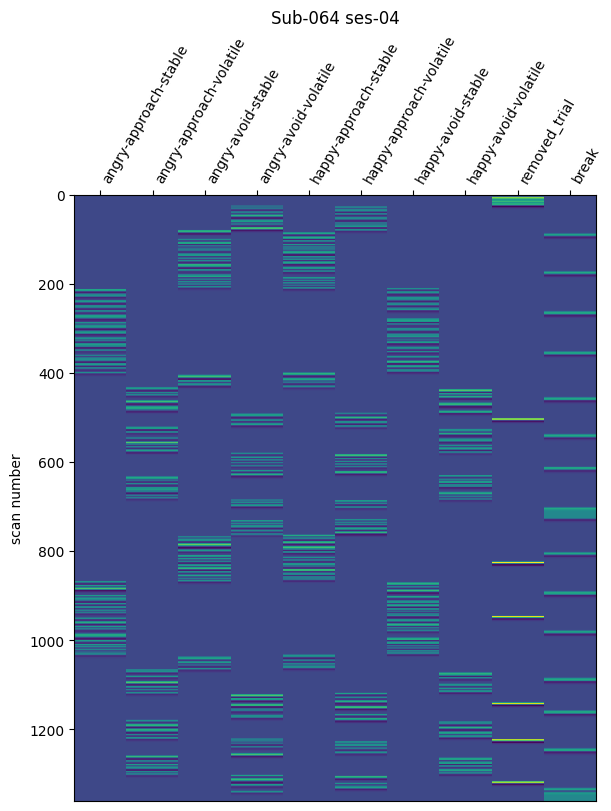

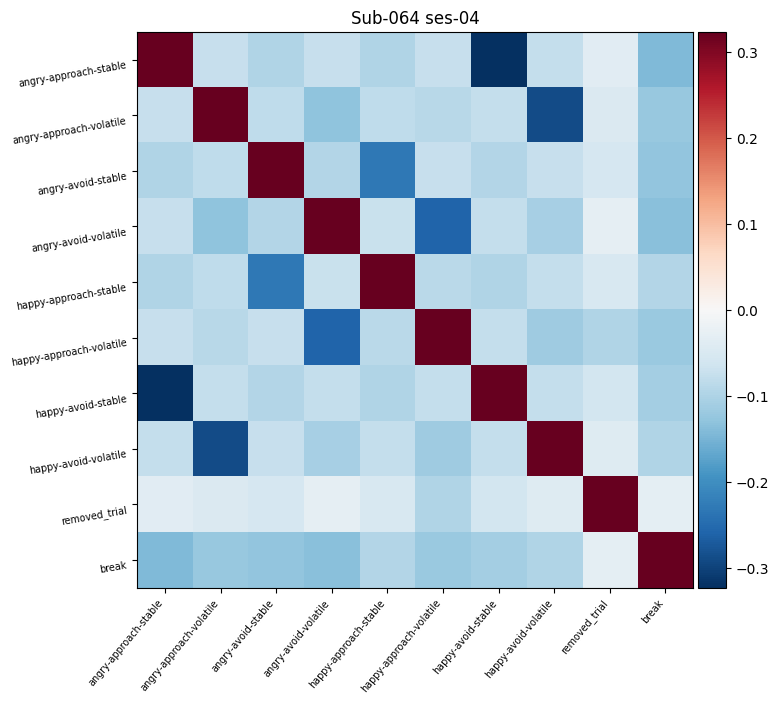

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 65 and session 2
30
62
94
120
150
180
210
246
270
300
330
360
392
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.063075   0.952190
1                                        NaN     5.063075   0.952190
2                              removed_trial     5.063075   0.952190
3                                        NaN     8.622567   0.798863
4                                        NaN     8.622567   0.798863
5                              removed_trial     8.622567   0.798

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


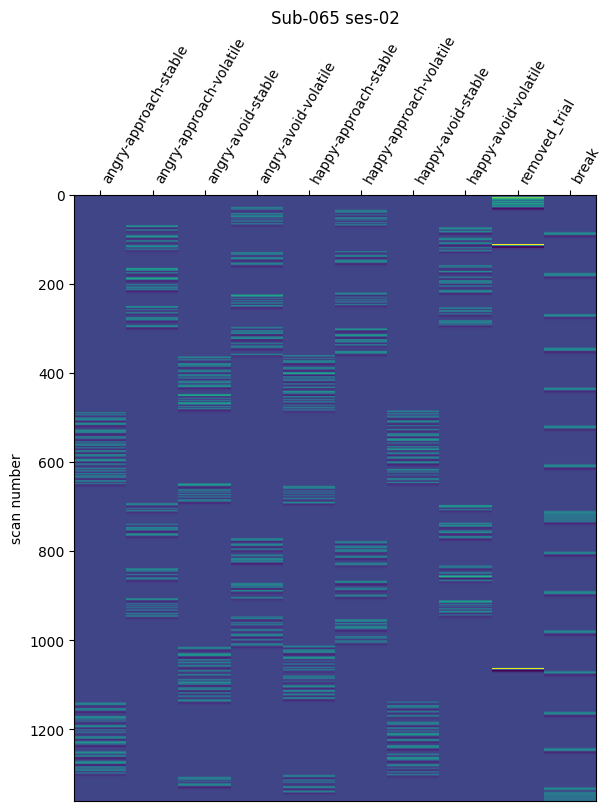

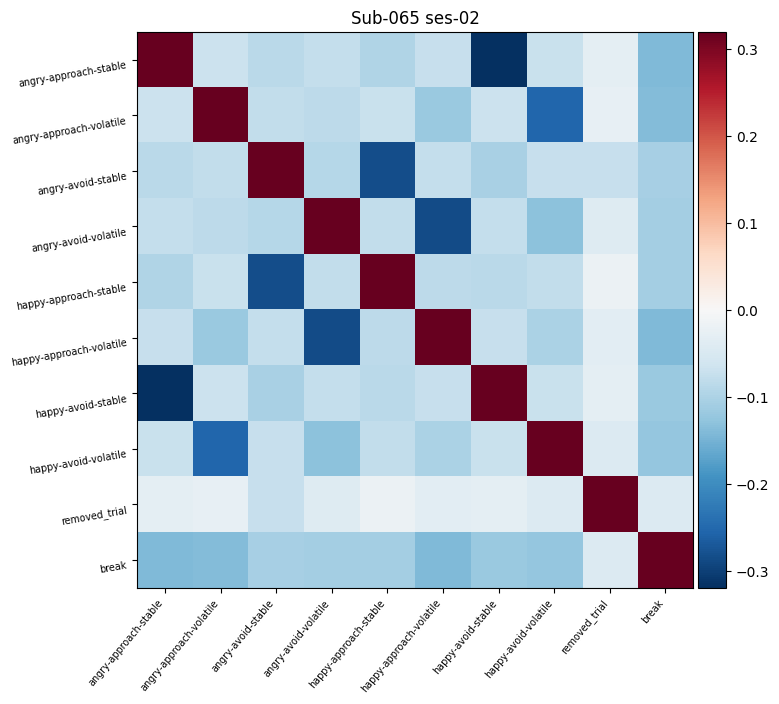

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 65 and session 3
30
60
90
120
150
186
210
240
270
300
330
360
396
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.059491   0.701746
1                                        NaN     5.059491   0.701746
2                              removed_trial     5.059491   0.701746
3                                        NaN     8.627601   0.785704
4                                        NaN     8.627601   0.785704
5                              removed_trial     8.627601   0.785

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


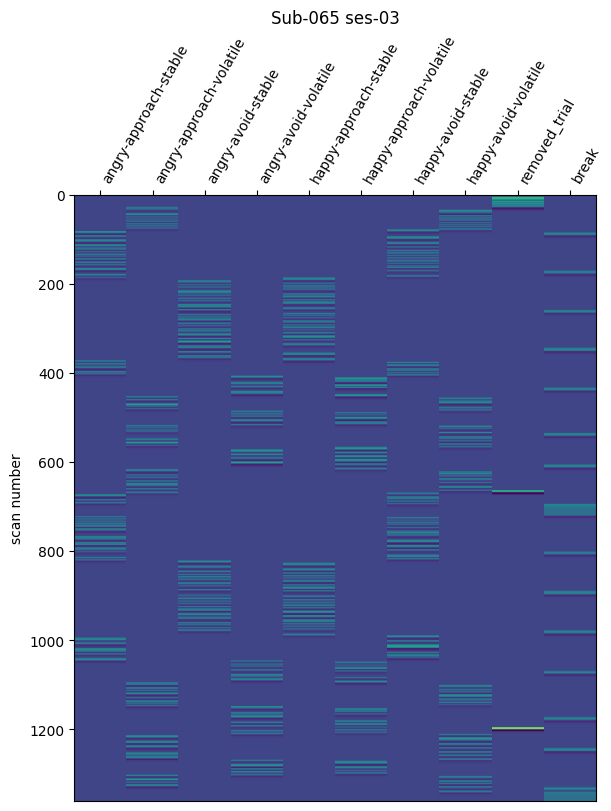

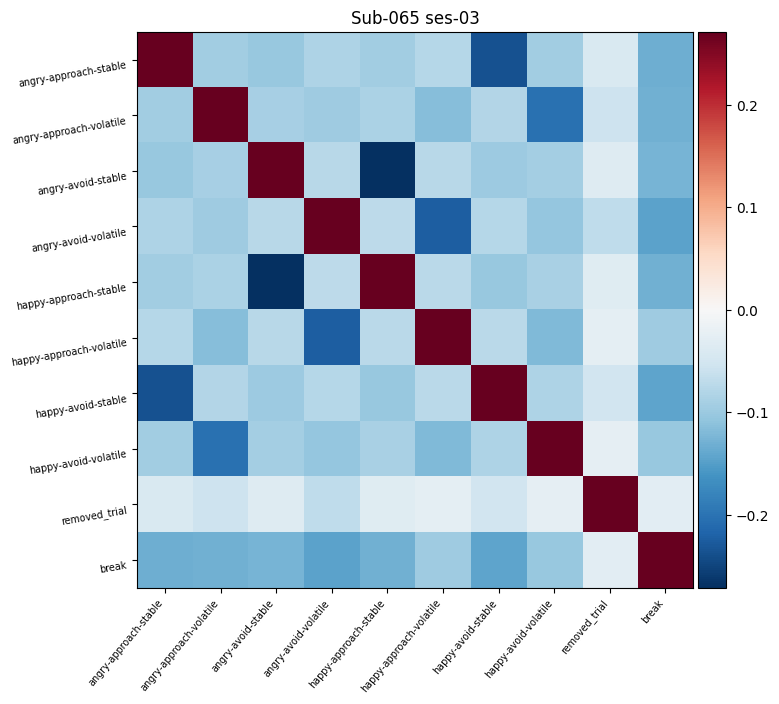

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 65 and session 4
30
60
90
120
150
182
212
240
270
300
330
360
392
426
450
451
                                  trial_type        onset   duration
0                                        NaN     5.094010   0.592554
1                                        NaN     5.094010   0.592554
2                              removed_trial     5.094010   0.592554
3                                        NaN     8.658676   0.677585
4                                        NaN     8.658676   0.677585
5                              removed_trial     8.658676   0.677

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


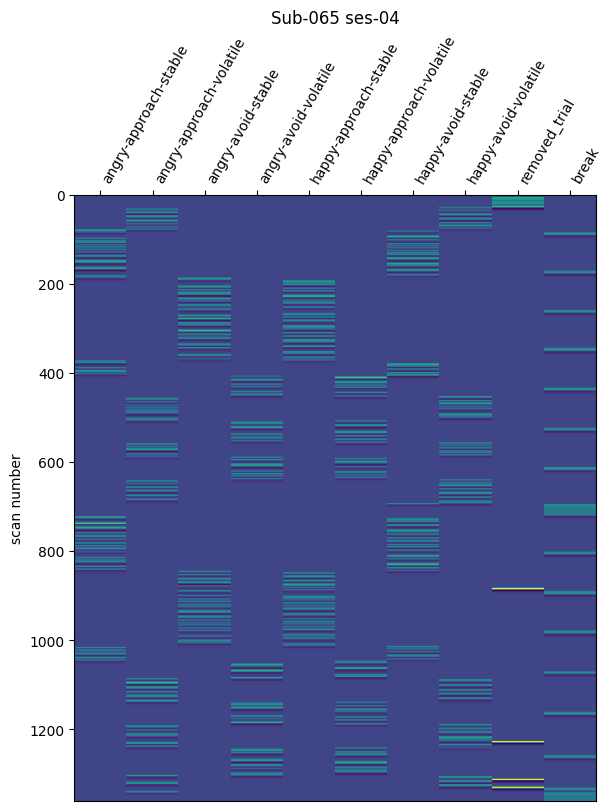

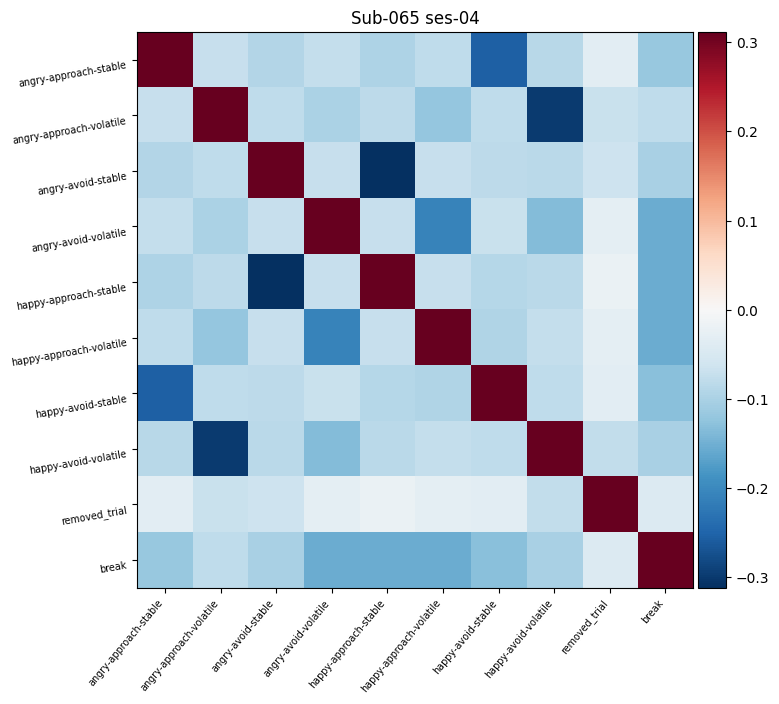

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 66 and session 2
30
66
90
122
150
186
210
242
270
302
330
360
392
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.040699   1.371232
1                                        NaN     5.040699   1.371232
2                              removed_trial     5.040699   1.371232
3                                        NaN     8.827794   0.618921
4                                        NaN     8.827794   0.618921
5                              removed_trial     8.827794   0.618

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


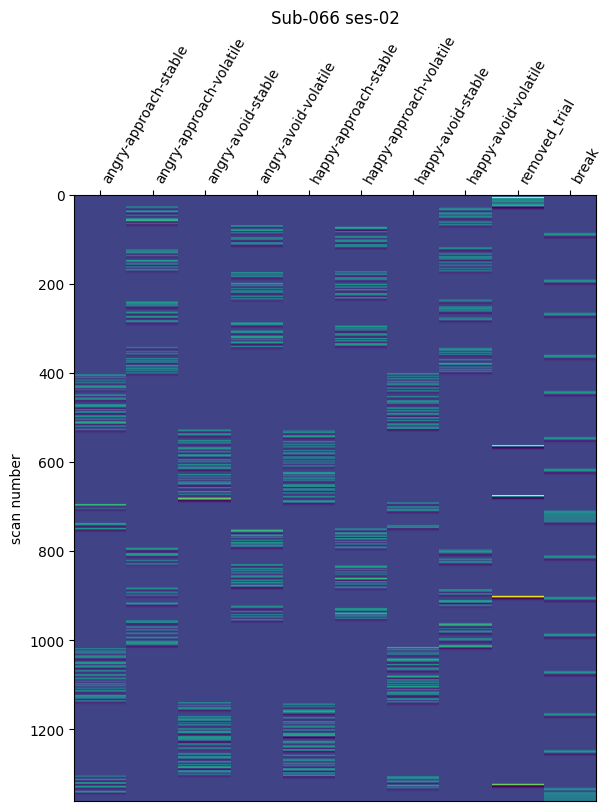

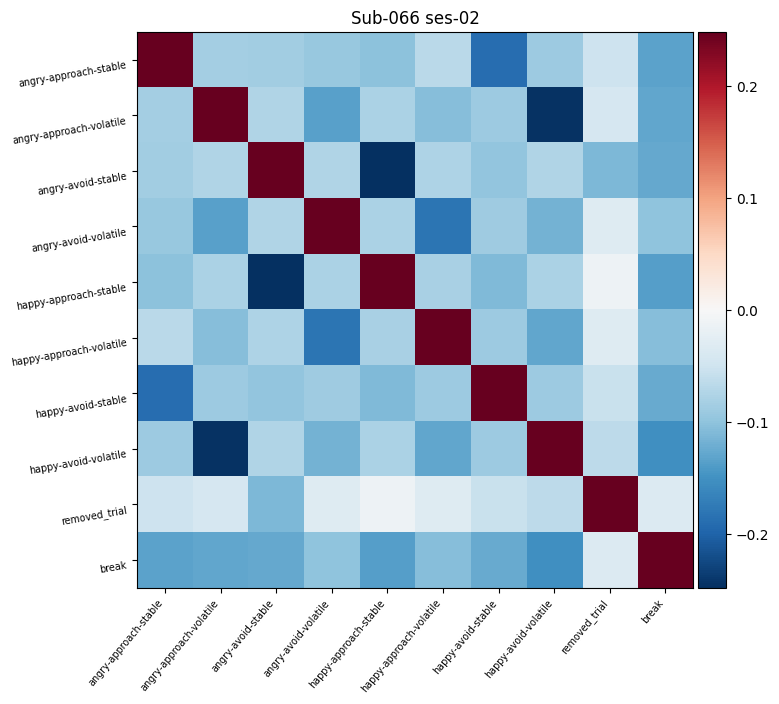

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.07347538574577515% of volumes have been removed.

Creating event file for subject 66 and session 3
34
66
96
120
150
180
210
240
270
302
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.124720   0.720707
1                                        NaN     5.124720   0.720707
2                              removed_trial     5.124720   0.720707
3                                        NaN     8.917536   0.686040
4                                        NaN     8.917536   0.686040
5                              removed_trial     

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


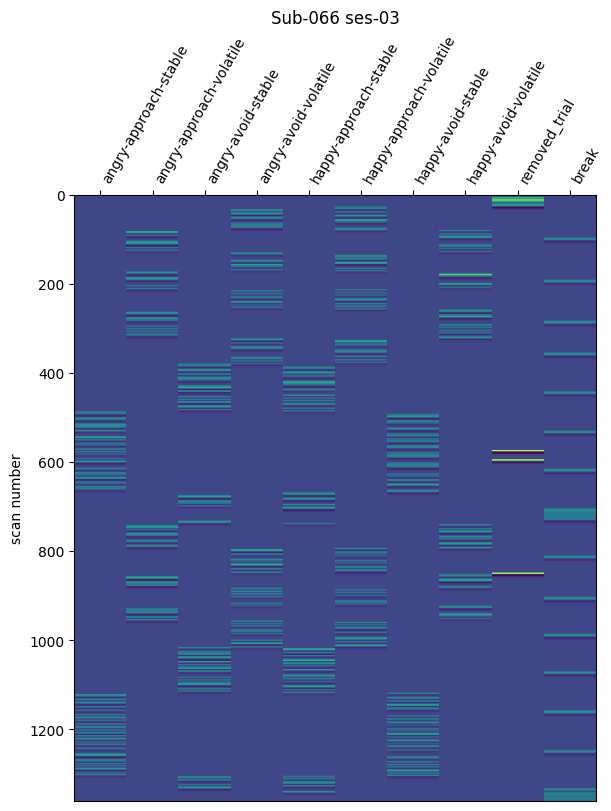

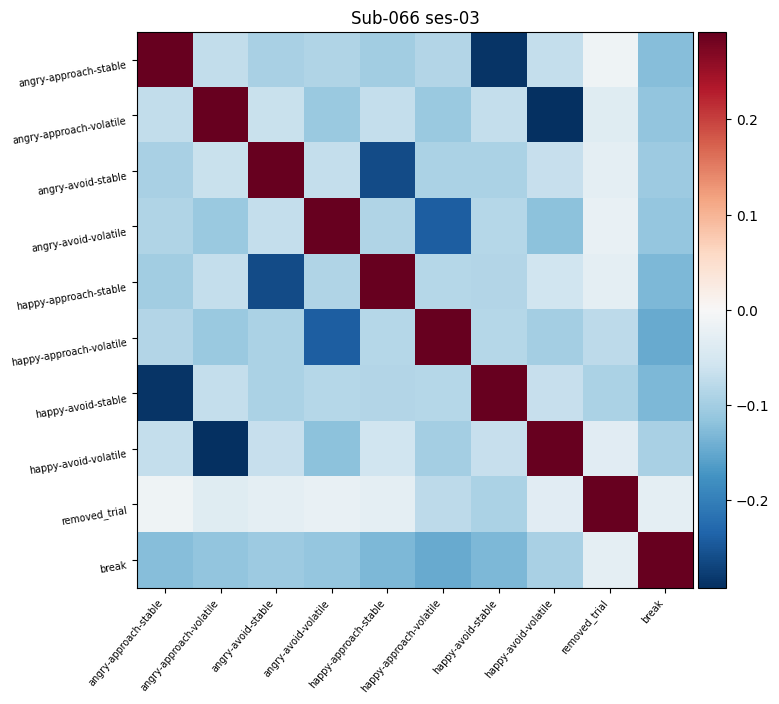

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 66 and session 4
30
60
90
126
156
180
210
240
270
300
330
360
394
422
450
451
                                  trial_type        onset   duration
0                                        NaN     5.057459   0.942878
1                                        NaN     5.057459   0.942878
2                              removed_trial     5.057459   0.942878
3                                        NaN     8.839267   0.622507
4                                        NaN     8.839267   0.622507
5                              removed_trial     8.839267   0.622

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


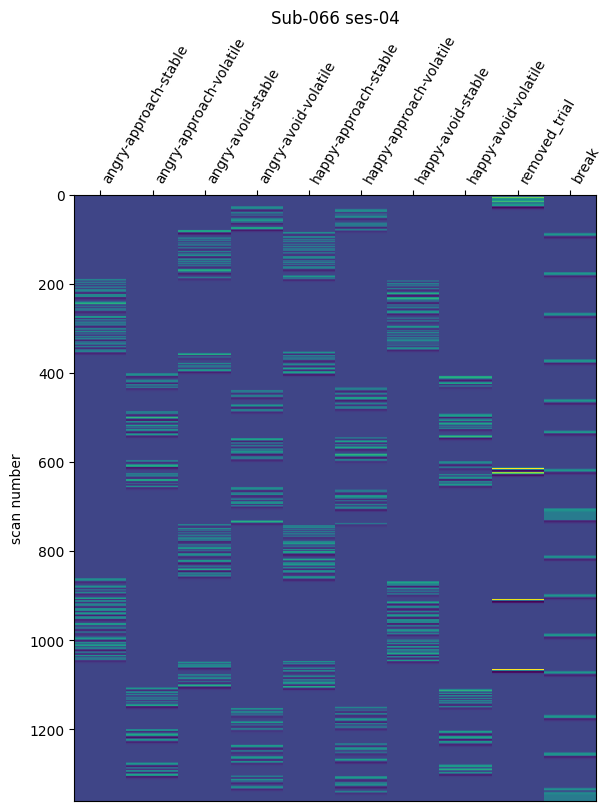

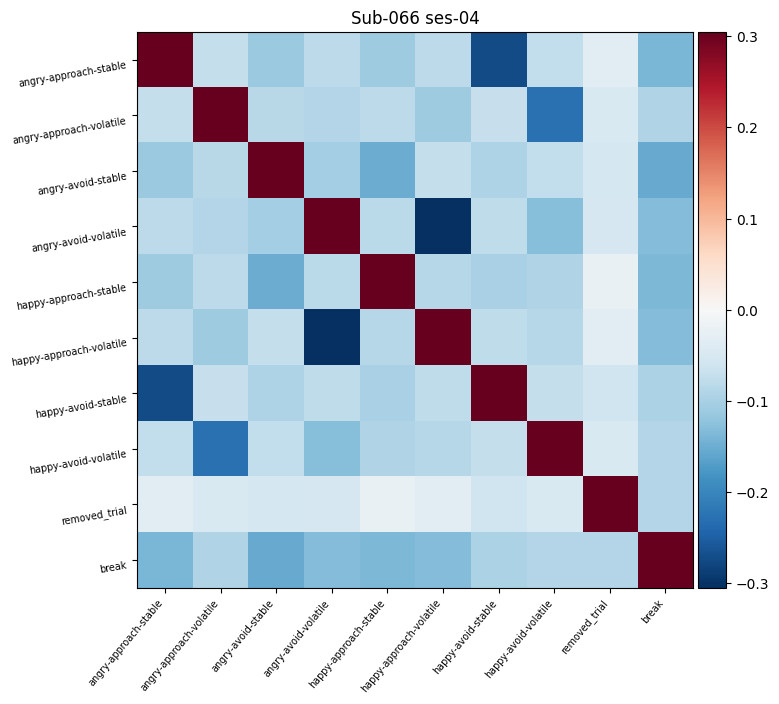

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.7347538574577517% of volumes have been removed.

Creating event file for subject 67 and session 2
34
60
90
120
150
182
210
240
270
300
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.065827   1.371198
1                                        NaN     5.065827   1.371198
2                              removed_trial     5.065827   1.371198
3                                        NaN     8.794581   0.871585
4                                        NaN     8.794581   0.871585
5                              removed_trial     8

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


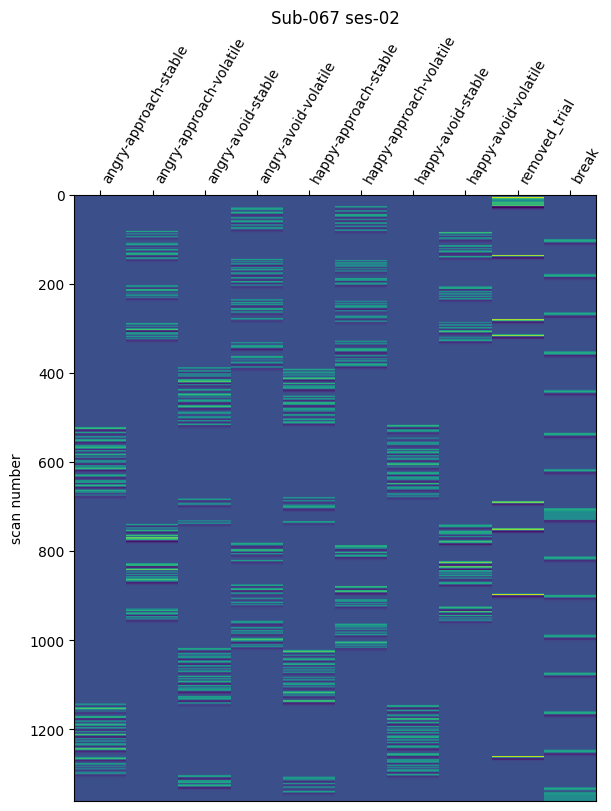

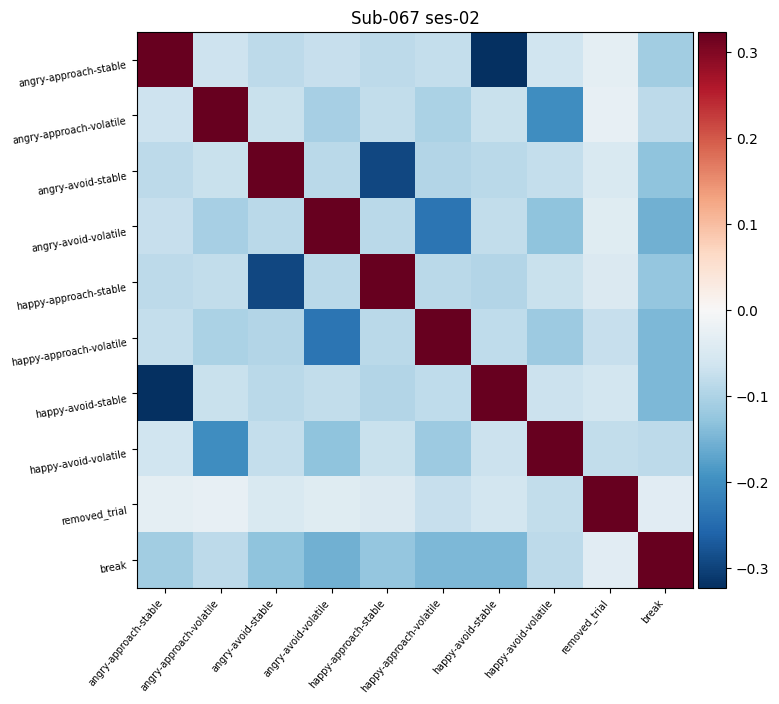

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 67 and session 3
30
60
90
120
150
182
214
240
270
300
330
366
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.049191   1.168560
1                                        NaN     5.049191   1.168560
2                              removed_trial     5.049191   1.168560
3                                        NaN     8.774901   1.084506
4                                        NaN     8.774901   1.084506
5                              removed_trial     8.774901   1.084

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


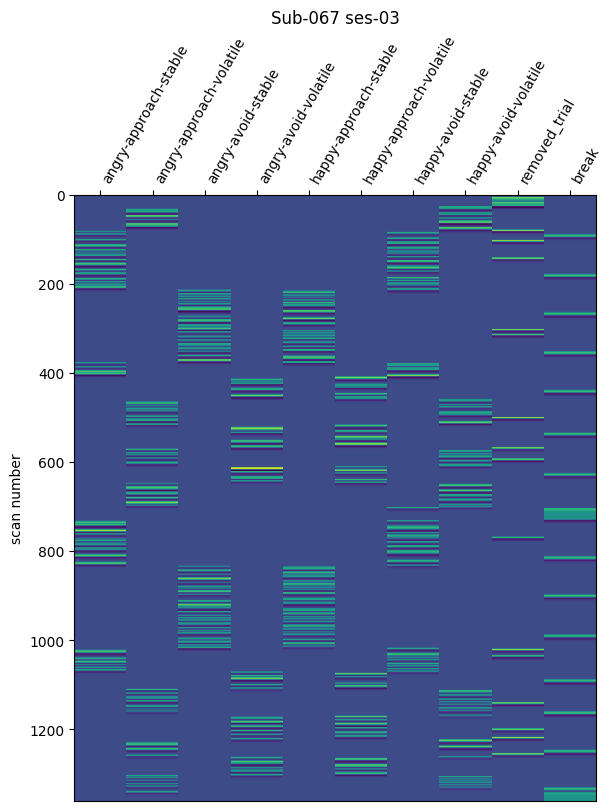

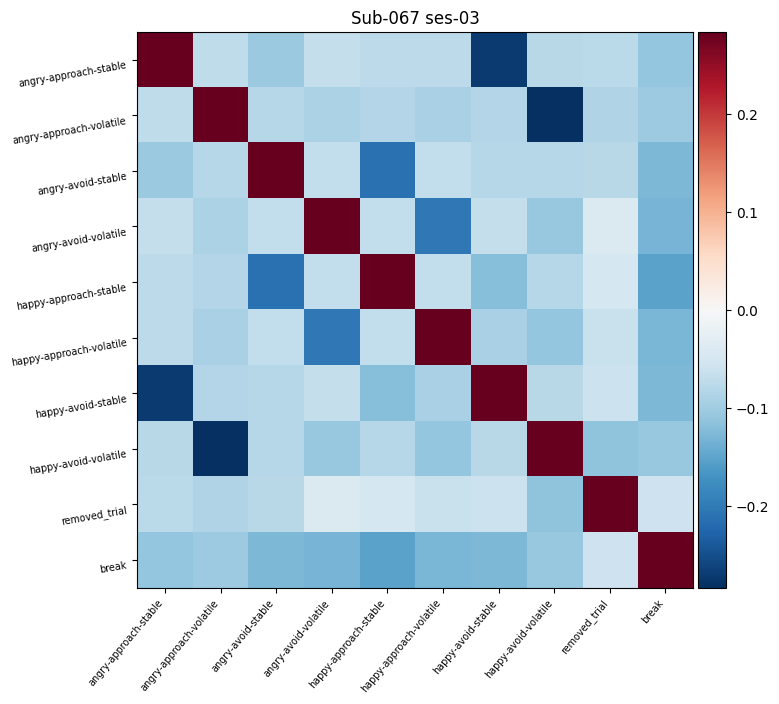

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 67 and session 4
30
60
90
120
150
186
214
240
270
300
330
362
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.098934   1.079459
1                                        NaN     5.098934   1.079459
2                              removed_trial     5.098934   1.079459
3                                        NaN     8.825755   0.800864
4                                        NaN     8.825755   0.800864
5                              removed_trial     8.825755   0.800

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


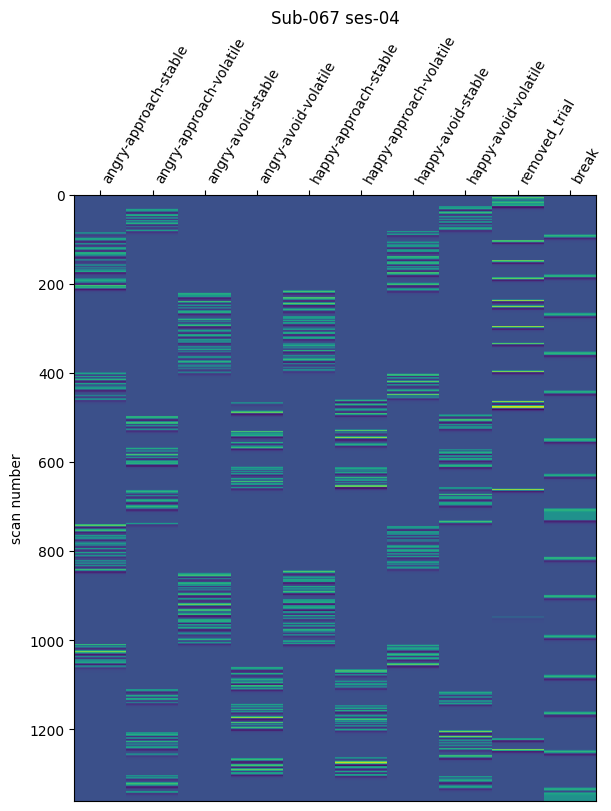

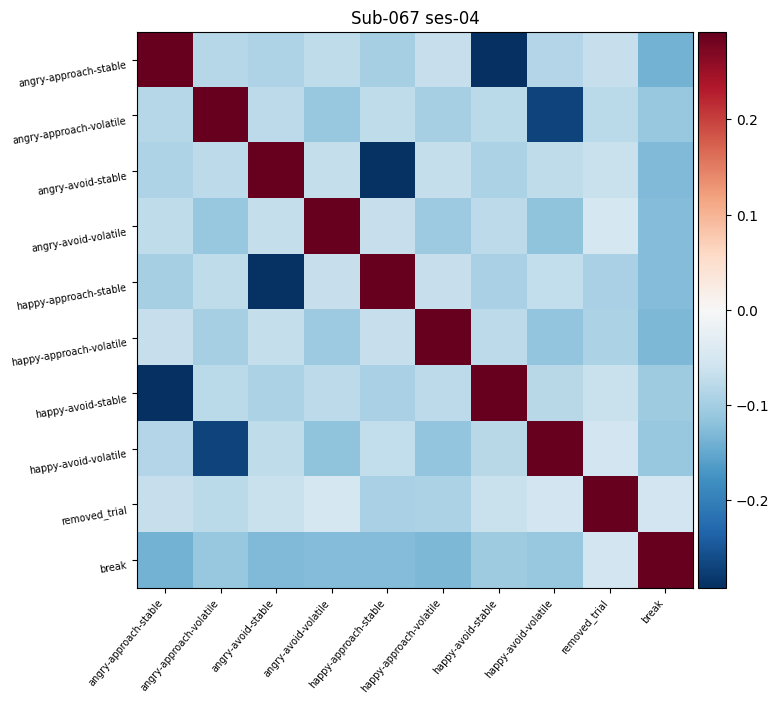

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 68 and session 2
34
60
90
120
150
180
210
240
270
300
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.069683   1.106952
1                                        NaN     5.069683   1.106952
2                              removed_trial     5.069683   1.106952
3                                        NaN     9.364369   0.711688
4                                        NaN     9.364369   0.711688
5                              removed_trial     9.364369   0.711

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


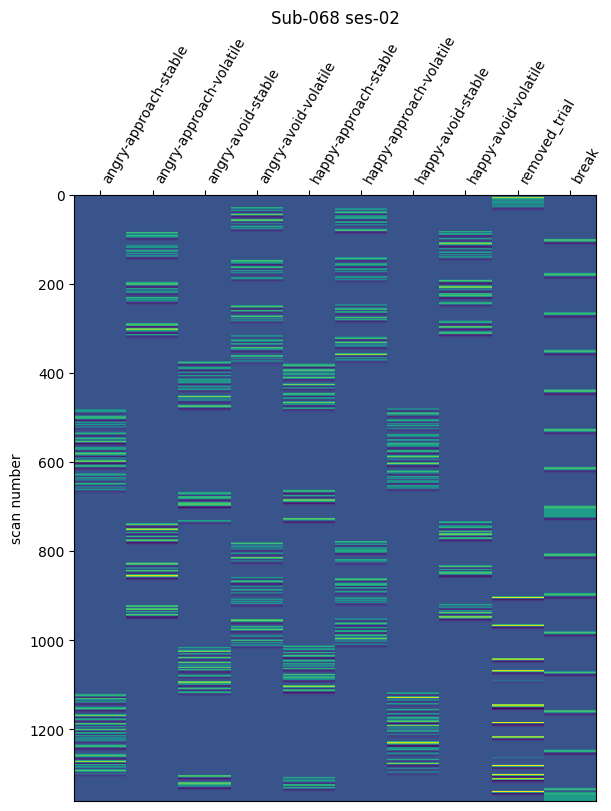

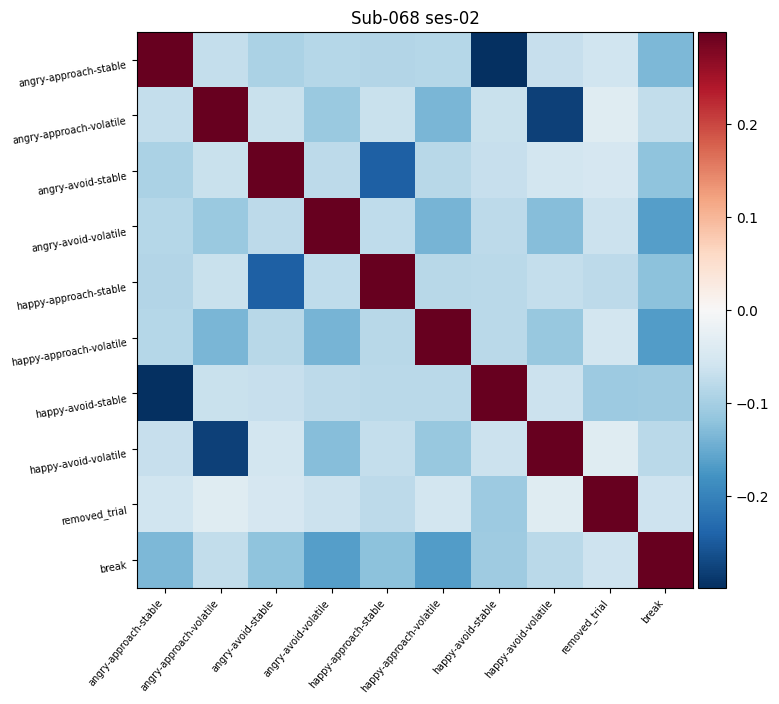

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 68 and session 3
30
60
90
126
156
180
212
240
270
300
330
366
394
426
450
451
                                  trial_type        onset   duration
0                                        NaN     5.111014   0.740692
1                                        NaN     5.111014   0.740692
2                              removed_trial     5.111014   0.740692
3                                        NaN     9.394455   0.677011
4                                        NaN     9.394455   0.677011
5                              removed_trial     9.394455   0.677

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


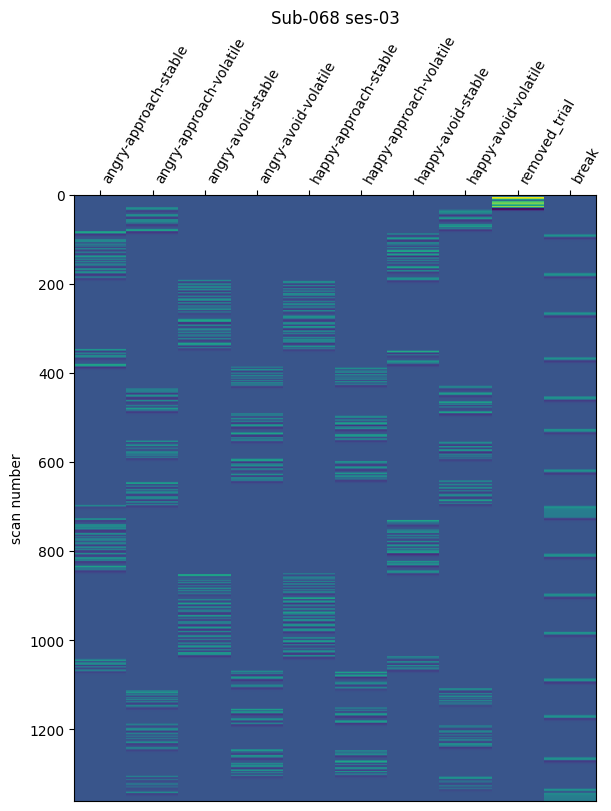

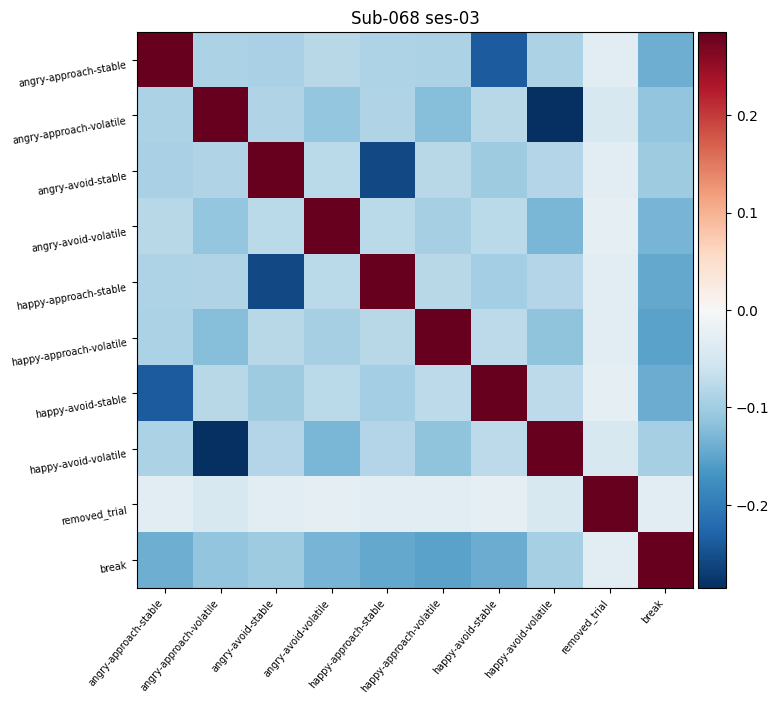

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 68 and session 4
30
60
96
120
150
180
210
240
270
300
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.126237   0.709906
1                                        NaN     5.126237   0.709906
2                              removed_trial     5.126237   0.709906
3                                        NaN     9.419756   0.832635
4                                        NaN     9.419756   0.832635
5                              removed_trial     9.419756   0.832

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


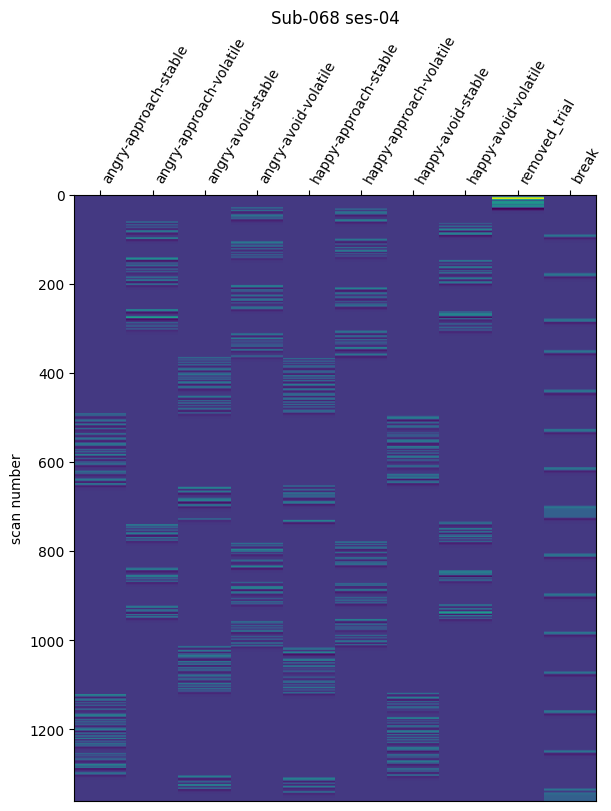

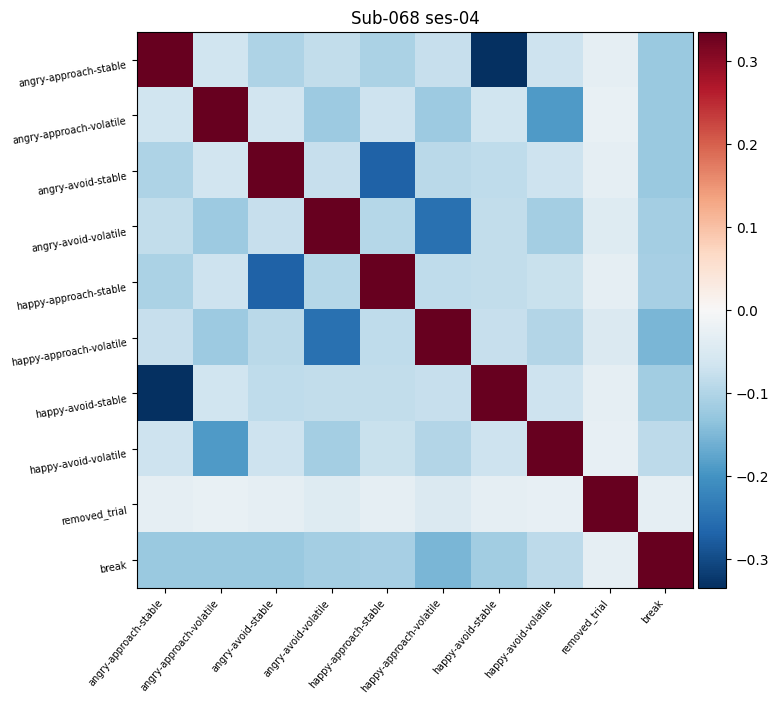

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 69 and session 2
30
60
90
120
154
186
210
240
270
300
330
362
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.073406   0.872921
1                                        NaN     5.073406   0.872921
2                              removed_trial     5.073406   0.872921
3                                        NaN     9.885800   0.751194
4                                        NaN     9.885800   0.751194
5                              removed_trial     9.885800   0.751

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


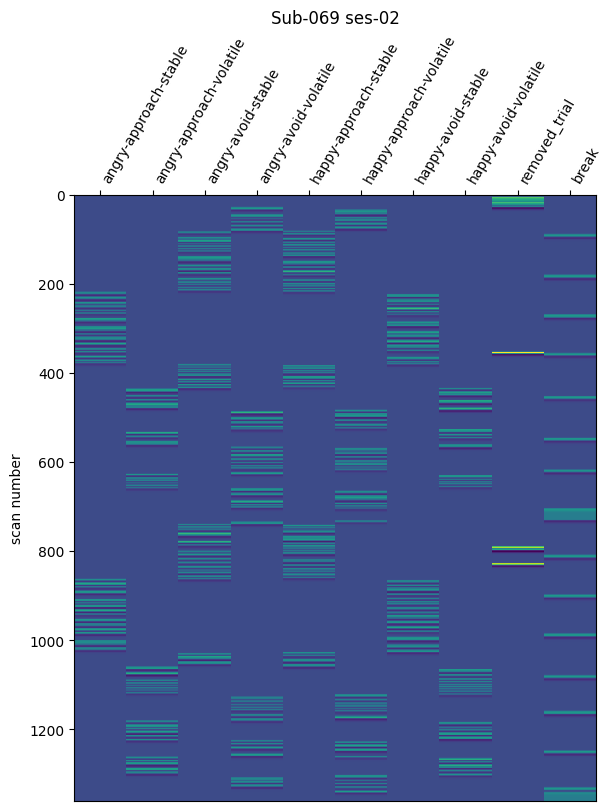

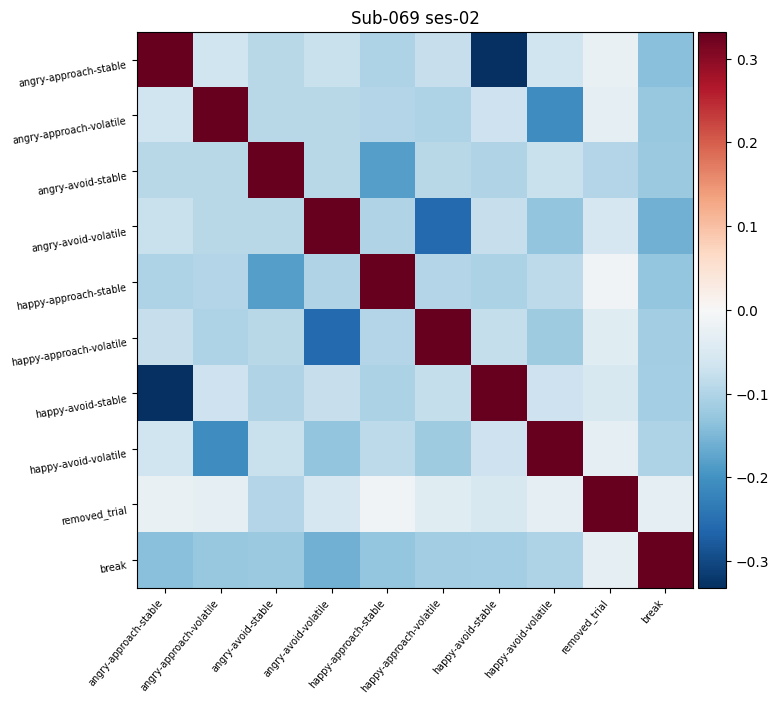

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 69 and session 3
30
60
90
120
150
180
210
240
270
300
330
360
392
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.084223   0.663450
1                                        NaN     5.084223   0.663450
2                              removed_trial     5.084223   0.663450
3                                        NaN     9.897606   0.731920
4                                        NaN     9.897606   0.731920
5                              removed_trial     9.897606   0.731

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


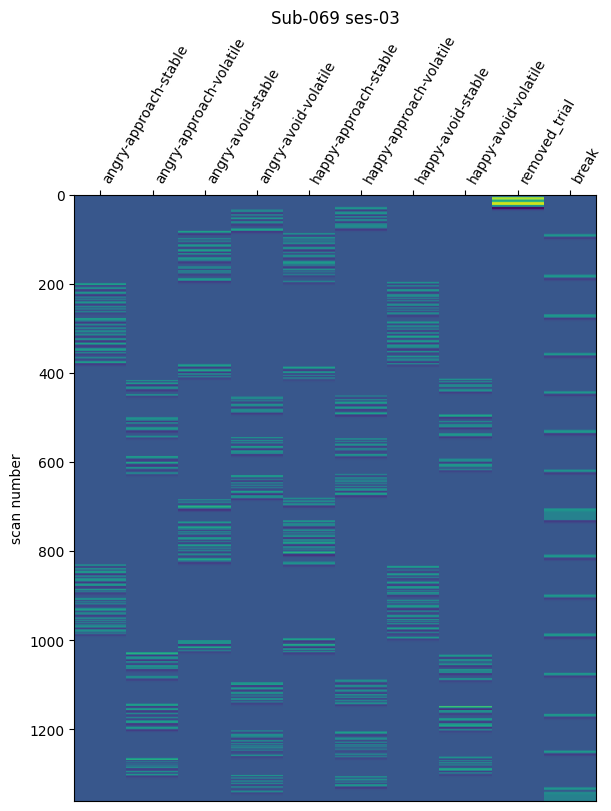

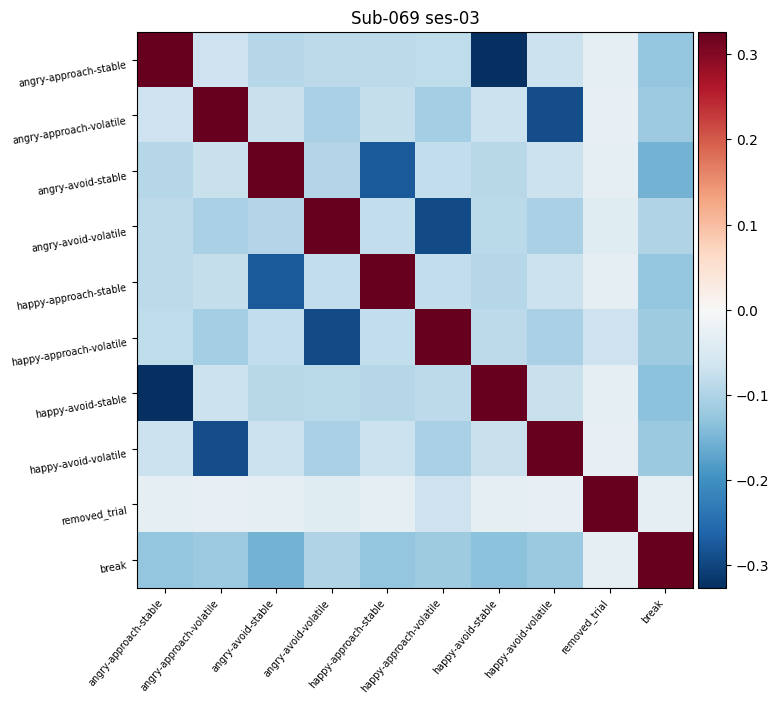

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.1469507714915503% of volumes have been removed.

Creating event file for subject 69 and session 4
34
62
92
120
150
180
210
240
270
306
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.111201   0.778380
1                                        NaN     5.111201   0.778380
2                              removed_trial     5.111201   0.778380
3                                        NaN     9.933425   0.646917
4                                        NaN     9.933425   0.646917
5                              removed_trial     9

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


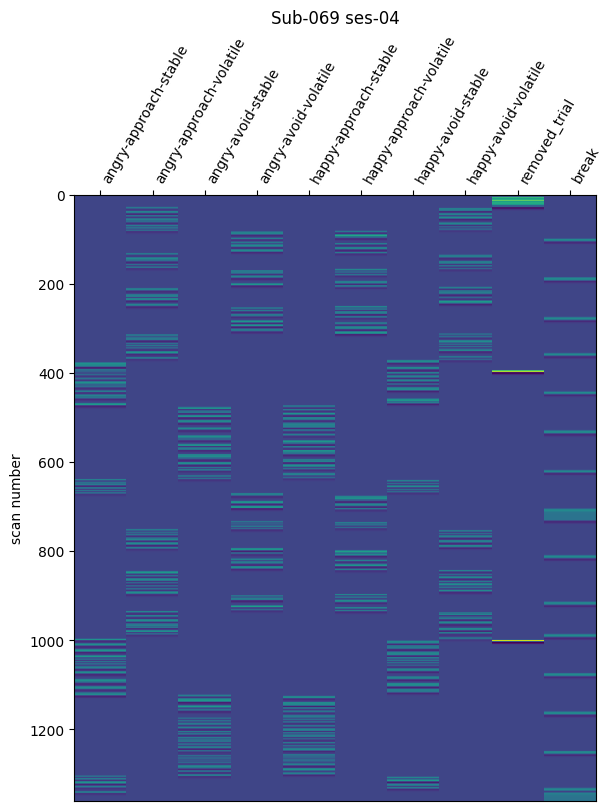

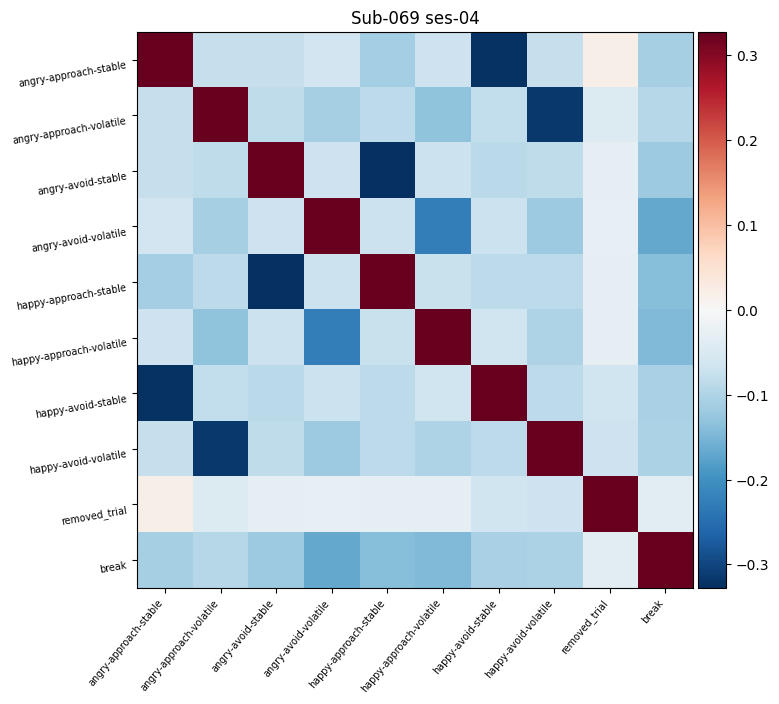

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 70 and session 2
32
66
94
120
150
180
210
240
270
300
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.066117   0.802467
1                                        NaN     5.066117   0.802467
2                              removed_trial     5.066117   0.802467
3                                        NaN     9.778339   0.808842
4                                        NaN     9.778339   0.808842
5                              removed_trial     9.778339   0.808

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


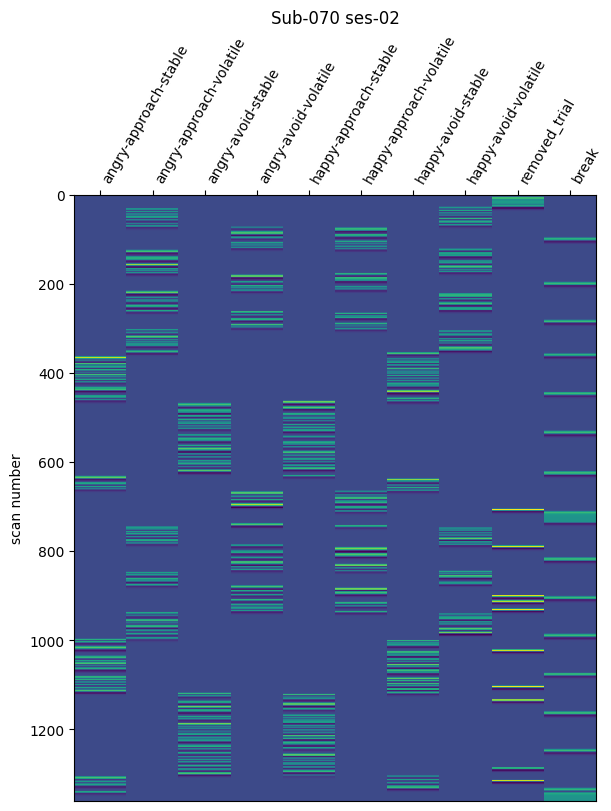

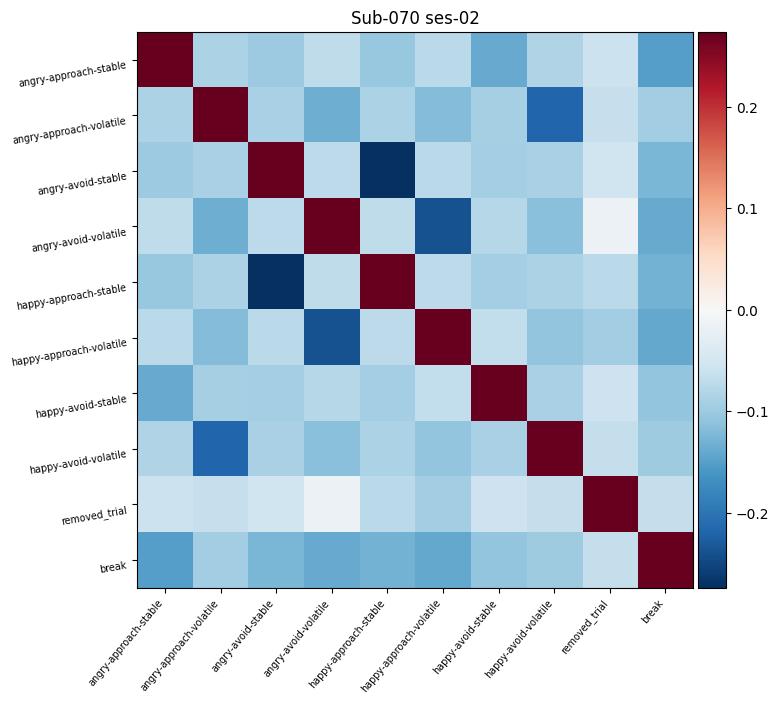

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.1469507714915503% of volumes have been removed.

Creating event file for subject 70 and session 3
30
62
92
120
150
180
210
242
274
300
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.104048   1.107055
1                                        NaN     5.104048   1.107055
2                              removed_trial     5.104048   1.107055
3                                        NaN     9.802995   0.712713
4                                        NaN     9.802995   0.712713
5                              removed_trial     9

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


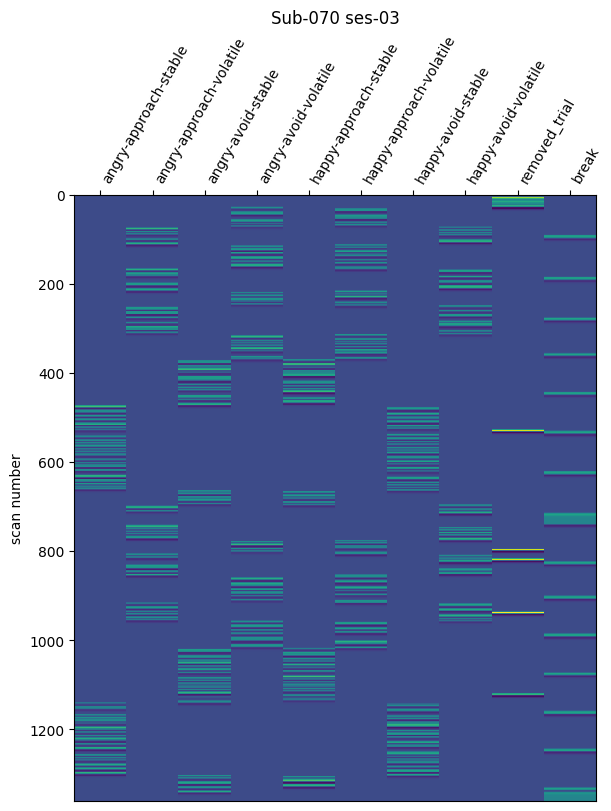

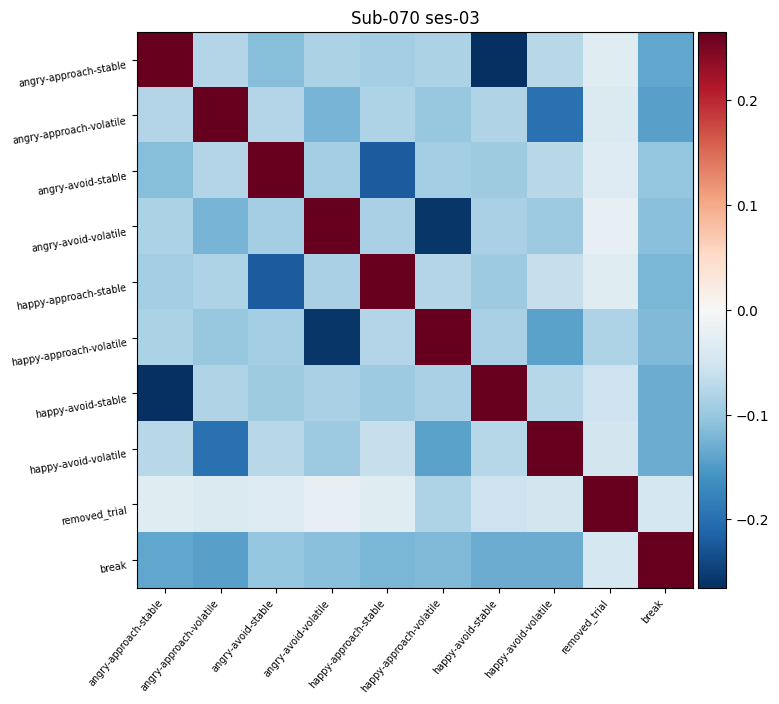

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 70 and session 4
30
60
90
120
150
180
210
240
270
300
330
360
390
426
450
451
                                  trial_type        onset   duration
0                                        NaN     5.136982   0.717771
1                                        NaN     5.136982   0.717771
2                              removed_trial     5.136982   0.717771
3                                        NaN     9.841144   0.887983
4                                        NaN     9.841144   0.887983
5                              removed_trial     9.841144   0.887

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


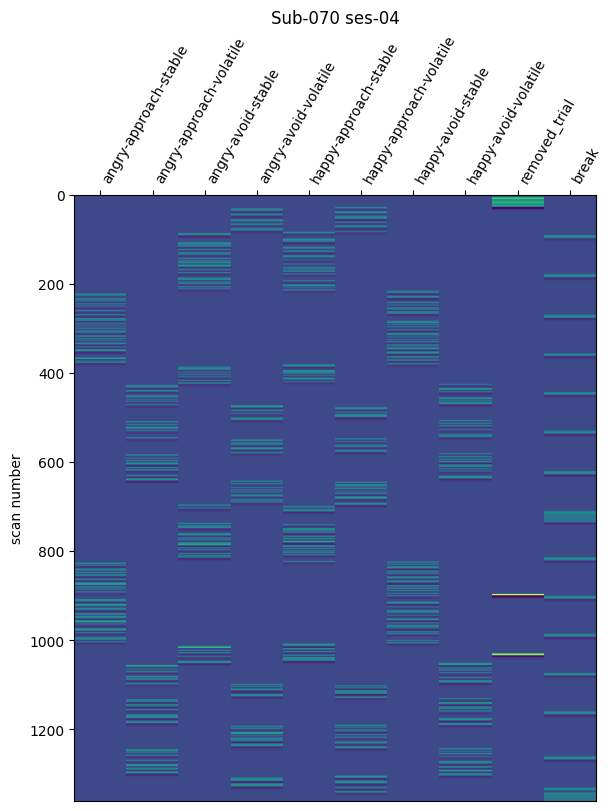

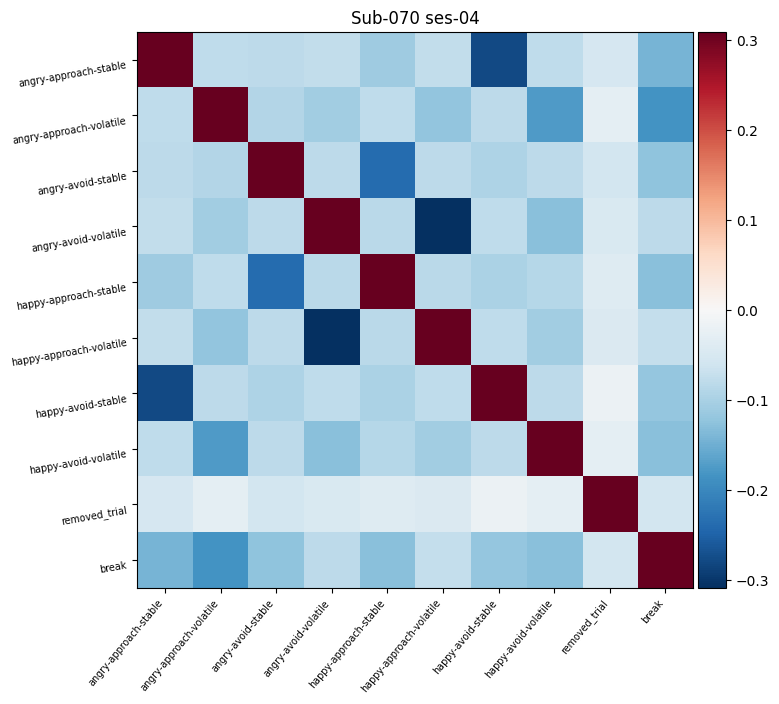

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 71 and session 2
30
60
90
120
150
180
210
240
270
300
330
360
390
426
450
451
                                  trial_type        onset   duration
0                                        NaN     5.048888   1.372409
1                                        NaN     5.048888   1.372409
2                              removed_trial     5.048888   1.372409
3                                        NaN     8.513922   0.837932
4                                        NaN     8.513922   0.837932
5                              removed_trial     8.513922   0.837

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


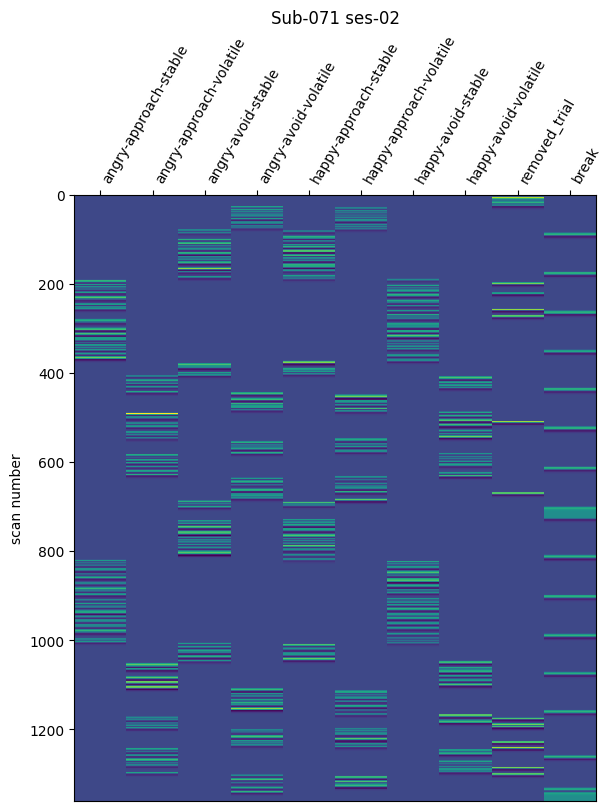

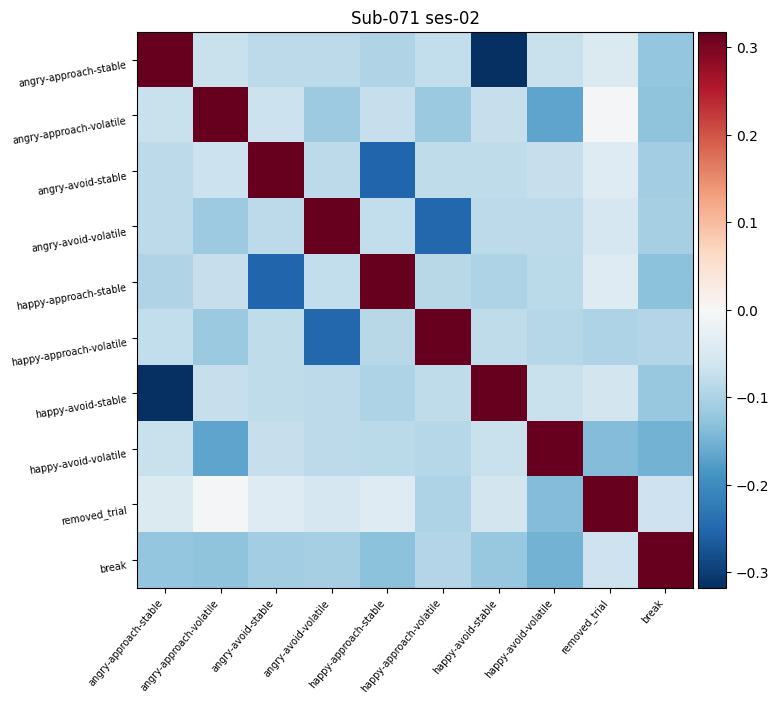

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
2.2777369581190303% of volumes have been removed.

fMRIprep has not yet been run for subject 71 and session 3
Creating event file for subject 71 and session 4
30
60
96
120
150
180
210
240
270
300
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.142716   0.917811
1                                        NaN     5.142716   0.917811
2                              removed_trial     5.142716   0.917811
3                                        NaN     8.613626   0.661296
4                                        NaN     8.613626   

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


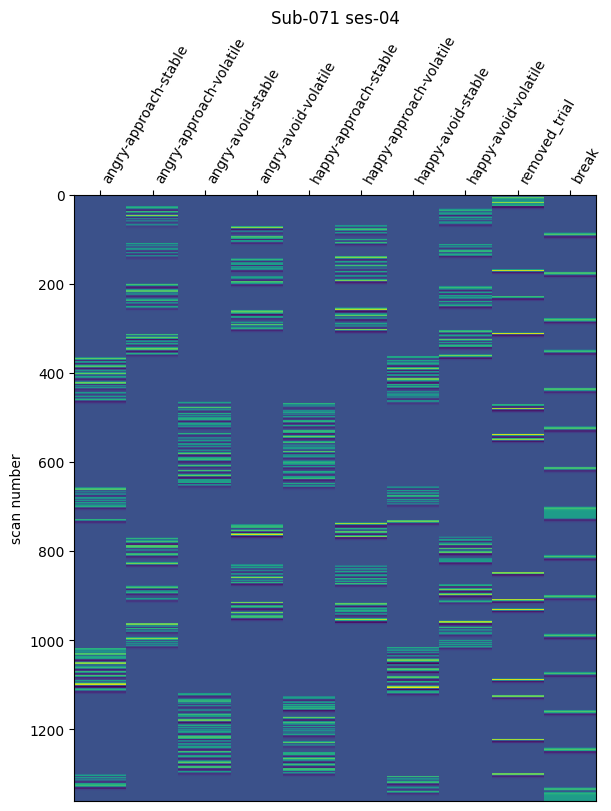

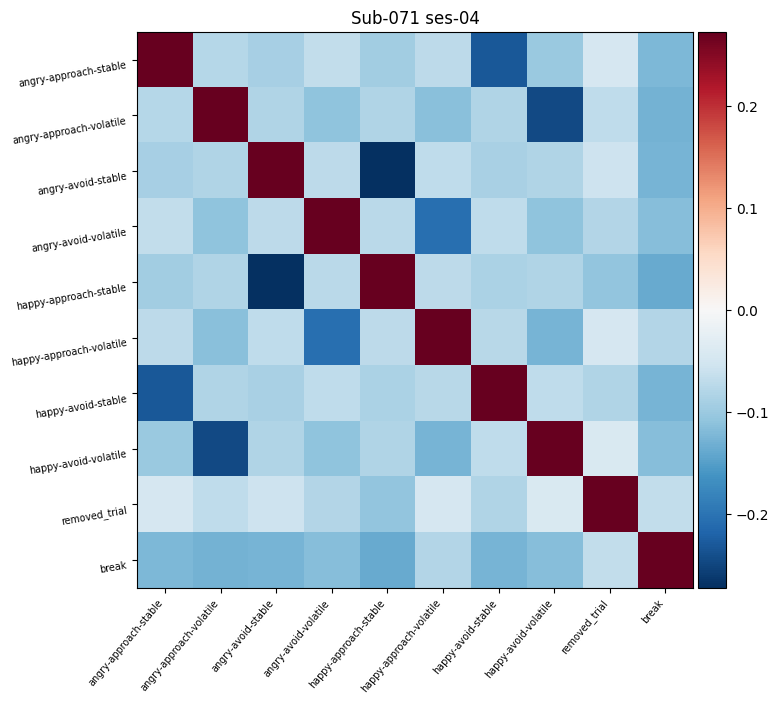

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.8082292432035268% of volumes have been removed.

Creating event file for subject 72 and session 2
30
60
90
120
150
180
210
240
270
306
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.063595   0.674274
1                                        NaN     5.063595   0.674274
2                              removed_trial     5.063595   0.674274
3                                        NaN     8.786915   0.709093
4                                        NaN     8.786915   0.709093
5                              removed_trial     8

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


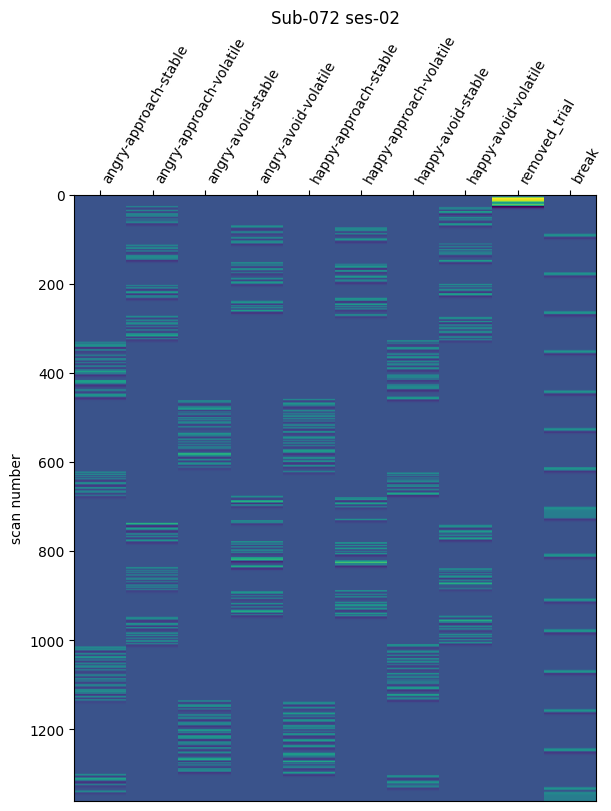

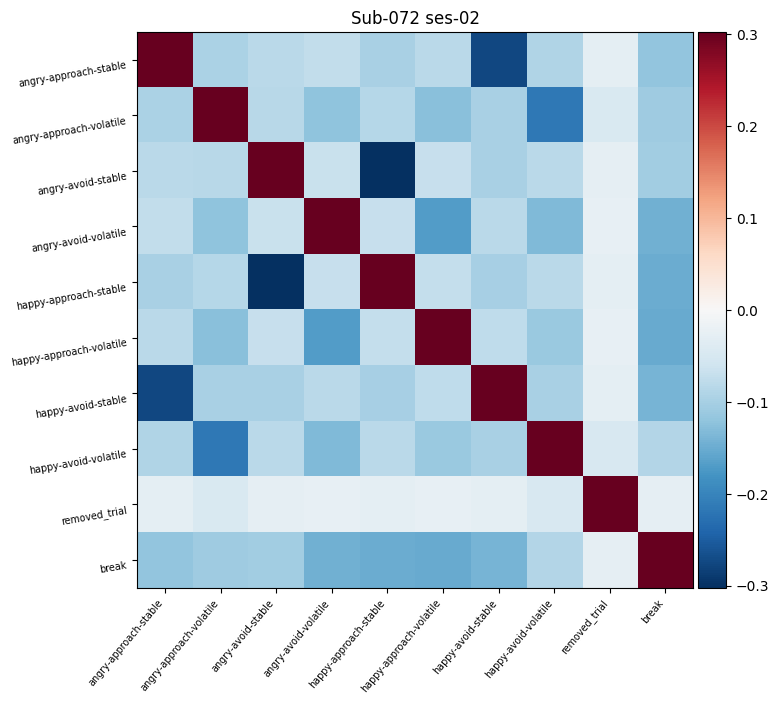

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 72 and session 3
30
60
90
120
150
180
210
242
270
300
330
366
390
426
450
451
                                  trial_type        onset   duration
0                                        NaN     5.070710   0.588123
1                                        NaN     5.070710   0.588123
2                              removed_trial     5.070710   0.588123
3                                        NaN     8.793599   0.630408
4                                        NaN     8.793599   0.630408
5                              removed_trial     8.793599   0.630

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


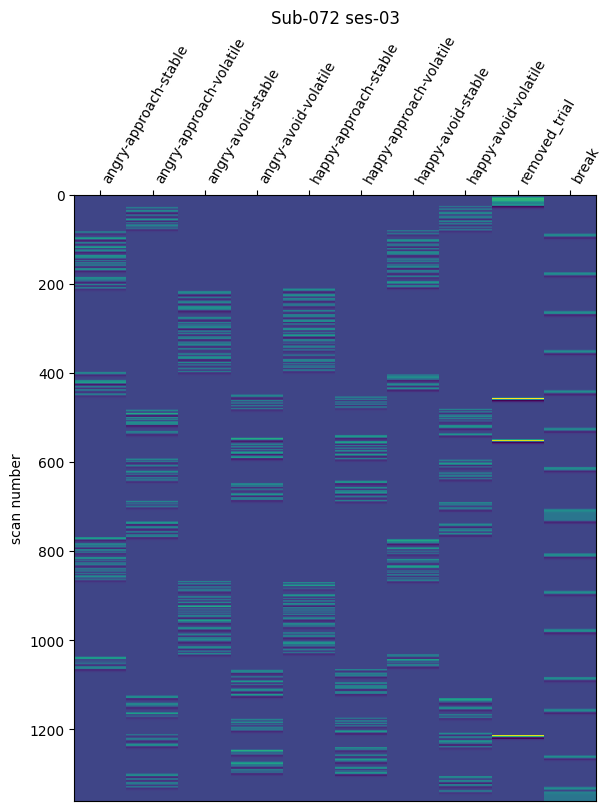

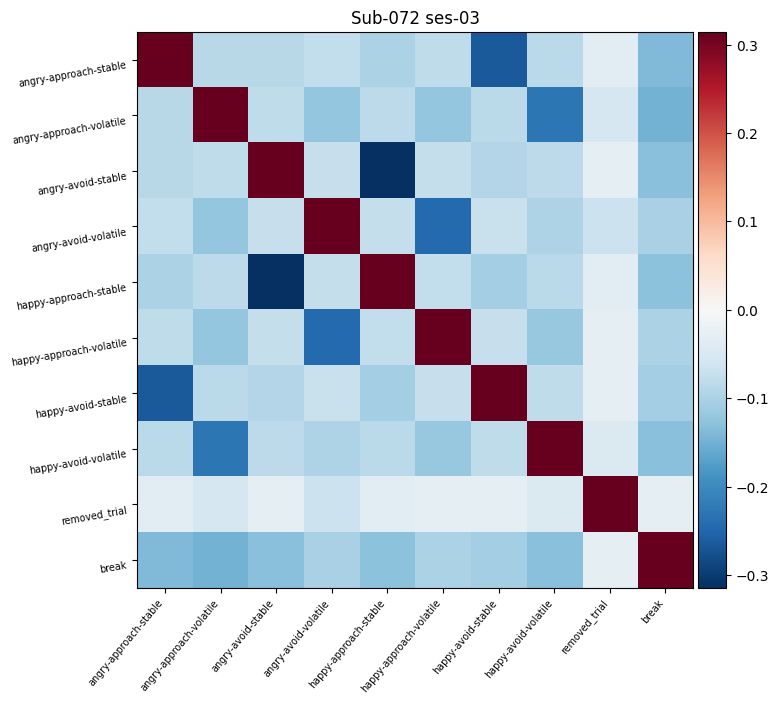

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.07347538574577515% of volumes have been removed.

Creating event file for subject 72 and session 4
30
66
90
120
154
180
212
246
270
306
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.078564   0.579721
1                                        NaN     5.078564   0.579721
2                              removed_trial     5.078564   0.579721
3                                        NaN     8.798250   0.818559
4                                        NaN     8.798250   0.818559
5                              removed_trial     

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


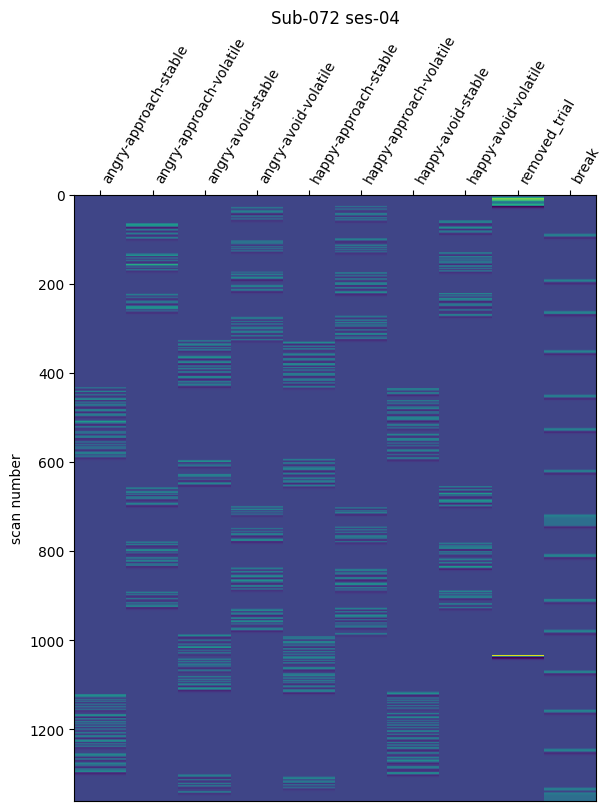

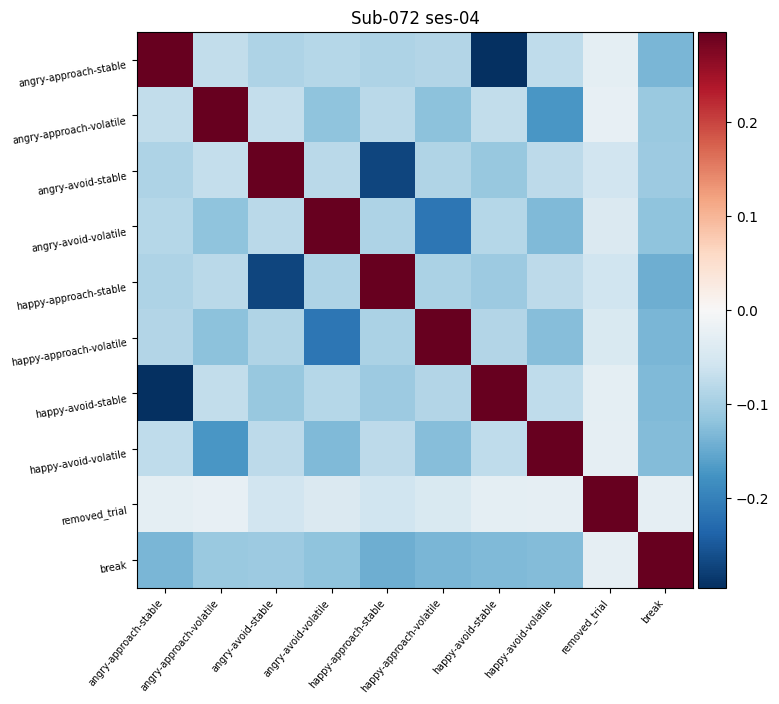

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 76 and session 2
30
66
90
120
150
180
210
242
270
300
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.065549   0.738391
1                                        NaN     5.065549   0.738391
2                              removed_trial     5.065549   0.738391
3                                        NaN     8.566924   0.763826
4                                        NaN     8.566924   0.763826
5                              removed_trial     8.566924   0.763

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


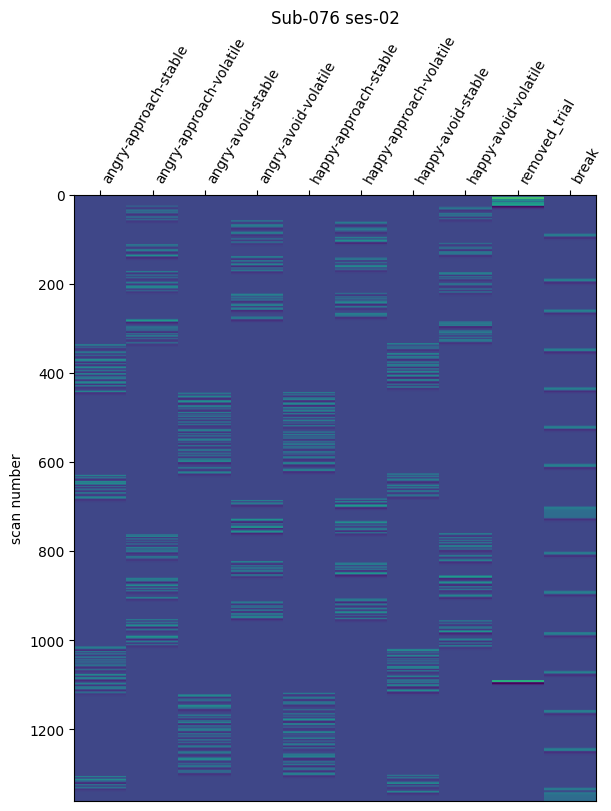

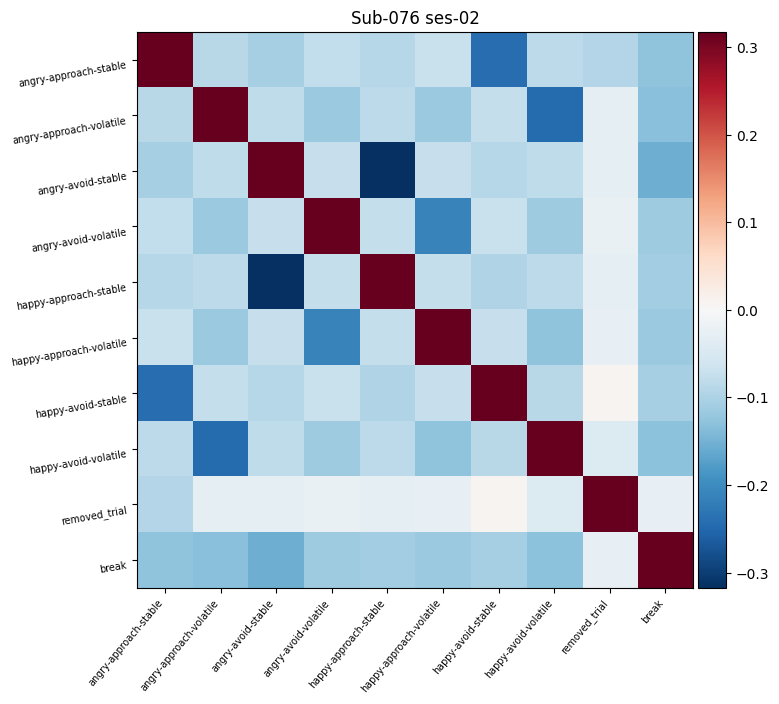

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 76 and session 3
34
66
90
120
150
180
210
246
270
300
330
360
392
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.069801   0.857634
1                                        NaN     5.069801   0.857634
2                              removed_trial     5.069801   0.857634
3                                        NaN     8.570070   0.455052
4                                        NaN     8.570070   0.455052
5                              removed_trial     8.570070   0.455

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


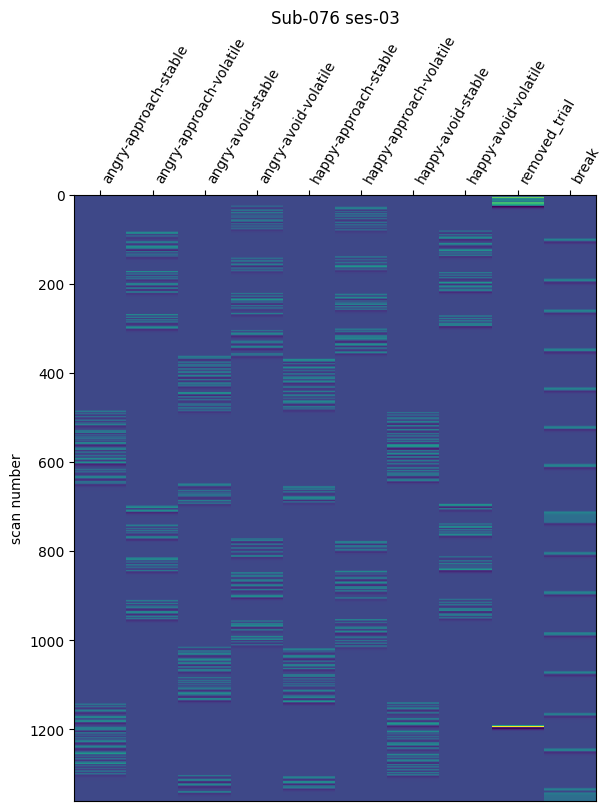

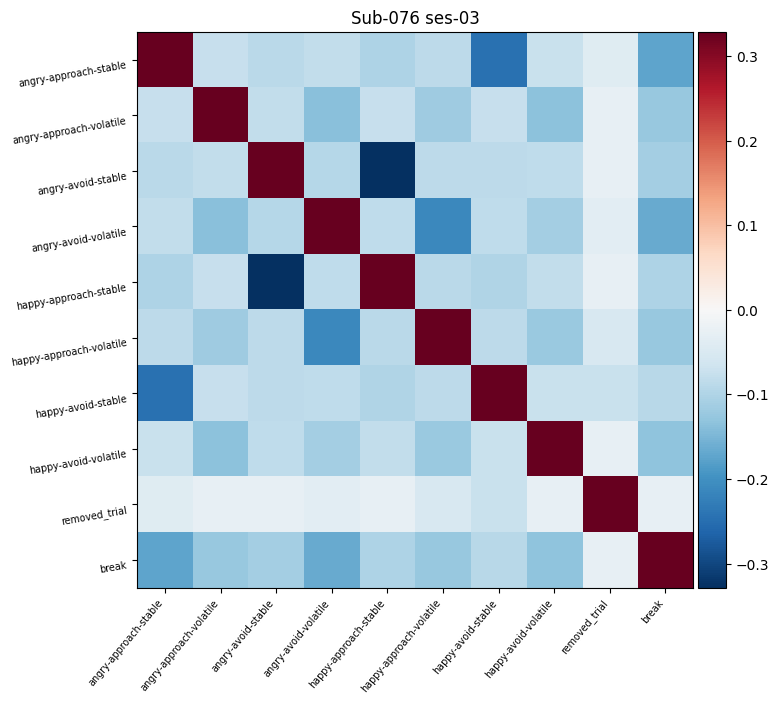

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 76 and session 4
30
60
90
120
156
180
214
240
270
300
330
362
396
426
450
451
                                  trial_type        onset   duration
0                                        NaN     5.281268   0.934487
1                                        NaN     5.281268   0.934487
2                              removed_trial     5.281268   0.934487
3                                        NaN     8.782125   0.599699
4                                        NaN     8.782125   0.599699
5                              removed_trial     8.782125   0.599

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


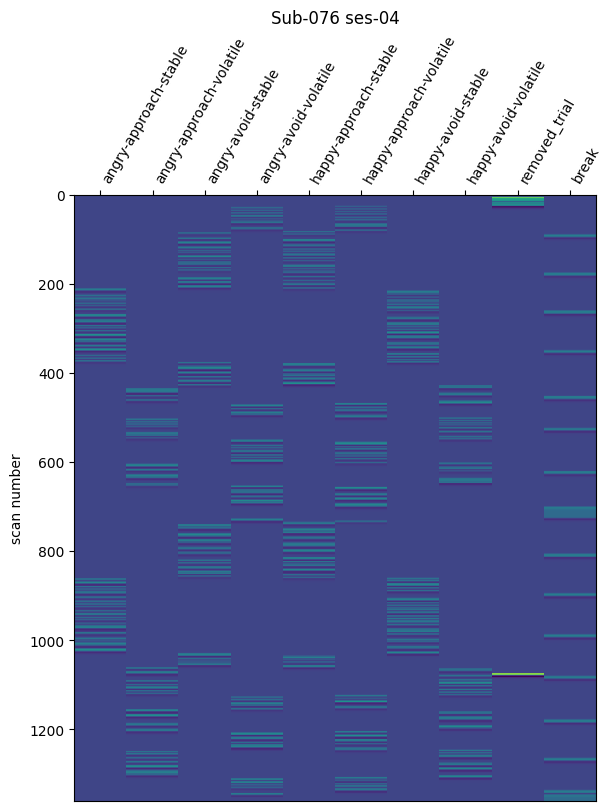

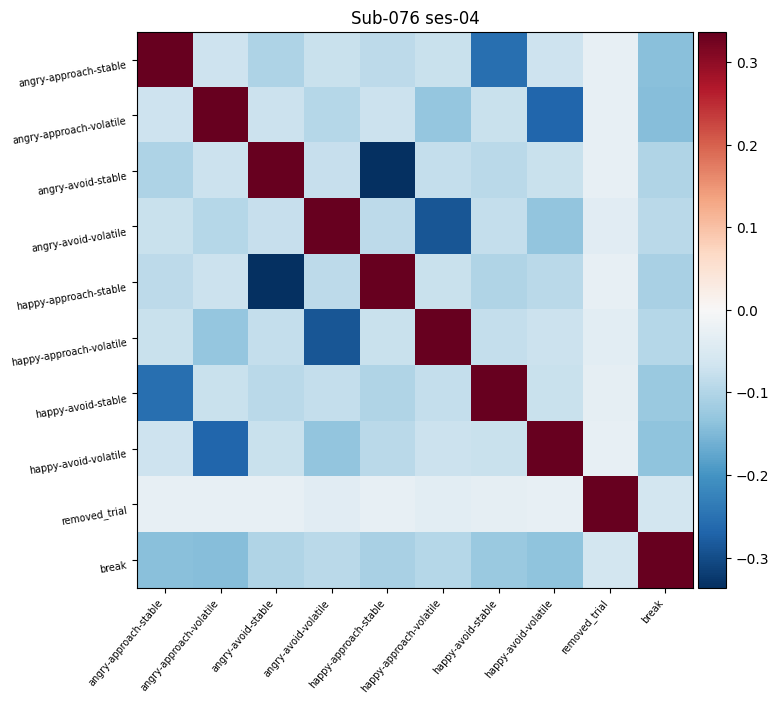

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 77 and session 2
30
60
90
120
150
180
210
240
270
300
330
362
396
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.141575   0.700642
1                                        NaN     5.141575   0.700642
2                              removed_trial     5.141575   0.700642
3                                        NaN     8.394715   0.853253
4                                        NaN     8.394715   0.853253
5                              removed_trial     8.394715   0.853

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


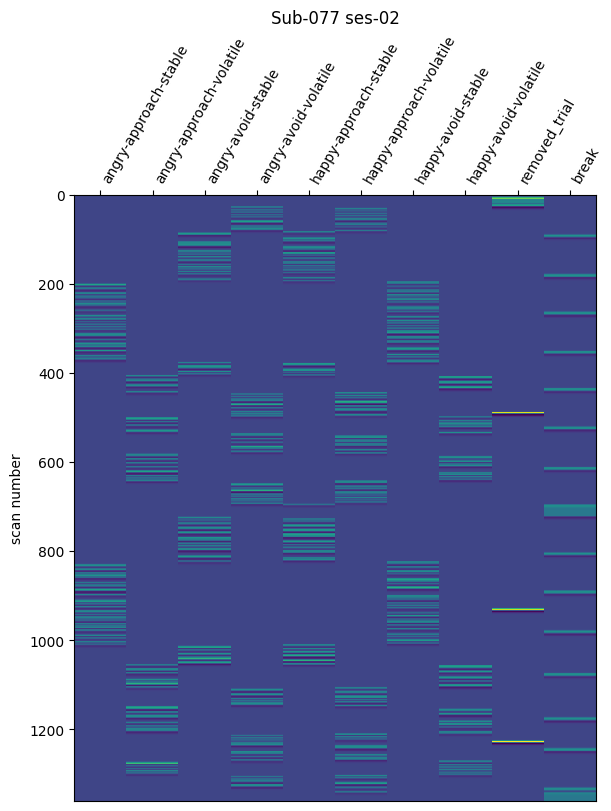

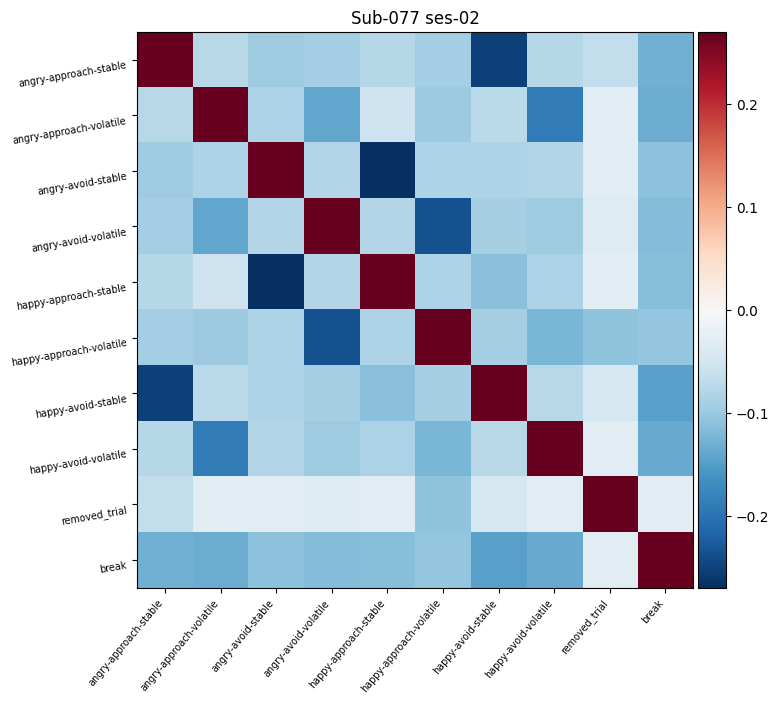

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 77 and session 3
30
66
90
120
150
180
210
240
270
300
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.319386   0.487275
1                                        NaN     5.319386   0.487275
2                              removed_trial     5.319386   0.487275
3                                        NaN     8.556624   0.514417
4                                        NaN     8.556624   0.514417
5                              removed_trial     8.556624   0.514

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


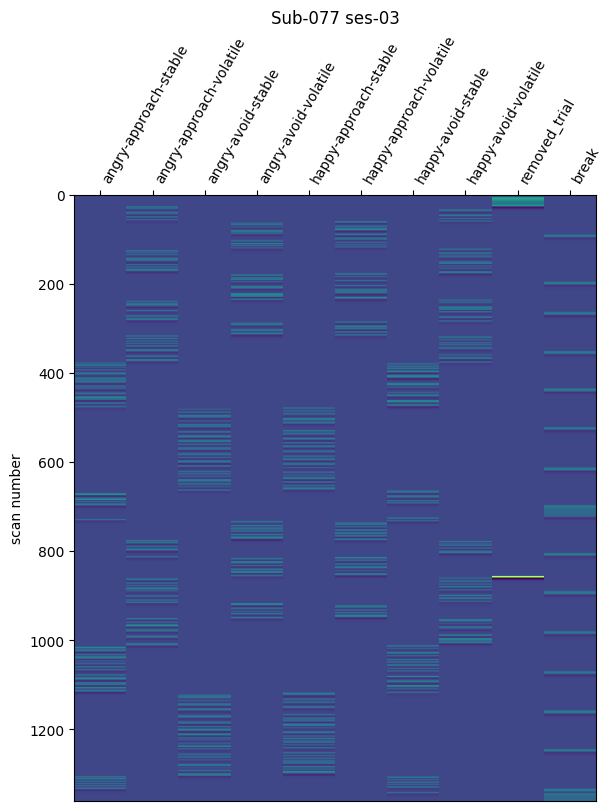

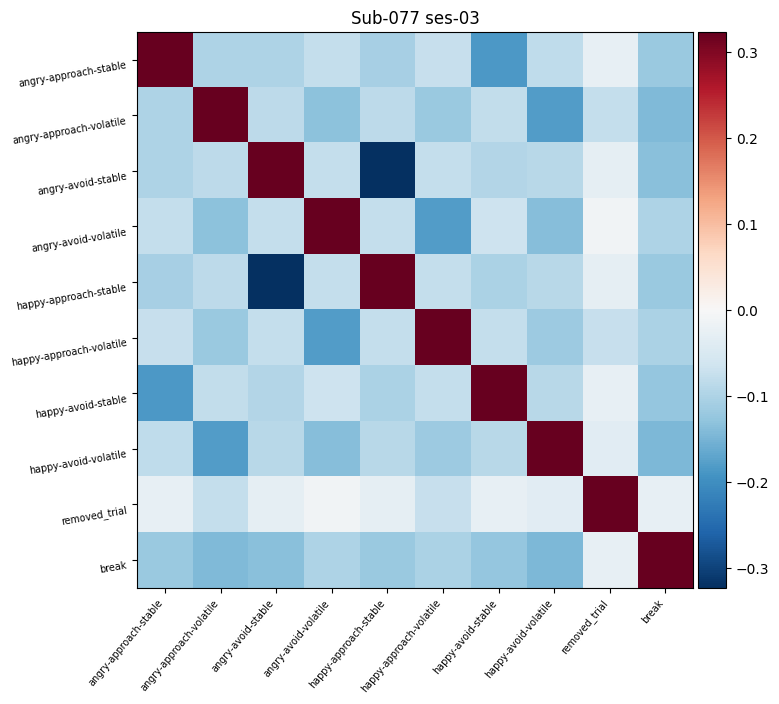

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 77 and session 4
30
66
90
120
150
180
210
246
270
300
330
360
392
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.015973   0.549819
1                                        NaN     5.015973   0.549819
2                              removed_trial     5.015973   0.549819
3                                        NaN     8.245325   0.537102
4                                        NaN     8.245325   0.537102
5                              removed_trial     8.245325   0.537

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


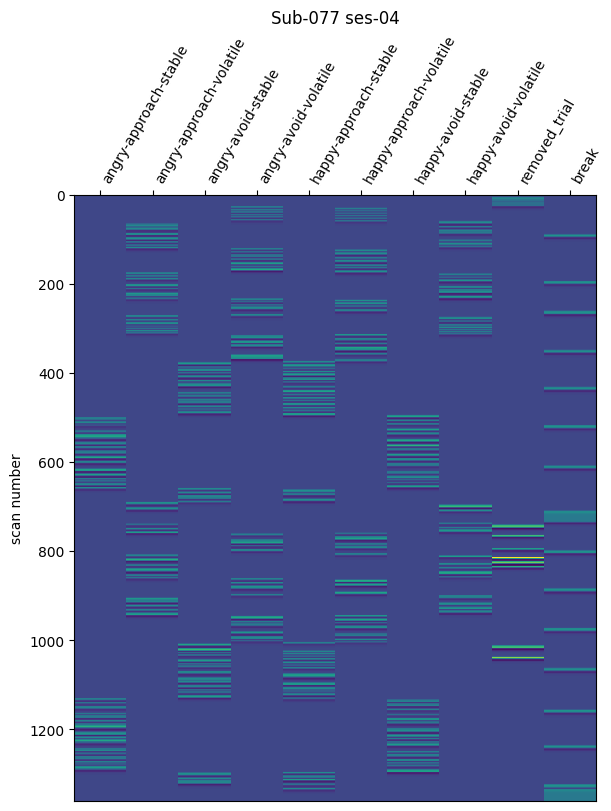

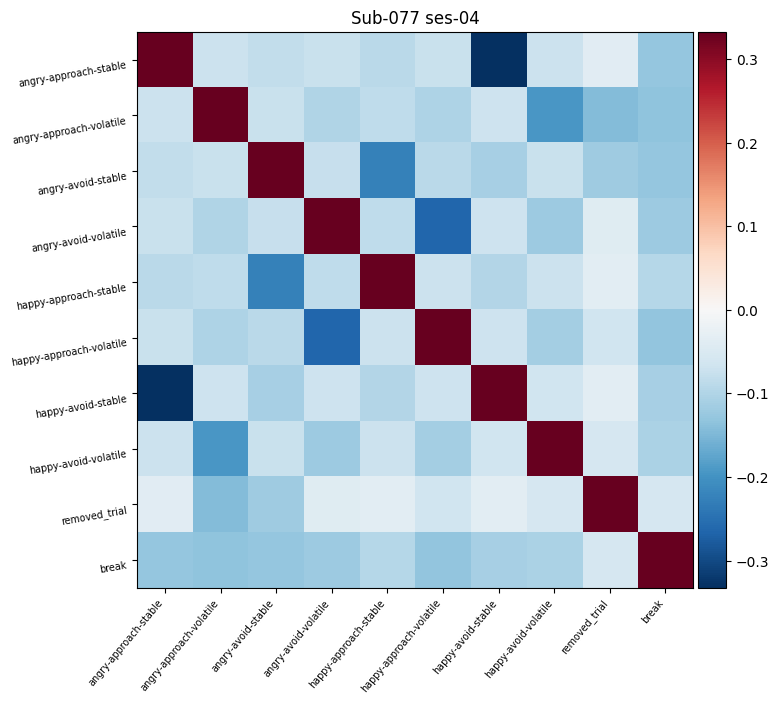

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 78 and session 2
30
60
90
120
152
180
210
240
270
300
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.069425   1.368555
1                                        NaN     5.069425   1.368555
2                              removed_trial     5.069425   1.368555
3                                        NaN     8.133902   0.784098
4                                        NaN     8.133902   0.784098
5                              removed_trial     8.133902   0.784

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


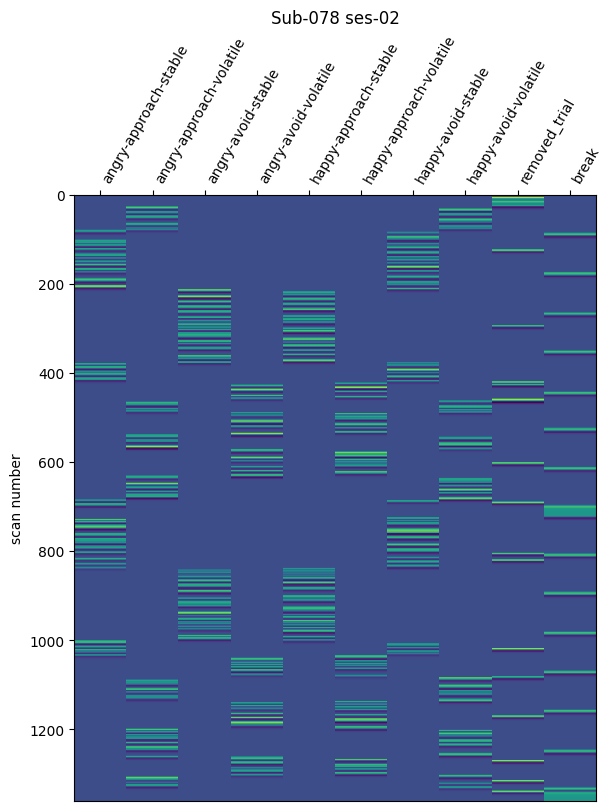

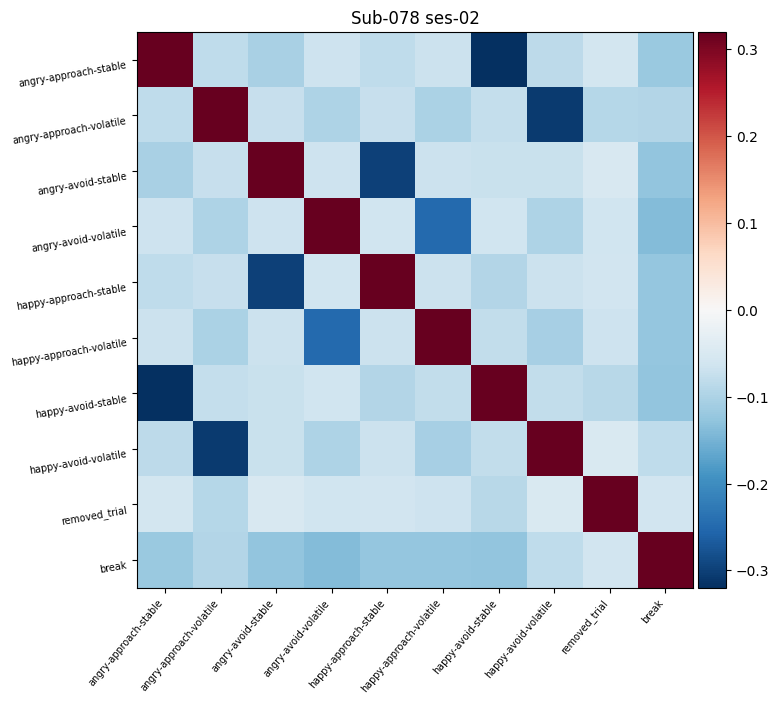

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 78 and session 3
30
60
90
120
150
180
210
240
270
300
330
362
390
426
450
451
                                  trial_type        onset   duration
0                                        NaN     5.147312   0.927506
1                                        NaN     5.147312   0.927506
2                              removed_trial     5.147312   0.927506
3                                        NaN     8.214520   0.793489
4                                        NaN     8.214520   0.793489
5                              removed_trial     8.214520   0.793

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


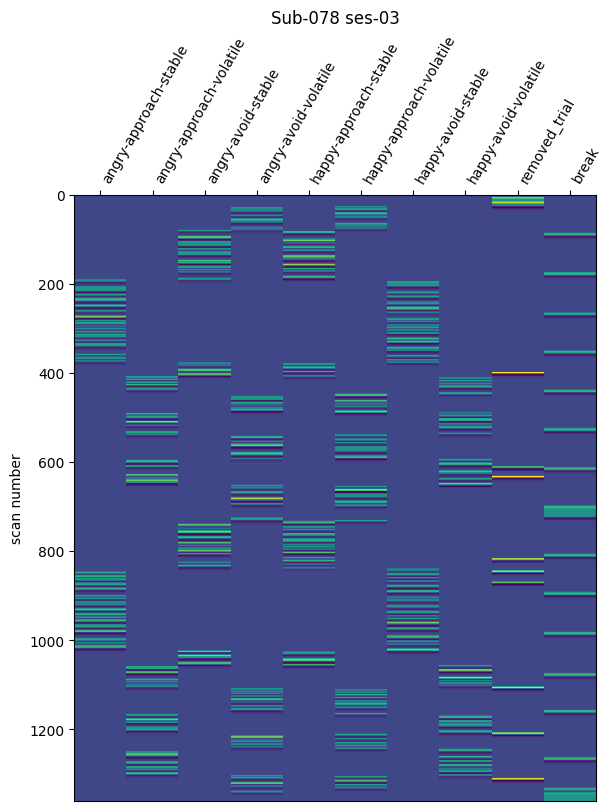

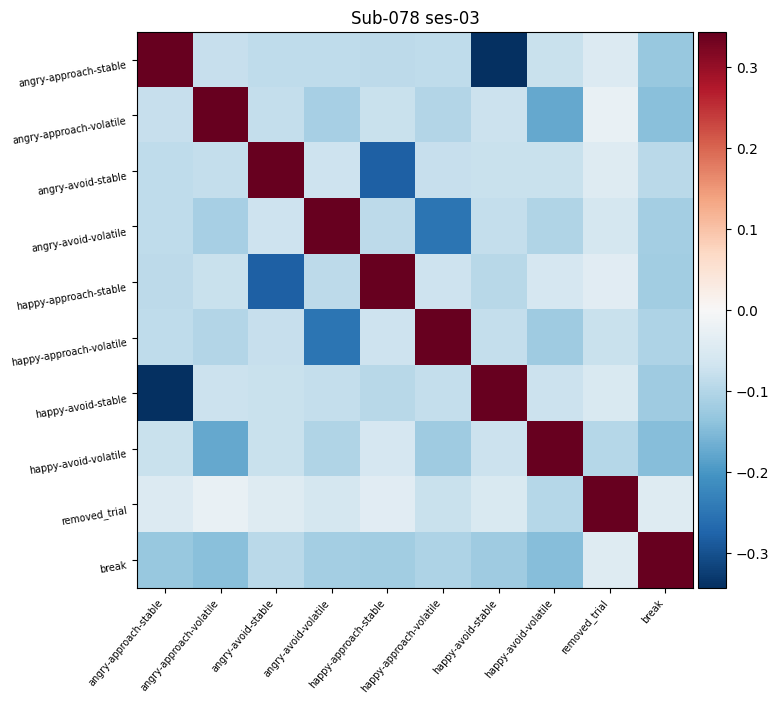

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 78 and session 4
36
66
90
120
150
180
210
240
270
300
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.068395   1.053240
1                                        NaN     5.068395   1.053240
2                              removed_trial     5.068395   1.053240
3                                        NaN     8.129250   0.781052
4                                        NaN     8.129250   0.781052
5                              removed_trial     8.129250   0.781

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


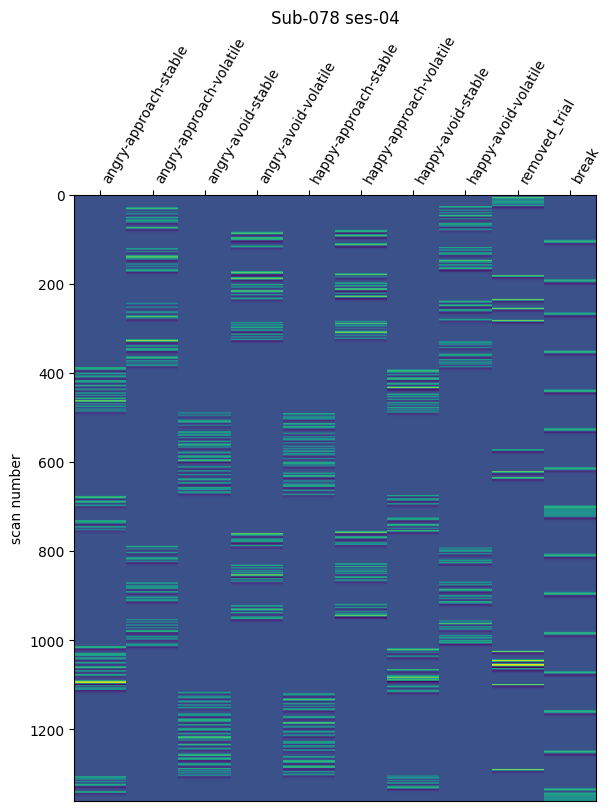

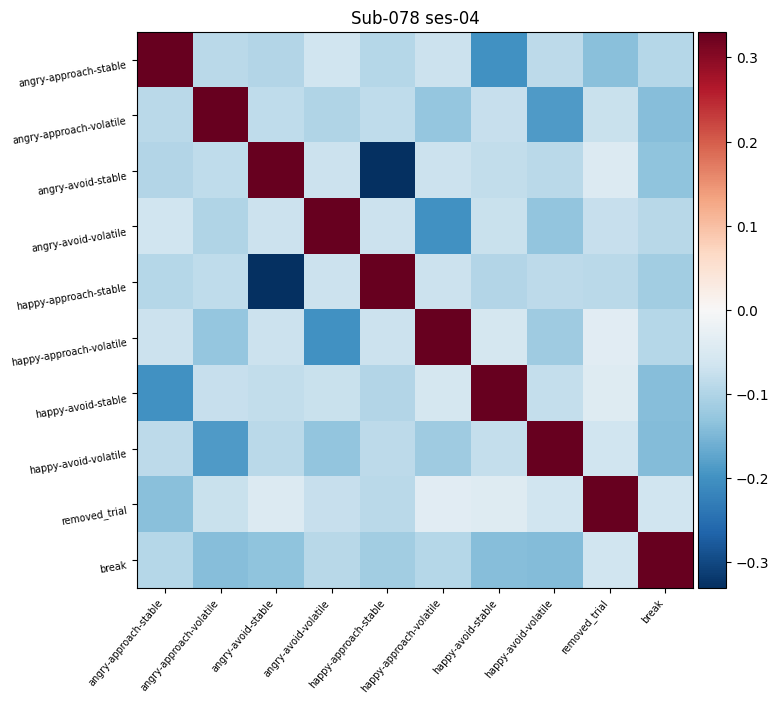

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 79 and session 2
30
60
90
120
150
180
210
240
270
300
330
360
396
426
450
451
                                  trial_type        onset   duration
0                                        NaN     5.313970   0.762135
1                                        NaN     5.313970   0.762135
2                              removed_trial     5.313970   0.762135
3                                        NaN     9.989793   0.657757
4                                        NaN     9.989793   0.657757
5                              removed_trial     9.989793   0.657

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


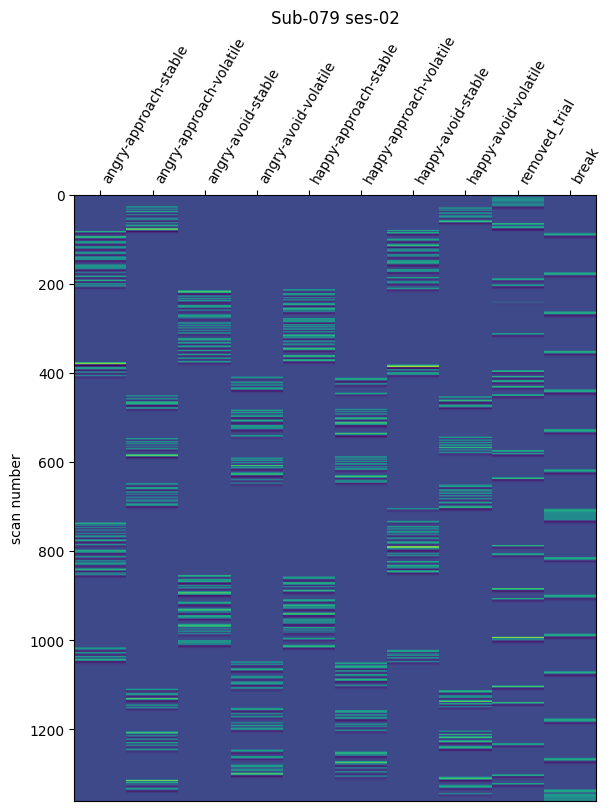

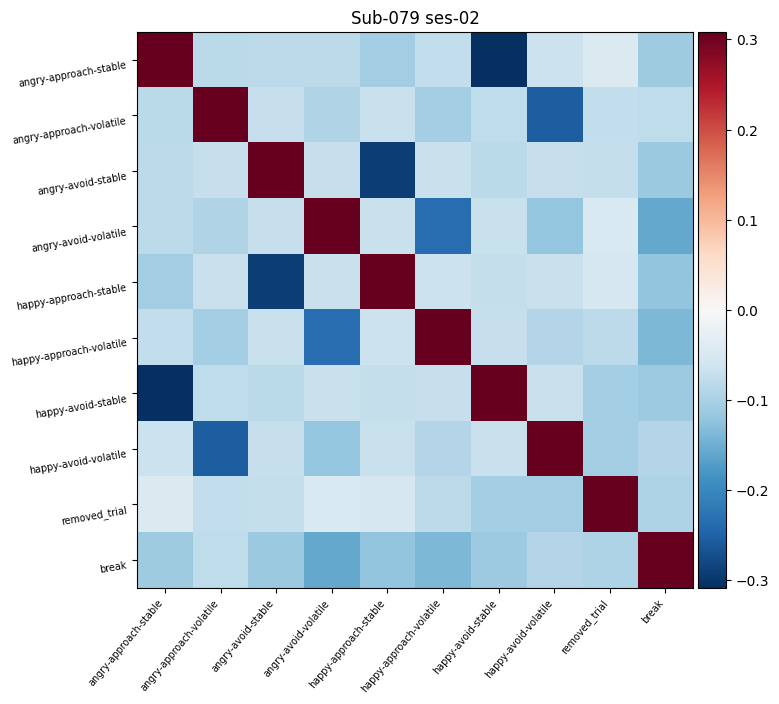

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 79 and session 3
30
62
90
120
150
180
210
246
274
300
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.060894   0.641099
1                                        NaN     5.060894   0.641099
2                              removed_trial     5.060894   0.641099
3                                        NaN     9.736589   0.658829
4                                        NaN     9.736589   0.658829
5                              removed_trial     9.736589   0.658

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


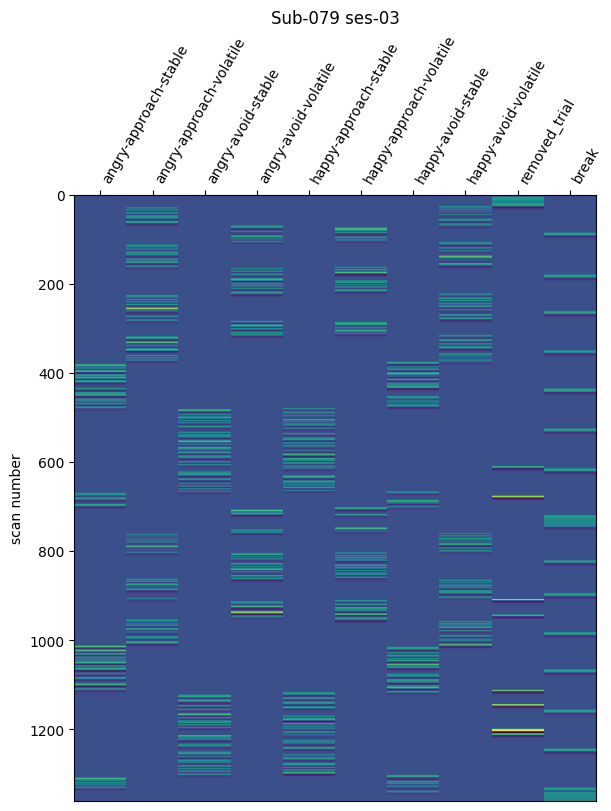

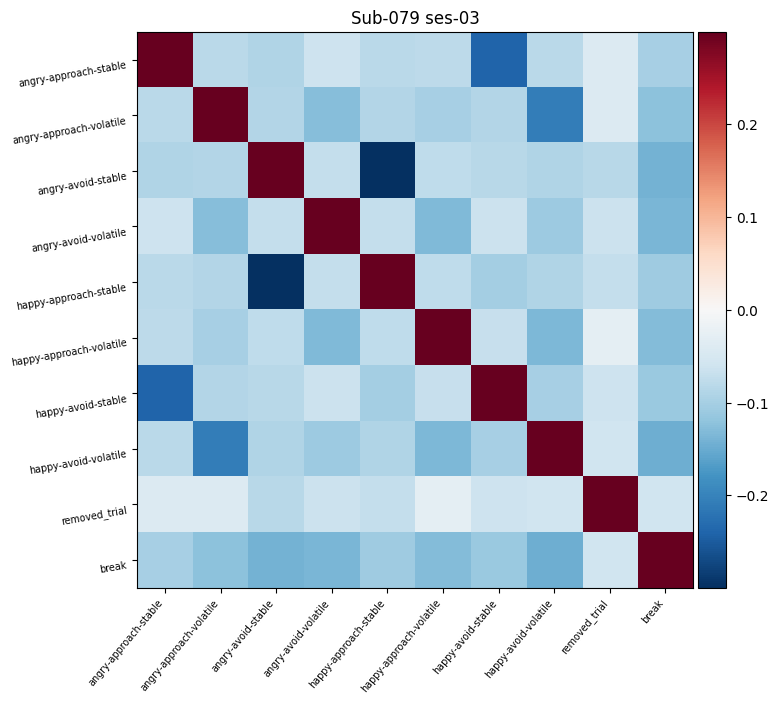

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 79 and session 4
36
60
90
120
150
180
210
240
270
300
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.071577   0.566657
1                                        NaN     5.071577   0.566657
2                              removed_trial     5.071577   0.566657
3                                        NaN     9.750866   0.880123
4                                        NaN     9.750866   0.880123
5                              removed_trial     9.750866   0.880

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


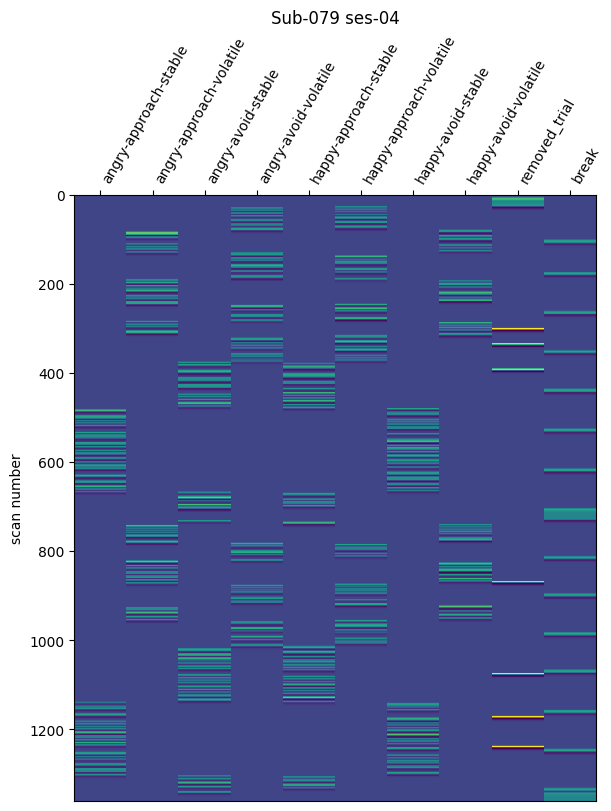

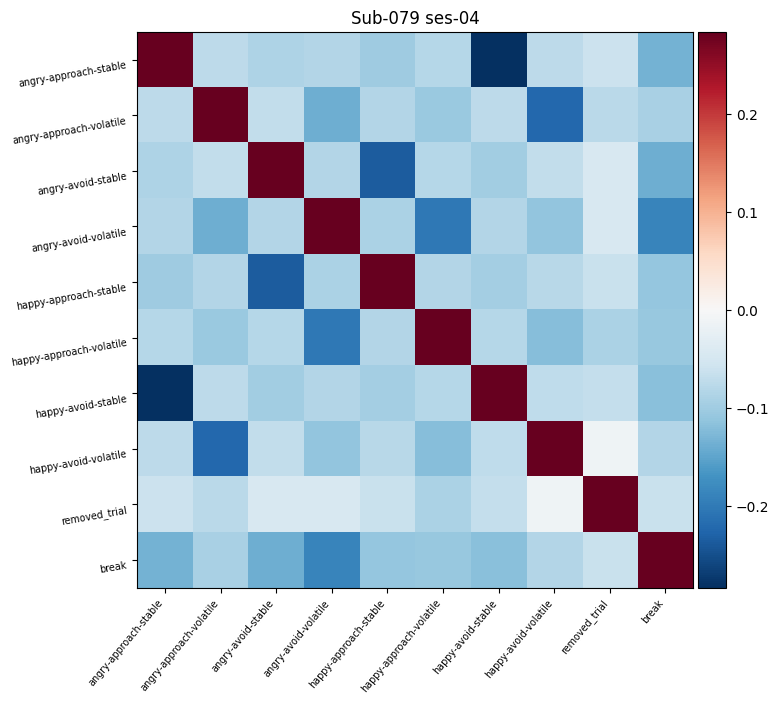

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 81 and session 2
30
60
90
120
150
182
210
240
270
300
330
366
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.064547   0.849487
1                                        NaN     5.064547   0.849487
2                              removed_trial     5.064547   0.849487
3                                        NaN     8.404203   0.640668
4                                        NaN     8.404203   0.640668
5                              removed_trial     8.404203   0.640

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


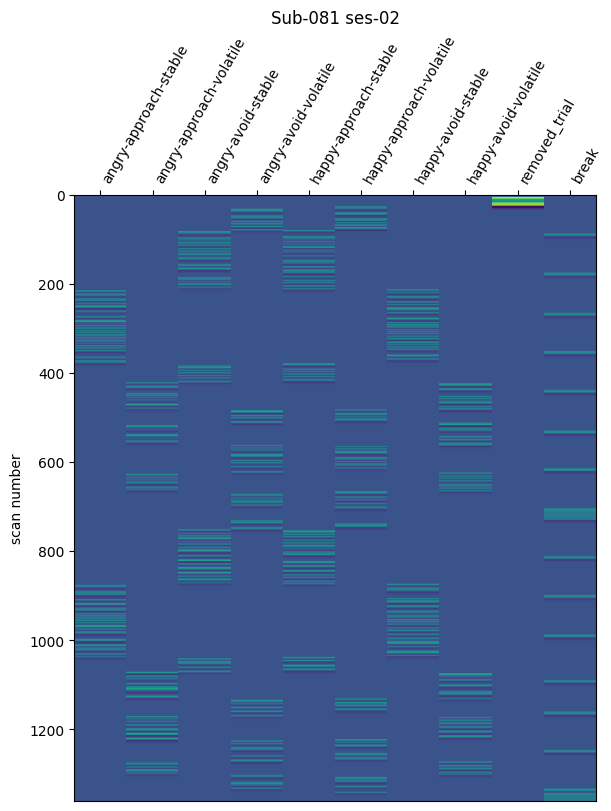

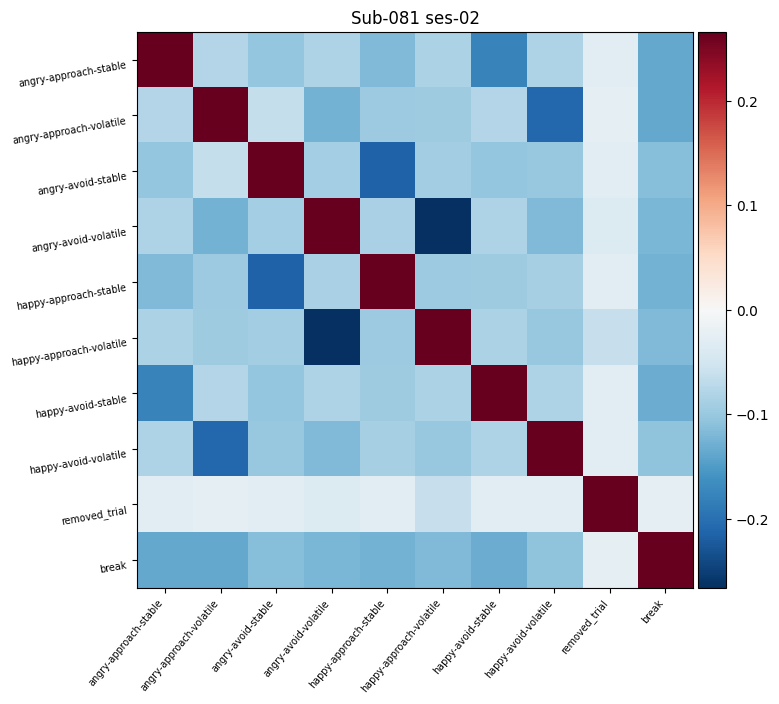

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 81 and session 3
30
60
90
120
150
180
214
240
270
300
330
362
390
426
450
451
                                  trial_type        onset   duration
0                                        NaN     5.276935   0.647348
1                                        NaN     5.276935   0.647348
2                              removed_trial     5.276935   0.647348
3                                        NaN     8.663435   0.636193
4                                        NaN     8.663435   0.636193
5                              removed_trial     8.663435   0.636

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


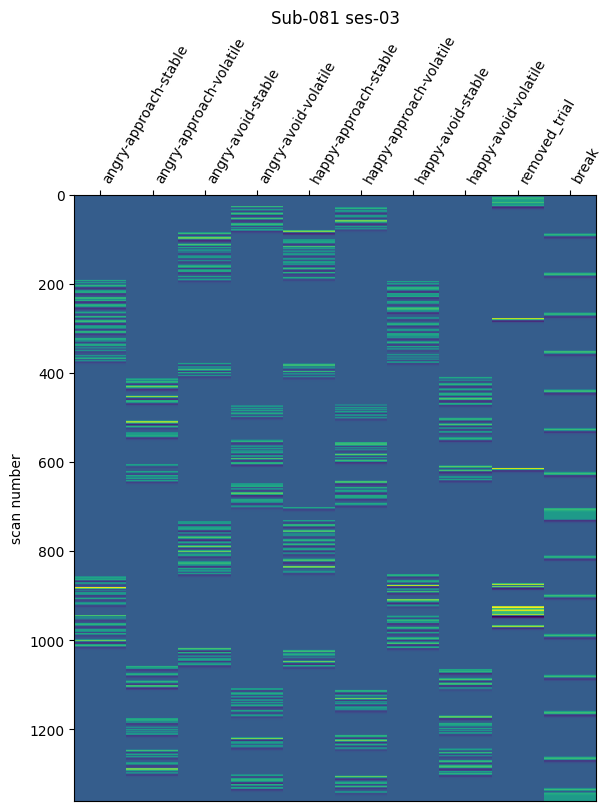

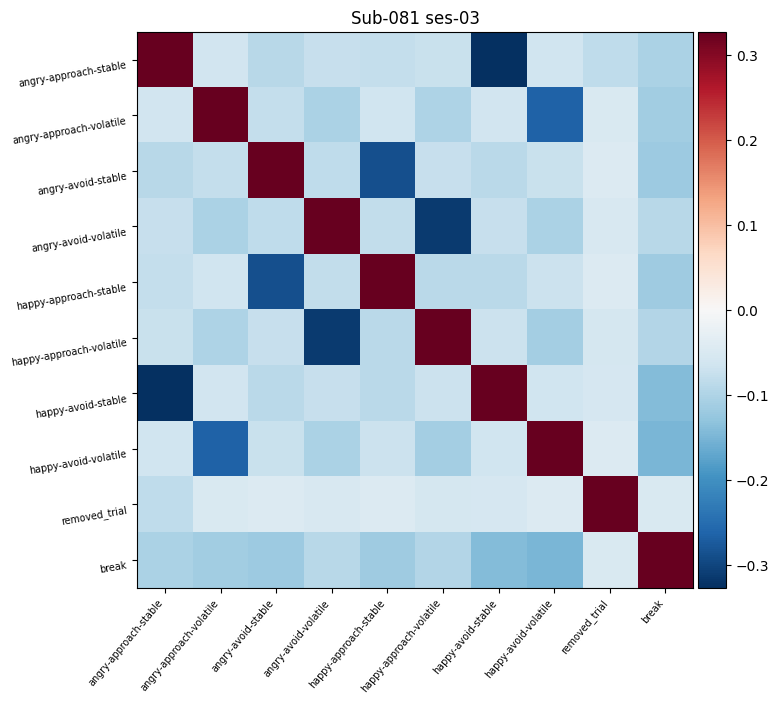

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 81 and session 4
36
66
90
120
150
182
210
240
270
300
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.012632   0.639371
1                                        NaN     5.012632   0.639371
2                              removed_trial     5.012632   0.639371
3                                        NaN     8.331735   0.769302
4                                        NaN     8.331735   0.769302
5                              removed_trial     8.331735   0.769

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


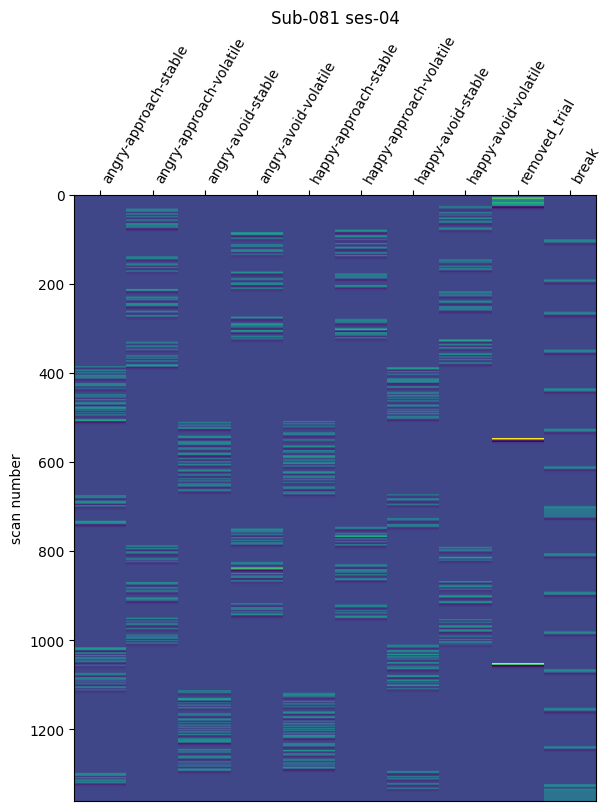

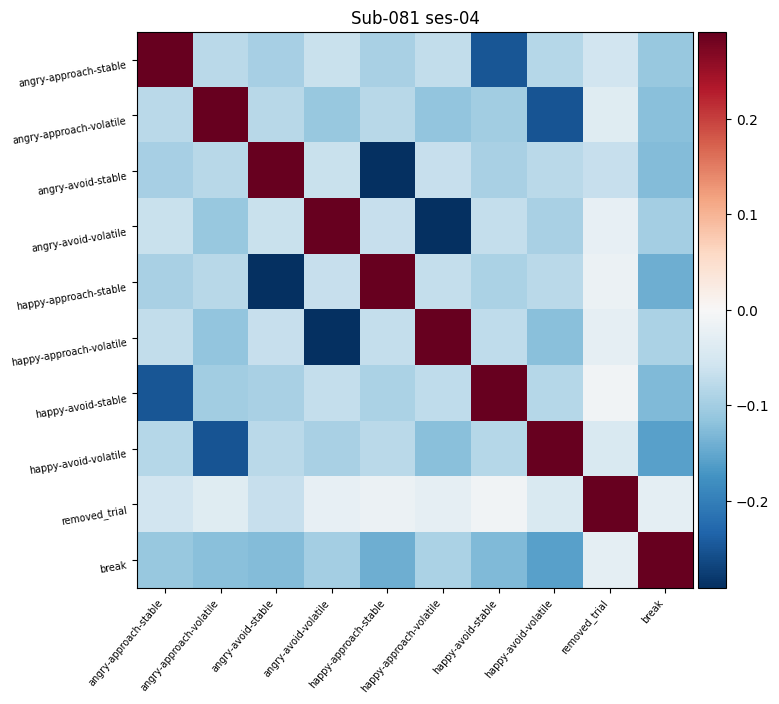

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 82 and session 2
30
60
90
126
156
180
210
240
270
300
330
360
394
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.322888   0.975030
1                                        NaN     5.322888   0.975030
2                              removed_trial     5.322888   0.975030
3                                        NaN     9.586620   0.752460
4                                        NaN     9.586620   0.752460
5                              removed_trial     9.586620   0.752

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


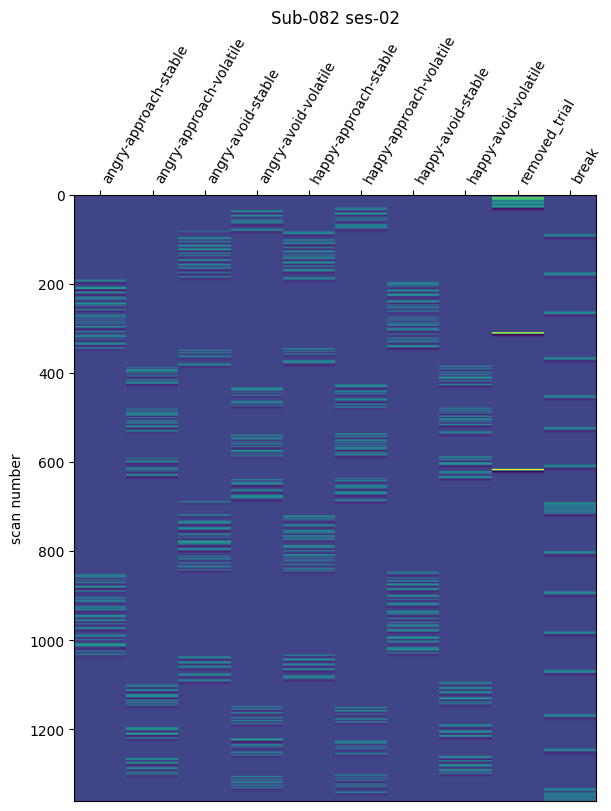

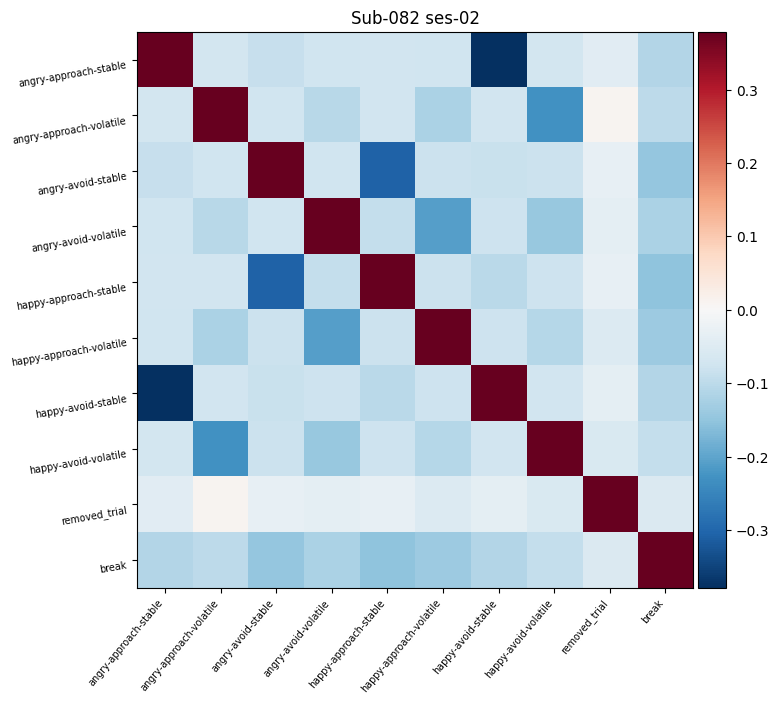

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 82 and session 3
30
60
90
120
150
180
210
240
270
300
334
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.287213   1.149047
1                                        NaN     5.287213   1.149047
2                              removed_trial     5.287213   1.149047
3                                        NaN     9.555152   0.781427
4                                        NaN     9.555152   0.781427
5                              removed_trial     9.555152   0.781

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


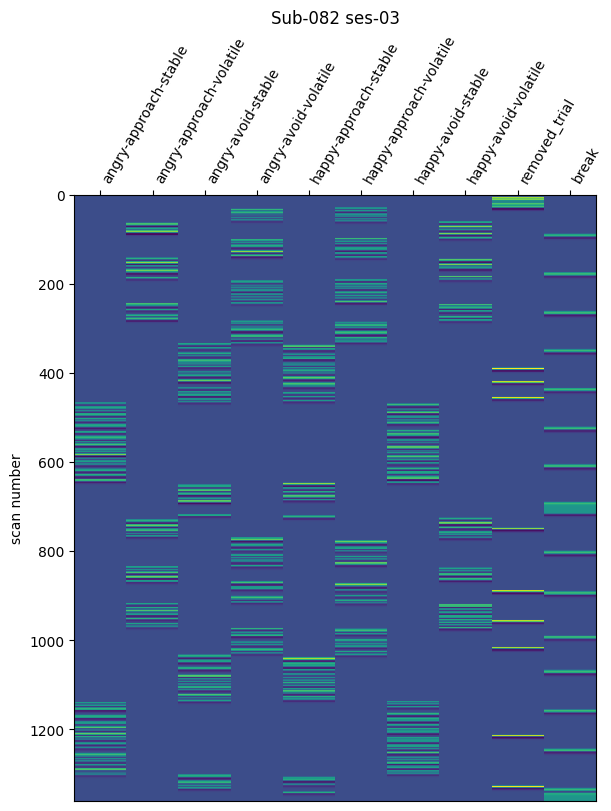

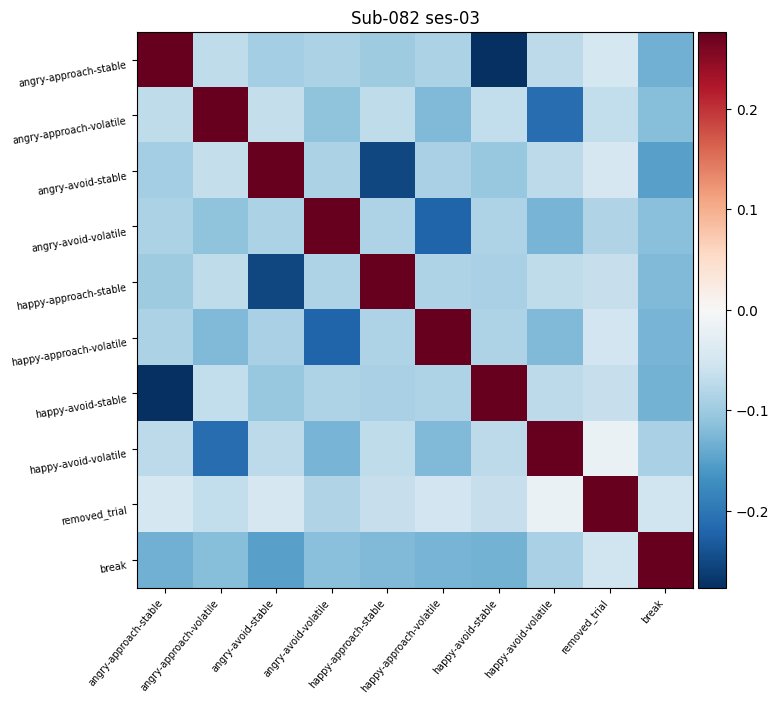

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 82 and session 4
30
60
90
120
150
180
210
242
270
300
330
366
390
422
450
451
                                  trial_type        onset   duration
0                                        NaN     5.012468   0.889548
1                                        NaN     5.012468   0.889548
2                              removed_trial     5.012468   0.889548
3                                        NaN     9.253243   0.997005
4                                        NaN     9.253243   0.997005
5                              removed_trial     9.253243   0.997

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


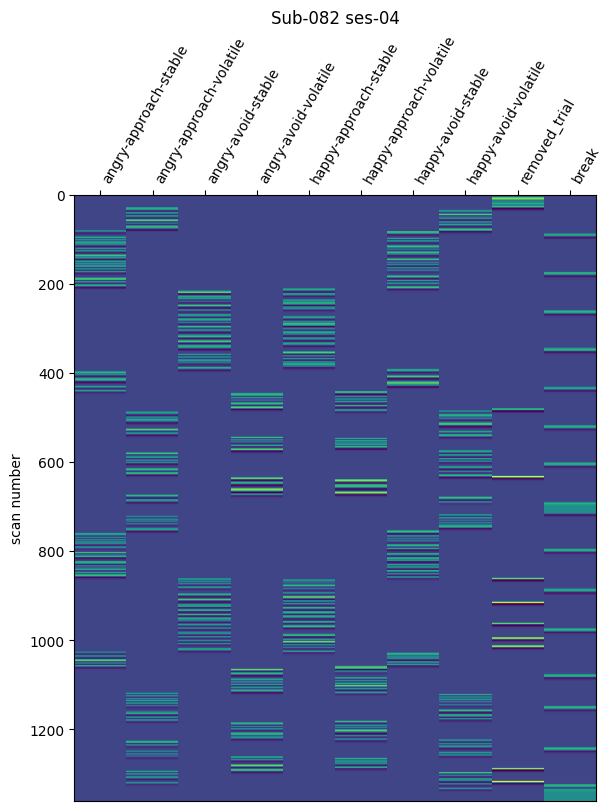

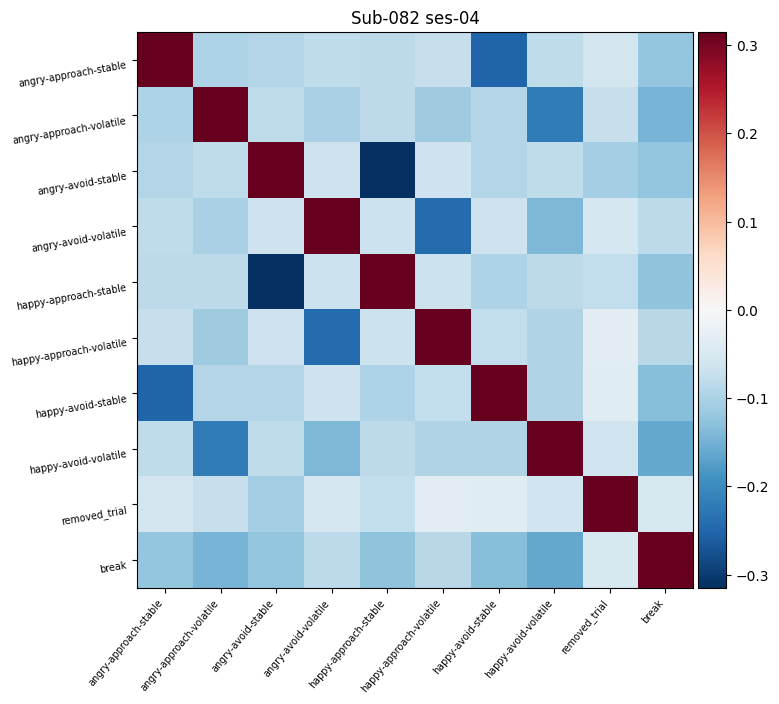

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 83 and session 2
30
60
90
120
150
182
210
246
270
302
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.151039   1.364222
1                                        NaN     5.151039   1.364222
2                              removed_trial     5.151039   1.364222
3                                        NaN     9.279675   0.690518
4                                        NaN     9.279675   0.690518
5                              removed_trial     9.279675   0.690

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


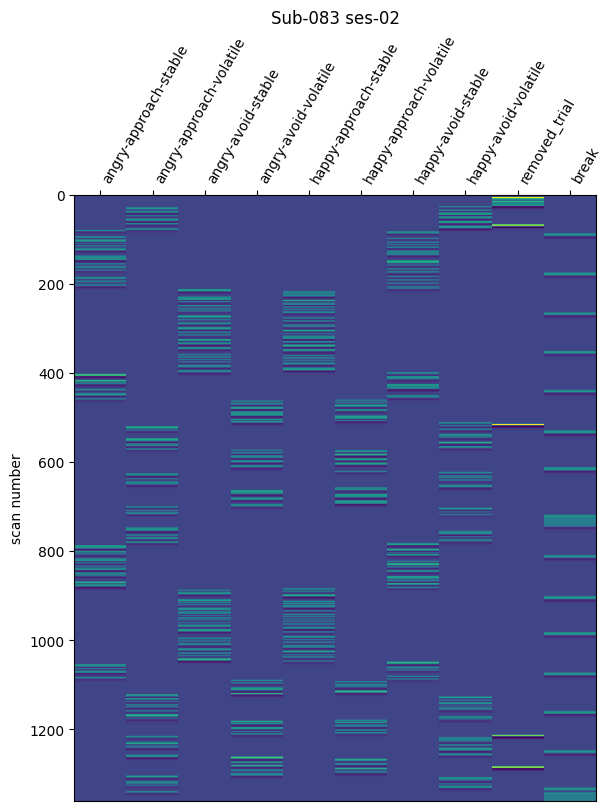

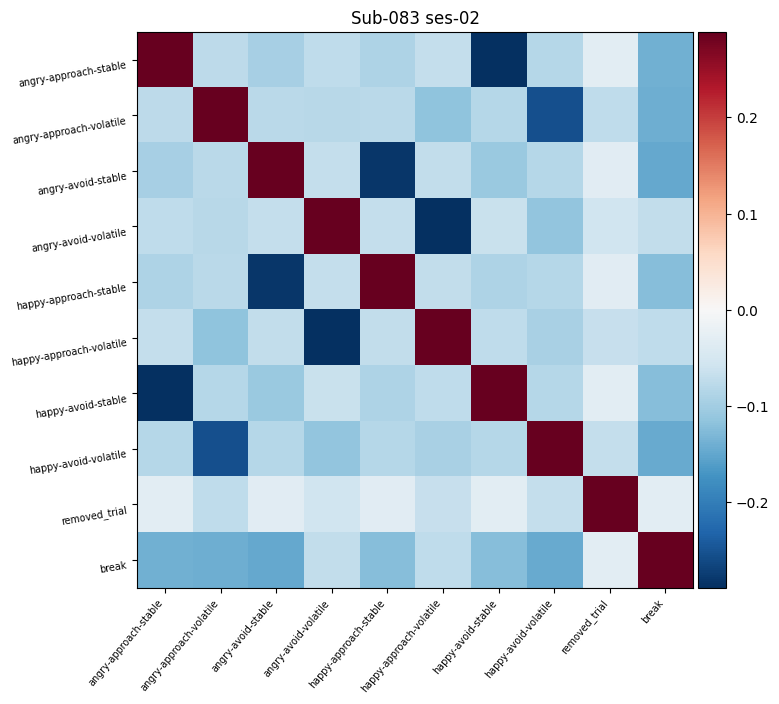

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 83 and session 3
36
66
92
120
150
180
210
240
272
300
334
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     6.091525   0.664632
1                                        NaN     6.091525   0.664632
2                              removed_trial     6.091525   0.664632
3                                        NaN    10.223266   0.692975
4                                        NaN    10.223266   0.692975
5                              removed_trial    10.223266   0.692

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


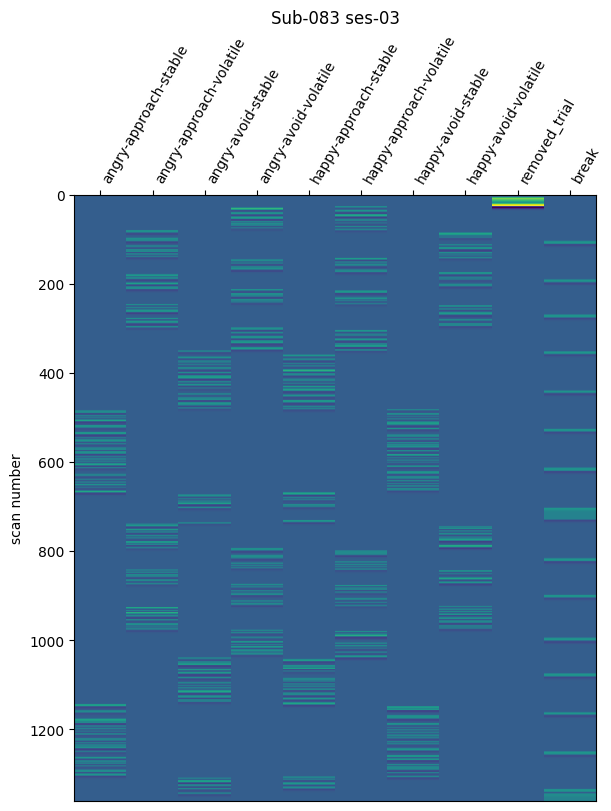

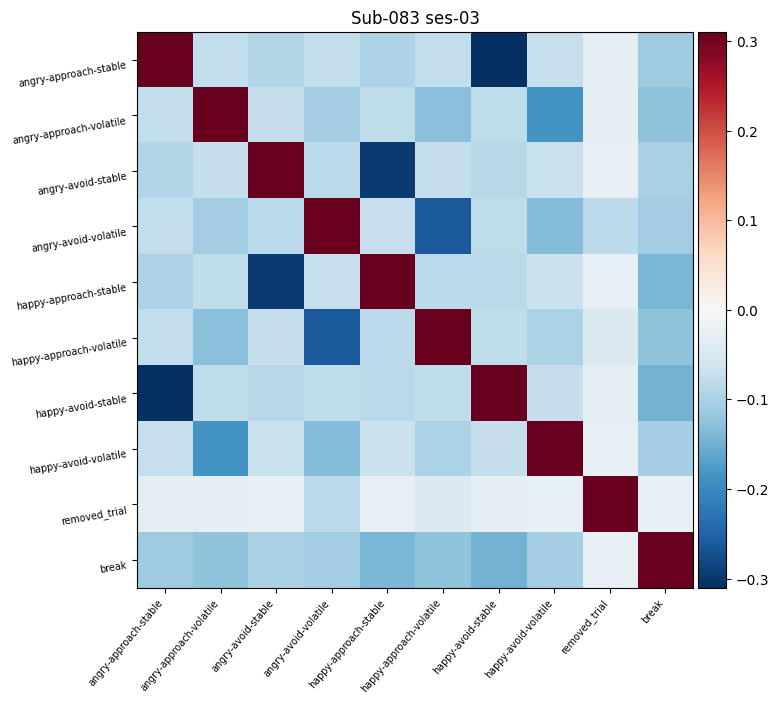

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 83 and session 4
30
60
90
120
152
186
210
240
270
300
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.014170   0.700092
1                                        NaN     5.014170   0.700092
2                              removed_trial     5.014170   0.700092
3                                        NaN     9.123934   0.763330
4                                        NaN     9.123934   0.763330
5                              removed_trial     9.123934   0.763

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


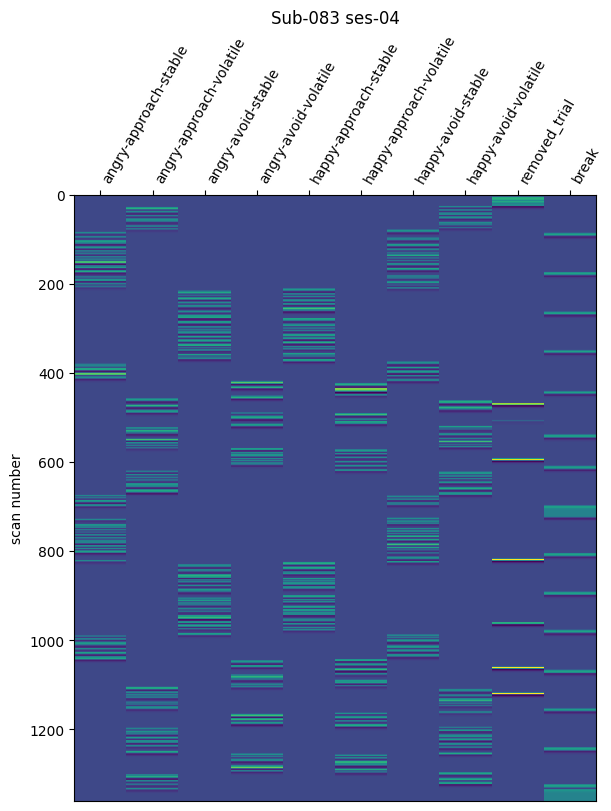

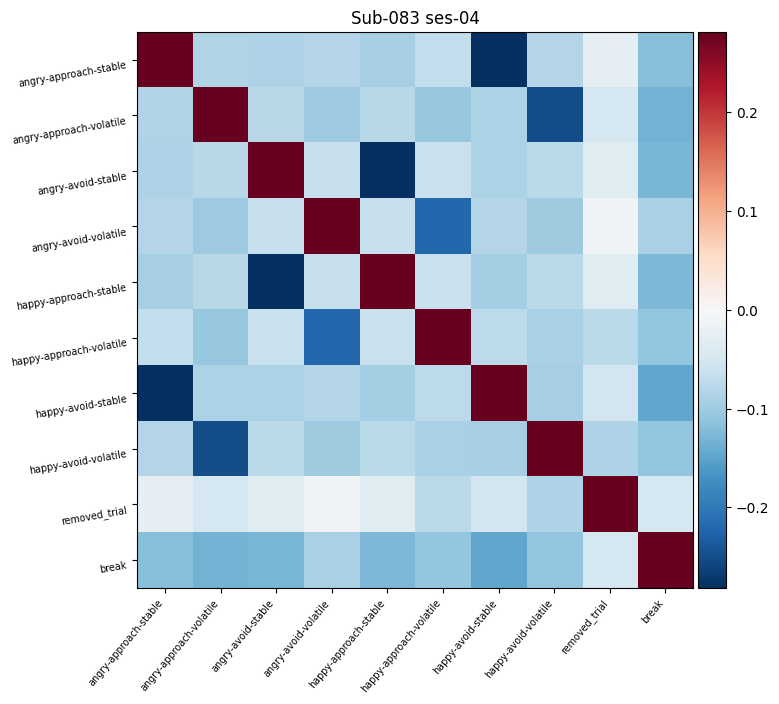

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 85 and session 2
30
60
90
126
150
180
210
240
270
300
330
360
390
426
450
451
                                  trial_type        onset   duration
0                                        NaN     5.072086   0.819514
1                                        NaN     5.072086   0.819514
2                              removed_trial     5.072086   0.819514
3                                        NaN     9.381859   0.585896
4                                        NaN     9.381859   0.585896
5                              removed_trial     9.381859   0.585

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


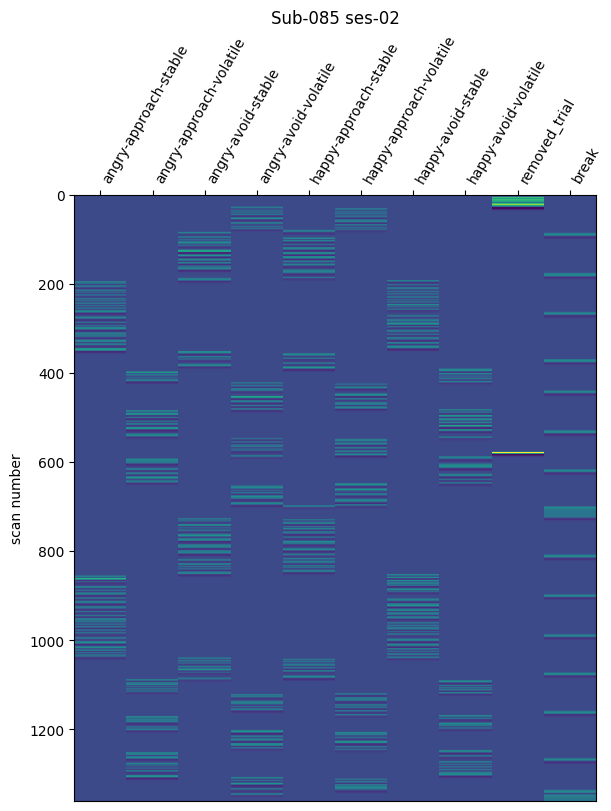

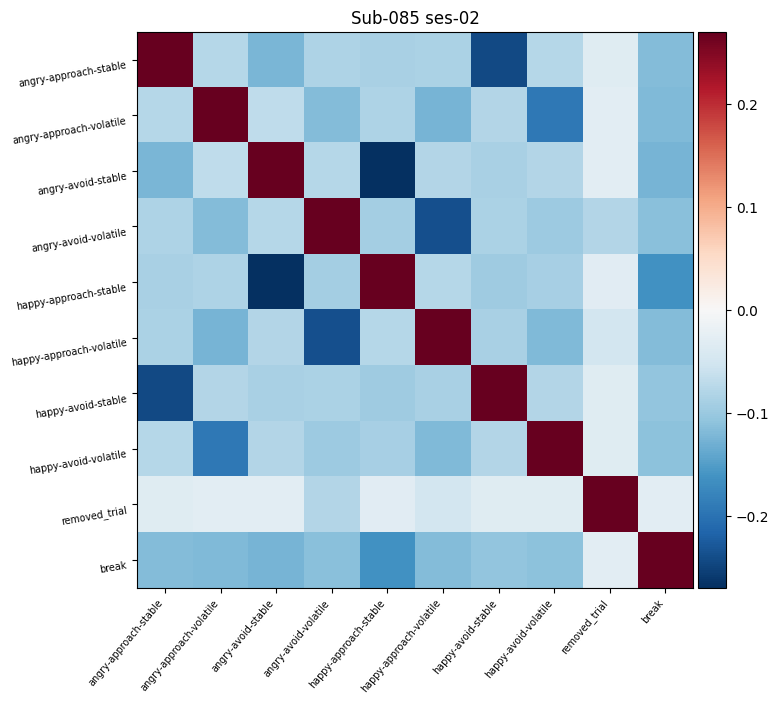

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

Creating event file for subject 85 and session 3
30
62
94
120
150
180
210
240
272
300
330
360
390
420
450
451
                                  trial_type        onset   duration
0                                        NaN     5.011174   0.812970
1                                        NaN     5.011174   0.812970
2                              removed_trial     5.011174   0.812970
3                                        NaN     9.294405   0.646282
4                                        NaN     9.294405   0.646282
5                              removed_trial     9.294405   0.646

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


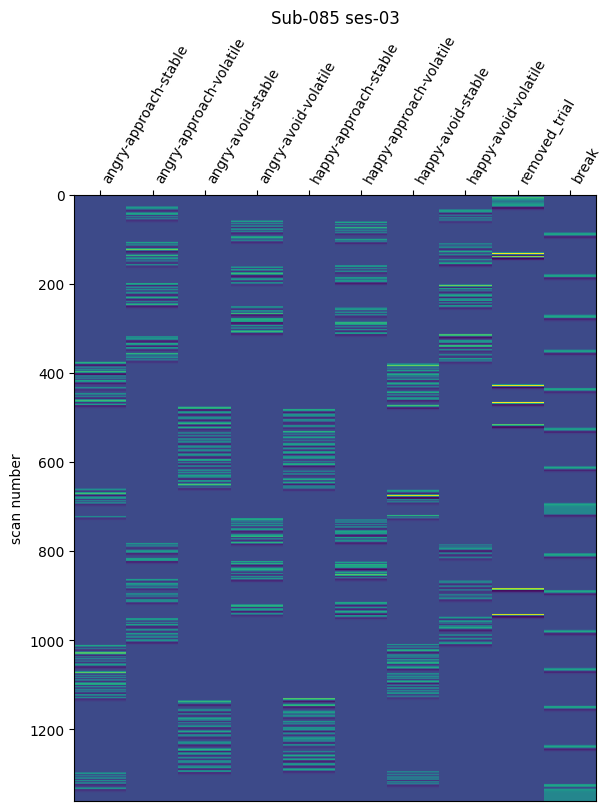

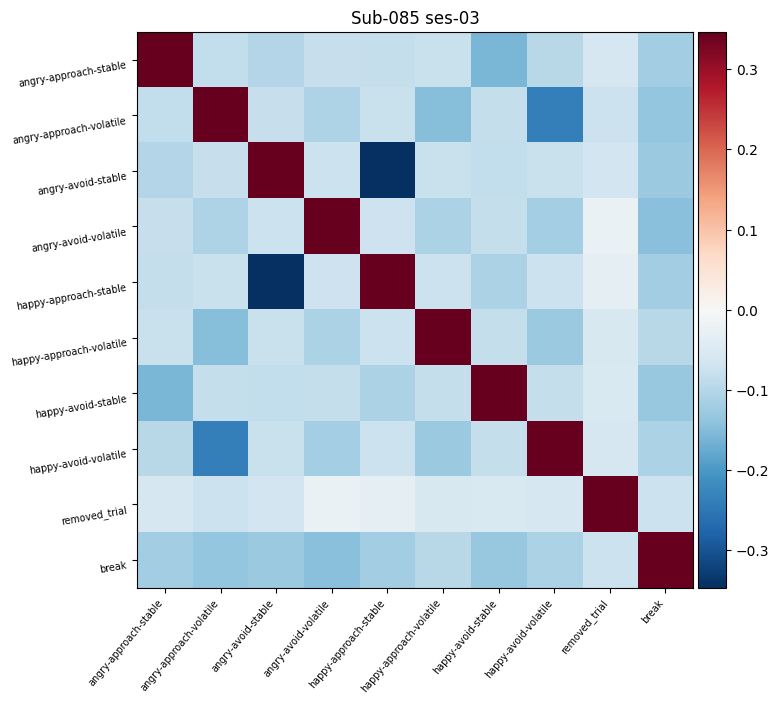

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

fMRIprep has not yet been run for subject 85 and session 4
fMRIprep has not yet been run for subject 86 and session 2
fMRIprep has not yet been run for subject 86 and session 3
fMRIprep has not yet been run for subject 86 and session 4
fMRIprep has not yet been run for subject 87 and session 2
fMRIprep has not yet been run for subject 87 and session 3
fMRIprep has not yet been run for subject 87 and session 4
fMRIprep has not yet been run for subject 88 and session 2
fMRIprep has not yet been run for subject 88 and session 3
fMRIprep has not yet been run for subject 88 and session 4

/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Duplicated events were detected. Amplitudes of these events will be summed. You might want to verify your inputs.
  design_matrix = make_first_level_design_matrix(
/var/folders/bh/ld02p1_550d75y0x32dmpb540000gp/T/ipykernel_9747/1014201870.py:117: UserWarning: Matrix is singular at working precision, regularizing...
  design_matrix = make_first_level_design_matrix(


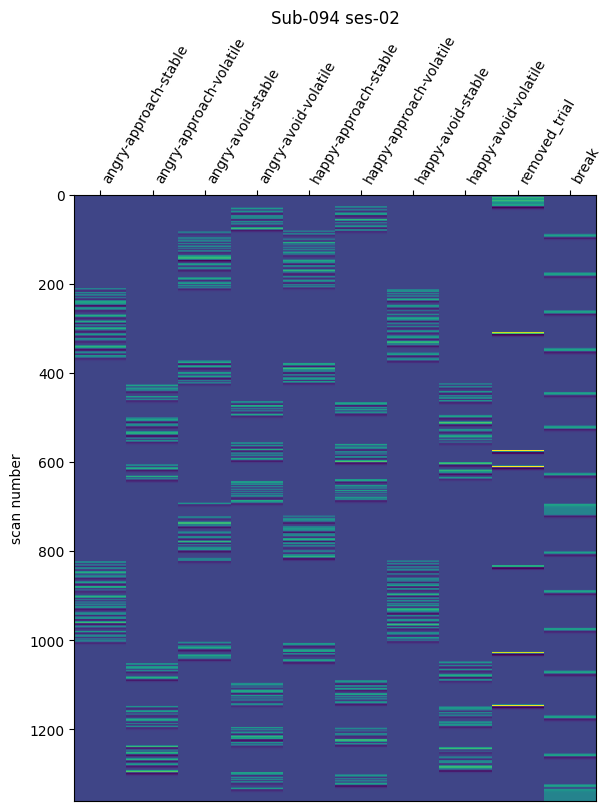

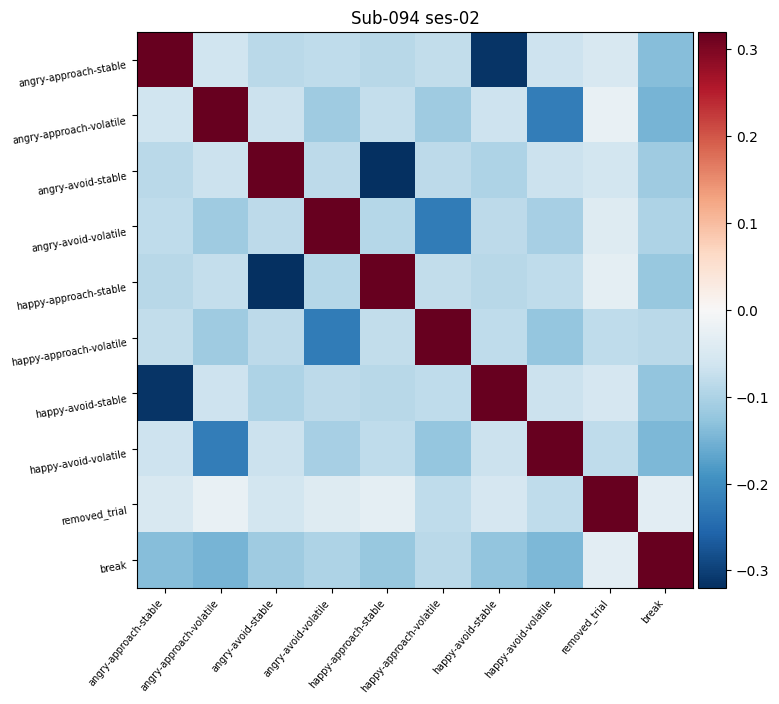

confound title: baseline_confounds
list of confounds: ['framewise_displacement', 'trans_x', 'trans_y', 'trans_z', 'rot_x', 'rot_y', 'rot_z', 'trans_x_derivative1', 'trans_y_derivative1', 'trans_z_derivative1', 'rot_x_derivative1', 'rot_y_derivative1', 'rot_z_derivative1', 'a_comp_cor_00', 'a_comp_cor_01', 'a_comp_cor_02', 'a_comp_cor_03', 'a_comp_cor_04', 'a_comp_cor_05']
0.0% of volumes have been removed.

fMRIprep has not yet been run for subject 94 and session 3
fMRIprep has not yet been run for subject 94 and session 4
fMRIprep has not yet been run for subject 95 and session 2
fMRIprep has not yet been run for subject 95 and session 3
fMRIprep has not yet been run for subject 95 and session 4


In [12]:
pd.set_option('display.max_rows', None)
feedback_duration = 0.1
# Repetition time
tr = 1.5

for subject_id in unique_subject_ids:
    for session in unique_sessions:
        # Set subject raw folder for later use:
        project_folder = '/Volumes/project/3025011.02'
        subject_raw_folder = f'{project_folder}/raw/sub-{subject_id:03}/ses-mri{session:02}'
        subject_func_folder = f'{project_folder}/bids/sub-{subject_id:03}/ses-mri{session:02}/func'
        fsl_folder = f'{project_folder}/bids/derivatives/fsl/sub-{subject_id:03}/ses-mri{session:02}/func'
        confounds_file = f'{project_folder}/bids/derivatives/fmriprep/sub-{subject_id:03}/ses-mri{session:02}/func/sub-{subject_id:03}_ses-mri{session:02}_task-AARL_desc-confounds_timeseries.tsv'
        os.makedirs(fsl_folder, exist_ok=True)

        # If participant does not have subject data yet
        if not os.path.exists(confounds_file):
            print(f'fMRIprep has not yet been run for subject {subject_id} and session {session}')
            continue
        else:
            print(f'Creating event file for subject {subject_id} and session {session}')

        # Add subject and session columns
        dataframe = combined_dataframe[combined_dataframe['subject_id'] == subject_id]
        dataframe = dataframe[dataframe['session'] == session]
        dataframe = dataframe.reset_index(drop=True)

        # Create version of comments that only contain responses, cues and feedback
        dataframe['contains_response'] = np.where(dataframe['response'].notna(), 'response', '')
        dataframe['contains_cue'] = np.where(dataframe['valence'].notna(), 'cue', '')
        feedback_binary = [
            dataframe['subjectively_correct'].isin([True, 'True']),
            dataframe['subjectively_correct'].isin([False, 'False']),
        ]
        feedback_strings = ['subjectively_correct', 'subjectively_incorrect']
        dataframe['contains_feedback'] = np.select(feedback_binary, feedback_strings, default='')

        # Combine variables
        dataframe['most_rewarding_response'] = dataframe['most_rewarding_response'].replace({'approach': 'most_rewarding_approach', 'avoid': 'most_rewarding_avoid'})
        dataframe['executed_response'] = dataframe['response'].replace({'approach': 'executed_approach', 'avoid': 'executed_avoid'})
        dataframe['cue-valence-instructed_response-volatility'] = dataframe['valence'] + '-' + dataframe['most_rewarding_response'] + '-' + dataframe['volatility']
        dataframe['cue-valence-executed_response-volatility'] = dataframe['valence'] + '-' + dataframe['executed_response'] + '-' + dataframe['volatility']

        # Determine when the scan for the first volume starts
        trigger_signals = find_trigger_file(f'trigger_signals_sub-{subject_id:03}_session-{session:02}*.csv', f'{subject_raw_folder}/beh')
        first_volume_start = trigger_signals.loc[trigger_signals['trigger'] == 1, 'trigger_time'].item()
        last_volume_start = trigger_signals.loc[trigger_signals['trigger'] == 1361, 'trigger_time'].item()
        # Note down when each trial and each response starts
        last_volume_start = last_volume_start - first_volume_start
        dataframe['emotional_cue_time'] = dataframe['emotional_cue_time'] - first_volume_start
        dataframe['response_time'] = dataframe['response_time'] - first_volume_start
        dataframe['feedback_time'] = dataframe['feedback_time'] - first_volume_start

        # Create a boxcar
        dataframe['onset'] = dataframe['emotional_cue_time']
        #dataframe['duration'] = boxcar_duration
        dataframe['duration'] = dataframe['feedback_time'] - dataframe['onset'] + feedback_duration # time that the visual feedback is shown

        # Add a regressor for breaks
        dataframe['break'] = np.where(dataframe['trial_duration'] > 10, 'break', 'no_break')
        if dataframe['trial'].max() == 451:
            dataframe.loc[451, 'break'] = 'break'
        else:
            print('Trials are missing')

        # Restructure into a time-series
        restructured_rows = []
        for _, row in dataframe.iterrows():
            restructured_rows.append({'trial_type': row['cue-valence-instructed_response-volatility'], 'onset': row['onset'], 'duration': row['duration']})
            restructured_rows.append({'trial_type': row['cue-valence-executed_response-volatility'], 'onset': row['onset'], 'duration': row['duration']})
            restructured_rows.append({'trial_type': row['removed_trial'], 'onset': row['onset'], 'duration': row['duration']})
            if row['break'] == 'break':
                print(row['trial'])
                if row['trial'] == 451:
                    break_start = row['feedback_time'] + feedback_duration
                    break_duration = last_volume_start - break_start + tr
                else:
                    break_start = row['feedback_time'] + feedback_duration + 1 # Time before break text is shown
                    break_duration = row['trial_duration'] - (break_start - row['emotional_cue_time']) - 3 # Time after which people see a blanc screen again
                restructured_rows.append({'trial_type': row['break'], 'onset': break_start, 'duration': break_duration})

        # Convert to dataframe
        data_design_matrix = pd.DataFrame(restructured_rows)
        print(data_design_matrix)

        # Now create the design matrix and save it
        events = pd.DataFrame(
            {"trial_type": data_design_matrix['trial_type'], "onset": data_design_matrix['onset'], "duration": data_design_matrix['duration']}
        )

        # Make sure that only the removed trials get their own regressor
        events = events[events['trial_type'] != 'non-removed_trial']
        events = events[events['trial_type'].notna()]
        print(events)
        # BIDS compliant event file that FSL doesn't use
        #events.to_csv(os.path.join(f'{subject_func_folder}/sub-{subject_id:03}_ses-mri{session:02}_task-AARL_events.tsv'), sep='\t')

        # Scans timing
        # This method takes the actual triggers instead of assuming that the TR = 1.5 and that no scans are missed
        n_triggers = len(trigger_signals)
        trigger_timepoints = trigger_signals['trigger_time'] - first_volume_start
        trigger_timepoints = trigger_timepoints.tolist()

        # Look up number of volumes (since it's multi-echo, we need to divide by 3)
        raw_bold_folder = next(Path(subject_raw_folder).glob('*-TaskAARL'))  # this silently picks on of the folders if two exists
        # Count .IMA files to check if it matches the number of triggers
        ima_files = list(raw_bold_folder.glob('*.IMA'))
        n_volumes = int(len(ima_files) / 3)
        volume_timepoints = np.arange(0, n_volumes) * tr

        if n_triggers != n_volumes:
            raise ValueError(
                f'Number of triggers ({n_triggers}) does not match the number of IMA files ({n_volumes})'
            )

        # fit the hemodynamic response function to the event file
        design_matrix = make_first_level_design_matrix(
            np.array(trigger_timepoints),
            data_design_matrix
        )

        # Explicitly reorder columns
        design_matrix.rename(columns={'angry-most_rewarding_approach-stable': 'angry-approach-stable', 'angry-most_rewarding_approach-volatile': 'angry-approach-volatile', 'angry-most_rewarding_avoid-stable': 'angry-avoid-stable', 'angry-most_rewarding_avoid-volatile': 'angry-avoid-volatile', 'happy-most_rewarding_approach-stable': 'happy-approach-stable', 'happy-most_rewarding_approach-volatile': 'happy-approach-volatile', 'happy-most_rewarding_avoid-stable': 'happy-avoid-stable', 'happy-most_rewarding_avoid-volatile': 'happy-avoid-volatile'}, inplace=True)
        design_matrix = design_matrix[['angry-approach-stable', 'angry-approach-volatile', 'angry-avoid-stable', 'angry-avoid-volatile', 'happy-approach-stable', 'happy-approach-volatile', 'happy-avoid-stable', 'happy-avoid-volatile', 'removed_trial', 'break']]

        # Plot said matrix and save it
        fig, ax = plt.subplots(figsize=(6, 8), constrained_layout=True)
        plot_design_matrix(design_matrix, axes=ax)
        ax.set_title(f'Sub-{subject_id:03} ses-{session:02}')
        plt.savefig(os.path.join(output_dir, f'design_matrix_sub-{subject_id:03}_ses-mri{session:02}.pdf'))

        # Now also plot the correlation matrix and save it
        fig, ax = plt.subplots(figsize=(8, 8), constrained_layout=True)
        plot_design_matrix_correlation(design_matrix, axes=ax)
        ax.set_title(f'Sub-{subject_id:03} ses-{session:02}')
        plt.savefig(os.path.join(output_dir, f'regression_correlation_matrix_sub-{subject_id:03}_ses-mri{session:02}.pdf'))
        plt.show()
        # And save a CSV version of it
        correlation_matrix = design_matrix.corr()
        correlation_matrix.round(3).to_csv(os.path.join(output_dir, f'regression_correlation_matrix_sub-{subject_id:03}_ses-mri{session:02}.csv'), sep=';')

        # Because FSL can only accept an event file with one variable in there, we will now split them up
        for trials_type in events['trial_type'].unique():
            trial_specific_events = events[events['trial_type'] == trials_type]
            trial_specific_events = trial_specific_events[['onset', 'duration']].copy()
            trial_specific_events['weight'] = 1.0
            trial_specific_events.to_csv(f'{fsl_folder}/sub-{subject_id:03}_ses-mri{session:02}_task-AARL_regressor_{trials_type}.txt', sep='\t', index=False, header=False)

        # Now select the confounds you want to copy into the FEAT analysis
        confounds_raw = pd.read_csv(confounds_file, sep='\t') # Location of fMRIprep results

        # Different confound combinations
        confound_names = ['baseline_confounds']#['a_blanc', 'b_framewise_displacement', 'c_trans_rot', 'd_derivative1', 'e_power2', 'f_a_comp_cor', 'g_dvars', 'h_std_dvars', 'i_rmsd']
        confound_list = [['framewise_displacement', 'trans_x','trans_y','trans_z','rot_x','rot_y','rot_z', 'trans_x_derivative1','trans_y_derivative1','trans_z_derivative1','rot_x_derivative1','rot_y_derivative1','rot_z_derivative1', 'a_comp_cor_00','a_comp_cor_01','a_comp_cor_02','a_comp_cor_03','a_comp_cor_04','a_comp_cor_05']]#, 'non_steady_state_outlier00', 'non_steady_state_outlier01']]#[[],
 #                        ['framewise_displacement'],
  #               ['framewise_displacement', 'trans_x','trans_y','trans_z','rot_x','rot_y','rot_z'],
   #              ['framewise_displacement', 'trans_x','trans_y','trans_z','rot_x','rot_y','rot_z', 'trans_x_derivative1','trans_y_derivative1','trans_z_derivative1','rot_x_derivative1','rot_y_derivative1','rot_z_derivative1'],
    #             ['framewise_displacement', 'trans_x','trans_y','trans_z','rot_x','rot_y','rot_z', 'trans_x_derivative1','trans_y_derivative1','trans_z_derivative1','rot_x_derivative1','rot_y_derivative1','rot_z_derivative1', 'trans_x_power2','trans_y_power2','trans_z_power2','rot_x_power2','rot_y_power2','rot_z_power2'],
     #            ['framewise_displacement', 'trans_x','trans_y','trans_z','rot_x','rot_y','rot_z', 'trans_x_derivative1','trans_y_derivative1','trans_z_derivative1','rot_x_derivative1','rot_y_derivative1','rot_z_derivative1', 'trans_x_power2','trans_y_power2','trans_z_power2','rot_x_power2','rot_y_power2','rot_z_power2', 'a_comp_cor_00','a_comp_cor_01','a_comp_cor_02','a_comp_cor_03','a_comp_cor_04','a_comp_cor_05'],
      #           ['framewise_displacement', 'trans_x','trans_y','trans_z','rot_x','rot_y','rot_z', 'trans_x_derivative1','trans_y_derivative1','trans_z_derivative1','rot_x_derivative1','rot_y_derivative1','rot_z_derivative1', 'trans_x_power2','trans_y_power2','trans_z_power2','rot_x_power2','rot_y_power2','rot_z_power2', 'a_comp_cor_00','a_comp_cor_01','a_comp_cor_02','a_comp_cor_03','a_comp_cor_04','a_comp_cor_05', 'dvars'],
       #          ['framewise_displacement', 'trans_x','trans_y','trans_z','rot_x','rot_y','rot_z', 'trans_x_derivative1','trans_y_derivative1','trans_z_derivative1','rot_x_derivative1','rot_y_derivative1','rot_z_derivative1', 'trans_x_power2','trans_y_power2','trans_z_power2','rot_x_power2','rot_y_power2','rot_z_power2', 'a_comp_cor_00','a_comp_cor_01','a_comp_cor_02','a_comp_cor_03','a_comp_cor_04','a_comp_cor_05', 'dvars', 'std_dvars'],
        #         ['framewise_displacement', 'trans_x','trans_y','trans_z','rot_x','rot_y','rot_z', 'trans_x_derivative1','trans_y_derivative1','trans_z_derivative1','rot_x_derivative1','rot_y_derivative1','rot_z_derivative1', 'trans_x_power2','trans_y_power2','trans_z_power2','rot_x_power2','rot_y_power2','rot_z_power2', 'a_comp_cor_00','a_comp_cor_01','a_comp_cor_02','a_comp_cor_03','a_comp_cor_04','a_comp_cor_05', 'dvars', 'std_dvars', 'rmsd']]
                    #cosine regressors? they're more likely to remove block based effects from stable blocks

        # Loop through the combinations
        for n_confound, confound in enumerate(confound_names):
            if not confound_list[n_confound]:
                confounds_for_feat = pd.DataFrame({'column_name': 0}, index=range(len(confounds_raw))) # Using both the FD and the spike regressors might be redundant
            else:
                print(f'confound title: {confound}')
                print(f'list of confounds: {confound_list[n_confound]}')
                confounds_for_feat = confounds_raw[confound_list[n_confound]]

            confounds_for_feat = confounds_for_feat.fillna(0)

            # Create new columns for every volume where framewise_displacement is exceeded
            if 'framewise_displacement' in confounds_for_feat.columns:
                exceeded_rows = confounds_for_feat.index[confounds_for_feat['framewise_displacement'] > framewise_displacement_limit]
                print(f'{100* (len(exceeded_rows) / len(confounds_for_feat["framewise_displacement"]))}% of volumes have been removed.\n')
                for i, row_idx in enumerate(exceeded_rows, start=1):
                    col_name = f'framewise_displacement_exceeded_{i}'
                    confounds_for_feat[col_name] = 0
                    confounds_for_feat.loc[row_idx, col_name] = 1

            confounds_for_feat.to_csv(f'{fsl_folder}/sub-{subject_id:03}_ses-mri{session:02}_task-AARL_confounds_for_feat_{confound_names[n_confound]}.txt', sep='\t', index=False, header=False)